# 02 · Preprocessing, modelling and evaluation (PVGIS data)

EDA → preprocessing → baselines → Bayesian Optimization → Ridge stacking → paired tests → five-seed evaluation (random split, time-based split, leave-one-city-out) → ablation, feature importance, SHAP, error analysis and annual production.

The saved outputs are those of the runs reported in the paper. The README lists which section produces each table and figure.

Input: `DATA_DIR/pvgis_indonesia_solar_dataset.csv` from notebook 01.

In [ ]:
# ============================================================
# CONFIGURATION: set DATA_DIR before running anything else
# ============================================================
import os

DATA_DIR = 'data'   # local run: folder that holds the input CSV and all outputs

try:                # Google Colab: mount Drive and point DATA_DIR to your Drive folder
    from google.colab import drive
    drive.mount('/content/drive')
    DATA_DIR = '/content/drive/MyDrive/<your-folder>'   # <-- change to your own Drive folder
except ImportError:
    pass

for sub in ['', 'tuning', 'stacking', 'multiseed', 'measured']:
    os.makedirs(os.path.join(DATA_DIR, sub), exist_ok=True)
print('DATA_DIR =', os.path.abspath(DATA_DIR))

## 1. Data understanding (exploratory analysis)

In [ ]:
!pip install pandas numpy matplotlib seaborn -q

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.size']  = 10

In [ ]:
df = pd.read_csv(f'{DATA_DIR}/pvgis_indonesia_solar_dataset.csv')
df['datetime_local'] = pd.to_datetime(df['datetime_local'])
df['datetime_utc']   = pd.to_datetime(df['datetime_utc'])

print(f'Dataset berhasil dimuat.')
print(f'Shape : {df.shape[0]:,} baris × {df.shape[1]} kolom')
print(f'Kota  : {sorted(df["city"].unique())}')
print(f'Tahun : {sorted(df["year"].unique())}')

Dataset berhasil dimuat.
Shape : 306,768 baris × 20 kolom
Kota  : ['Jakarta', 'Jayapura', 'Kupang', 'Makassar', 'Medan', 'Pontianak', 'Surabaya']
Tahun : [np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024)]


In [ ]:
print('=== Info Dataset ===')
df.info()
print('\n=== 5 Baris Pertama ===')
df.head()

=== Info Dataset ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 306768 entries, 0 to 306767
Data columns (total 20 columns):
 #   Column          Non-Null Count   Dtype         
---  ------          --------------   -----         
 0   datetime_utc    306768 non-null  datetime64[ns]
 1   datetime_local  306768 non-null  datetime64[ns]
 2   city            306768 non-null  object        
 3   latitude        306768 non-null  float64       
 4   longitude       306768 non-null  float64       
 5   tz_offset       306768 non-null  int64         
 6   year            306768 non-null  int64         
 7   month           306768 non-null  int64         
 8   day             306768 non-null  int64         
 9   hour            306768 non-null  int64         
 10  season          306768 non-null  object        
 11  irr_total       306768 non-null  float64       
 12  irr_beam        306768 non-null  float64       
 13  irr_diffuse     306768 non-null  float64       
 14  irr_reflect    

,datetime_utc,datetime_local,city,latitude,longitude,tz_offset,year,month,day,hour,season,irr_total,irr_beam,irr_diffuse,irr_reflect,temp_air,wind_speed,sun_height,P_kW,flag
0,2019-01-01 00:30:00,2019-01-01 07:30:00,Medan,3.5952,98.6722,7,2019,1,1,7,wet,146.09,65.76,80.14,0.19,23.36,1.66,12.60,0.09764,0.0
1,2019-01-01 01:30:00,2019-01-01 08:30:00,Medan,3.5952,98.6722,7,2019,1,1,8,wet,353.86,208.08,145.29,0.49,24.46,1.72,26.05,0.27097,0.0
2,2019-01-01 02:30:00,2019-01-01 09:30:00,Medan,3.5952,98.6722,7,2019,1,1,9,wet,543.31,337.46,205.08,0.77,25.98,2.28,38.95,0.42113,0.0
3,2019-01-01 03:30:00,2019-01-01 10:30:00,Medan,3.5952,98.6722,7,2019,1,1,10,wet,523.74,236.94,286.04,0.76,27.04,2.62,50.68,0.40448,0.0
4,2019-01-01 04:30:00,2019-01-01 11:30:00,Medan,3.5952,98.6722,7,2019,1,1,11,wet,661.79,352.14,308.69,0.96,27.54,2.14,59.78,0.50409,0.0


Missing values and duplicates

In [ ]:
print('=== Missing Value per Kolom ===')
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_df = pd.DataFrame({'Jumlah': missing, 'Persentase (%)': missing_pct})
print(missing_df[missing_df['Jumlah'] > 0].to_string() if missing_df['Jumlah'].sum() > 0 else 'Tidak ada missing value.')

print(f'\n=== Duplikat ===')
n_dup = df.duplicated().sum()
print(f'Jumlah baris duplikat : {n_dup}')

=== Missing Value per Kolom ===
Tidak ada missing value.

=== Duplikat ===
Jumlah baris duplikat : 0


Descriptive statistics

In [ ]:
num_cols = ['irr_total', 'irr_beam', 'irr_diffuse', 'irr_reflect',
            'temp_air', 'wind_speed', 'sun_height', 'P_kW']
num_cols = [c for c in num_cols if c in df.columns]

desc = df[num_cols].describe().T
desc.columns = ['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max']
desc = desc.round(4)
print('=== Statistik Deskriptif Kolom Numerik ===')
desc

=== Statistik Deskriptif Kolom Numerik ===


,count,mean,std,min,25%,50%,75%,max
irr_total,306768.0,207.5254,282.0012,0.00,0.00,4.515,407.0800,1088.5500
irr_beam,306768.0,135.4738,212.6426,0.00,0.00,0.000,221.0625,981.6700
irr_diffuse,306768.0,71.7276,94.6410,0.00,0.00,4.480,130.2525,476.3200
irr_reflect,306768.0,0.3241,0.4392,0.00,0.00,0.010,0.6400,1.6600
temp_air,306768.0,26.3435,2.4471,18.54,24.48,25.920,28.0500,36.9600
wind_speed,306768.0,1.6311,1.0538,0.00,0.90,1.380,2.0700,10.9700
sun_height,306768.0,20.4946,26.4093,-7.39,0.00,0.060,42.3800,89.9000
P_kW,306768.0,0.1538,0.2118,0.00,0.00,0.000,0.3092,0.7822


Night-time (irr_total = 0) vs daytime rows

=== Distribusi Data Siang vs Malam ===
Data malam (irr_total = 0) : 153,246 baris (50.0%)
Data siang (irr_total > 0) : 153,522 baris (50.0%)
Total                      : 306,768 baris


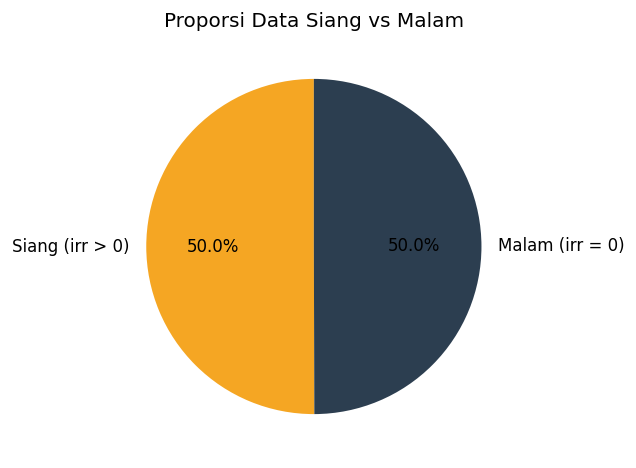

In [ ]:
n_malam  = (df['irr_total'] == 0).sum()
n_siang  = (df['irr_total'] >  0).sum()
total    = len(df)

print('=== Distribusi Data Siang vs Malam ===')
print(f'Data malam (irr_total = 0) : {n_malam:,} baris ({n_malam/total*100:.1f}%)')
print(f'Data siang (irr_total > 0) : {n_siang:,} baris ({n_siang/total*100:.1f}%)')
print(f'Total                      : {total:,} baris')

fig, ax = plt.subplots(figsize=(5, 4))
ax.pie([n_siang, n_malam],
       labels=['Siang (irr > 0)', 'Malam (irr = 0)'],
       autopct='%1.1f%%',
       colors=['#F5A623', '#2C3E50'],
       startangle=90)
ax.set_title('Proporsi Data Siang vs Malam')
plt.tight_layout()
plt.show()

Distribution of `P_kW` (daytime rows); defines `df_siang` used below

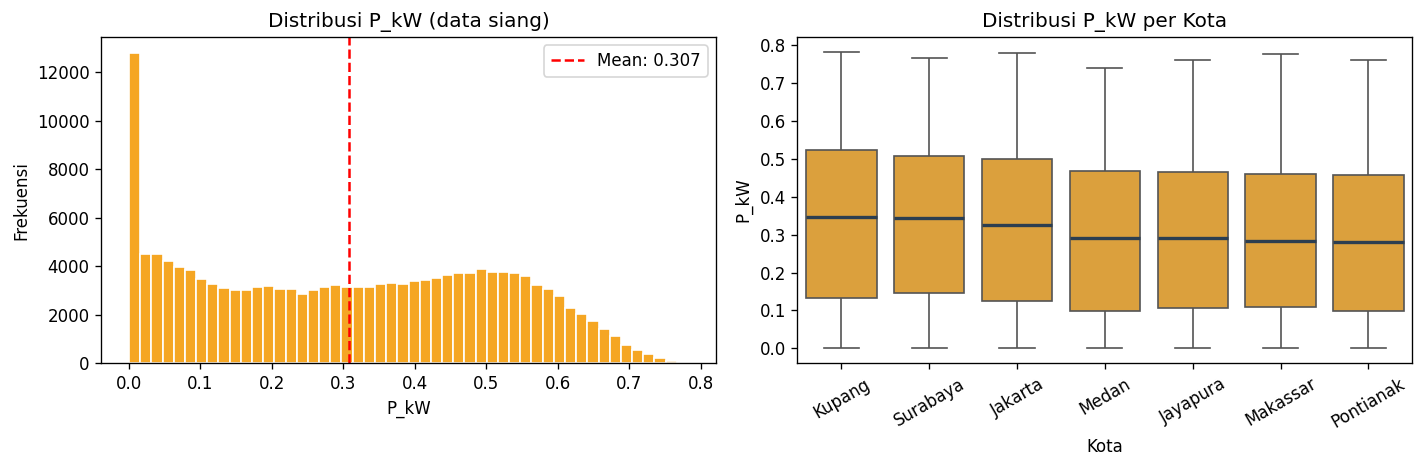

In [ ]:
df_siang = df[df['irr_total'] > 0].copy()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Histogram
axes[0].hist(df_siang['P_kW'], bins=50, color='#F5A623', edgecolor='white')
axes[0].set_title('Distribusi P_kW (data siang)')
axes[0].set_xlabel('P_kW')
axes[0].set_ylabel('Frekuensi')
axes[0].axvline(df_siang['P_kW'].mean(), color='red', linestyle='--', label=f"Mean: {df_siang['P_kW'].mean():.3f}")
axes[0].legend()

# Boxplot per kota — pakai seaborn agar bisa diurutkan
city_order = df_siang.groupby('city')['P_kW'].median().sort_values(ascending=False).index.tolist()
sns.boxplot(data=df_siang, x='city', y='P_kW', order=city_order,
            ax=axes[1], color='#F5A623',
            medianprops=dict(color='#2C3E50', linewidth=2))
axes[1].set_title('Distribusi P_kW per Kota')
axes[1].set_xlabel('Kota')
axes[1].set_ylabel('P_kW')
axes[1].tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()

Mean PV output by hour of day (local time)

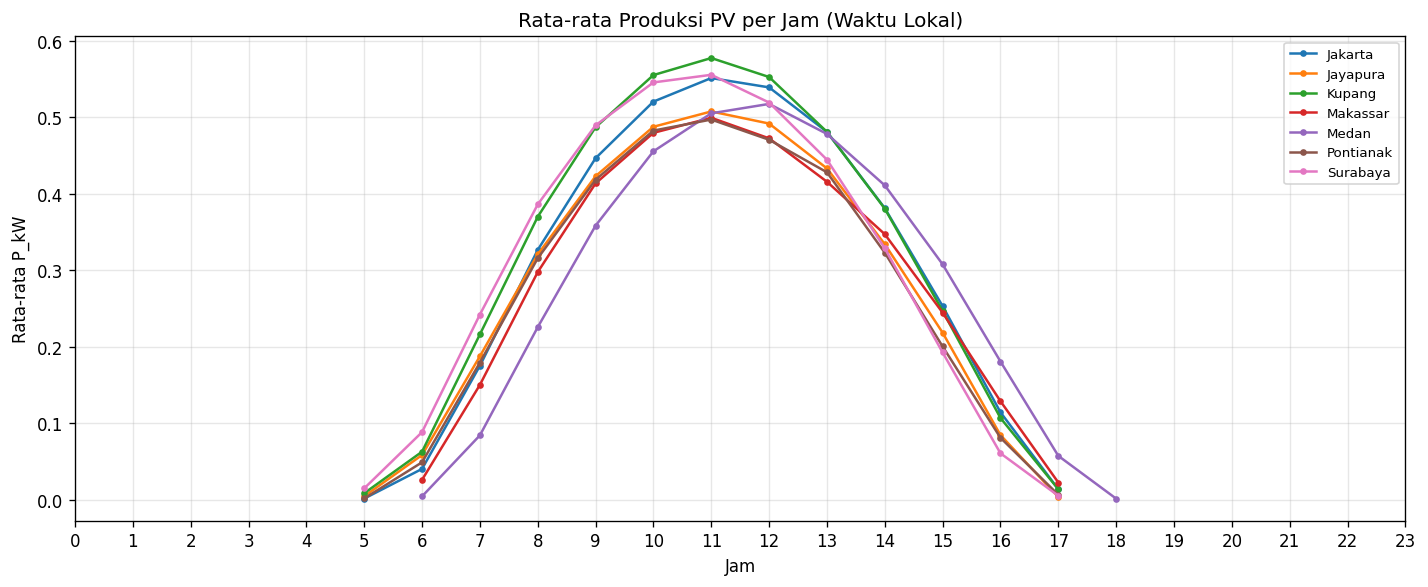

In [ ]:
hourly_avg = df_siang.groupby(['city', 'hour'])['P_kW'].mean().reset_index()

fig, ax = plt.subplots(figsize=(12, 5))
colors = plt.cm.tab10.colors
for i, city in enumerate(sorted(df_siang['city'].unique())):
    subset = hourly_avg[hourly_avg['city'] == city]
    ax.plot(subset['hour'], subset['P_kW'], marker='o', markersize=3,
            label=city, color=colors[i])

ax.set_title('Rata-rata Produksi PV per Jam (Waktu Lokal)')
ax.set_xlabel('Jam')
ax.set_ylabel('Rata-rata P_kW')
ax.set_xticks(range(0, 24))
ax.legend(loc='upper right', fontsize=8)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Mean PV output by month

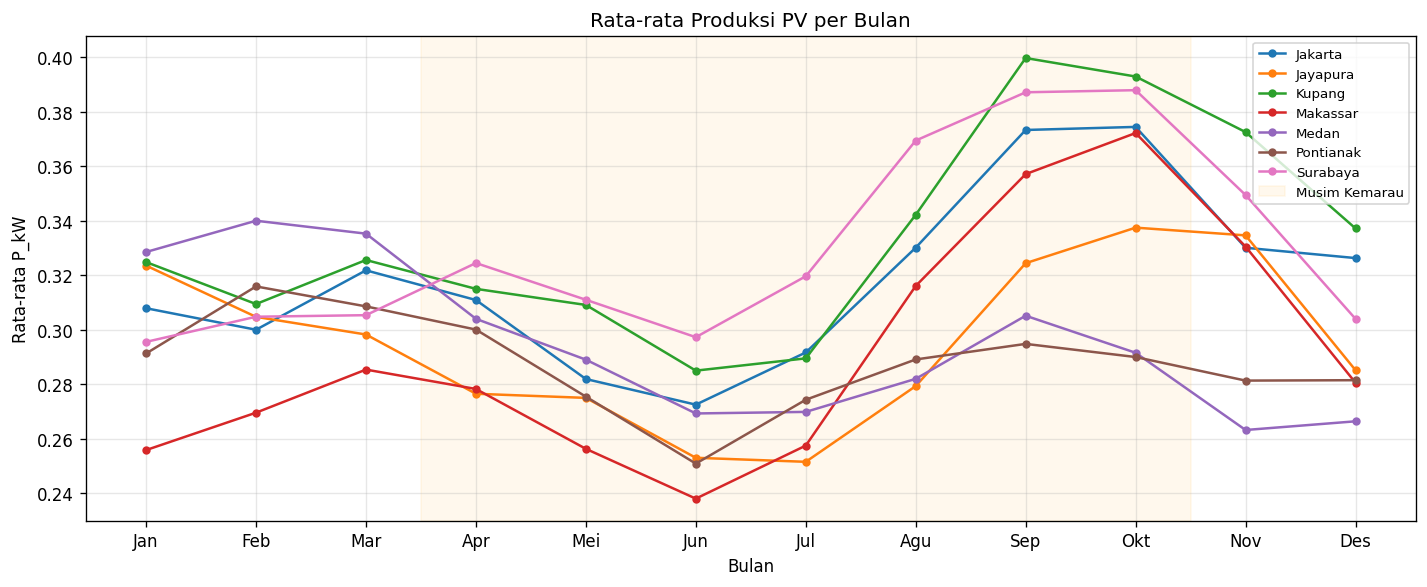

In [ ]:
monthly_avg = df_siang.groupby(['city', 'month'])['P_kW'].mean().reset_index()

fig, ax = plt.subplots(figsize=(12, 5))
for i, city in enumerate(sorted(df_siang['city'].unique())):
    subset = monthly_avg[monthly_avg['city'] == city]
    ax.plot(subset['month'], subset['P_kW'], marker='o', markersize=4,
            label=city, color=colors[i])

ax.set_title('Rata-rata Produksi PV per Bulan')
ax.set_xlabel('Bulan')
ax.set_ylabel('Rata-rata P_kW')
ax.set_xticks(range(1, 13))
ax.set_xticklabels(['Jan','Feb','Mar','Apr','Mei','Jun',
                     'Jul','Agu','Sep','Okt','Nov','Des'])
ax.axvspan(3.5, 10.5, alpha=0.07, color='orange', label='Musim Kemarau')
ax.legend(loc='upper right', fontsize=8)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Pearson correlation of the features with `P_kW` (Fig. 2)

=== Korelasi Fitur terhadap P_kW ===
  irr_total       : +0.9988  ███████████████████
  irr_reflect     : +0.9941  ███████████████████
  irr_beam        : +0.9436  ██████████████████
  sun_height      : +0.8731  █████████████████
  temp_air        : +0.6057  ████████████
  irr_diffuse     : +0.5800  ███████████
  wind_speed      : +0.1403  ██
  month           : +0.0408  
  hour            : -0.0764  █


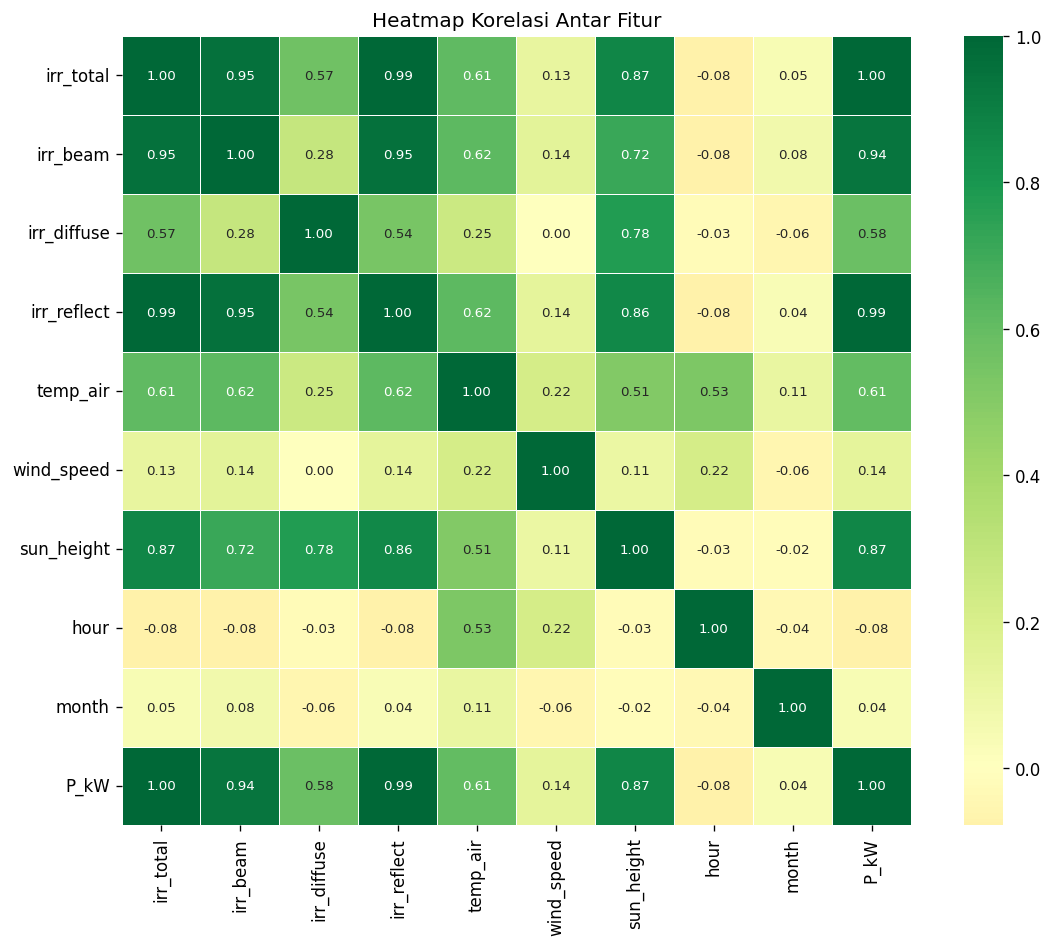

In [ ]:
corr_cols = ['irr_total', 'irr_beam', 'irr_diffuse', 'irr_reflect',
             'temp_air', 'wind_speed', 'sun_height', 'hour', 'month', 'P_kW']
corr_cols = [c for c in corr_cols if c in df_siang.columns]

corr_matrix = df_siang[corr_cols].corr()

# Korelasi terhadap P_kW saja
corr_target = corr_matrix['P_kW'].drop('P_kW').sort_values(ascending=False)
print('=== Korelasi Fitur terhadap P_kW ===')
for feat, val in corr_target.items():
    bar = '█' * int(abs(val) * 20)
    print(f'  {feat:15} : {val:+.4f}  {bar}')

# Heatmap
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='RdYlGn',
            center=0, square=True, linewidths=0.5, ax=ax,
            annot_kws={'size': 8})
ax.set_title('Heatmap Korelasi Antar Fitur')
plt.tight_layout()
plt.show()

Outliers (motivates percentile clipping)

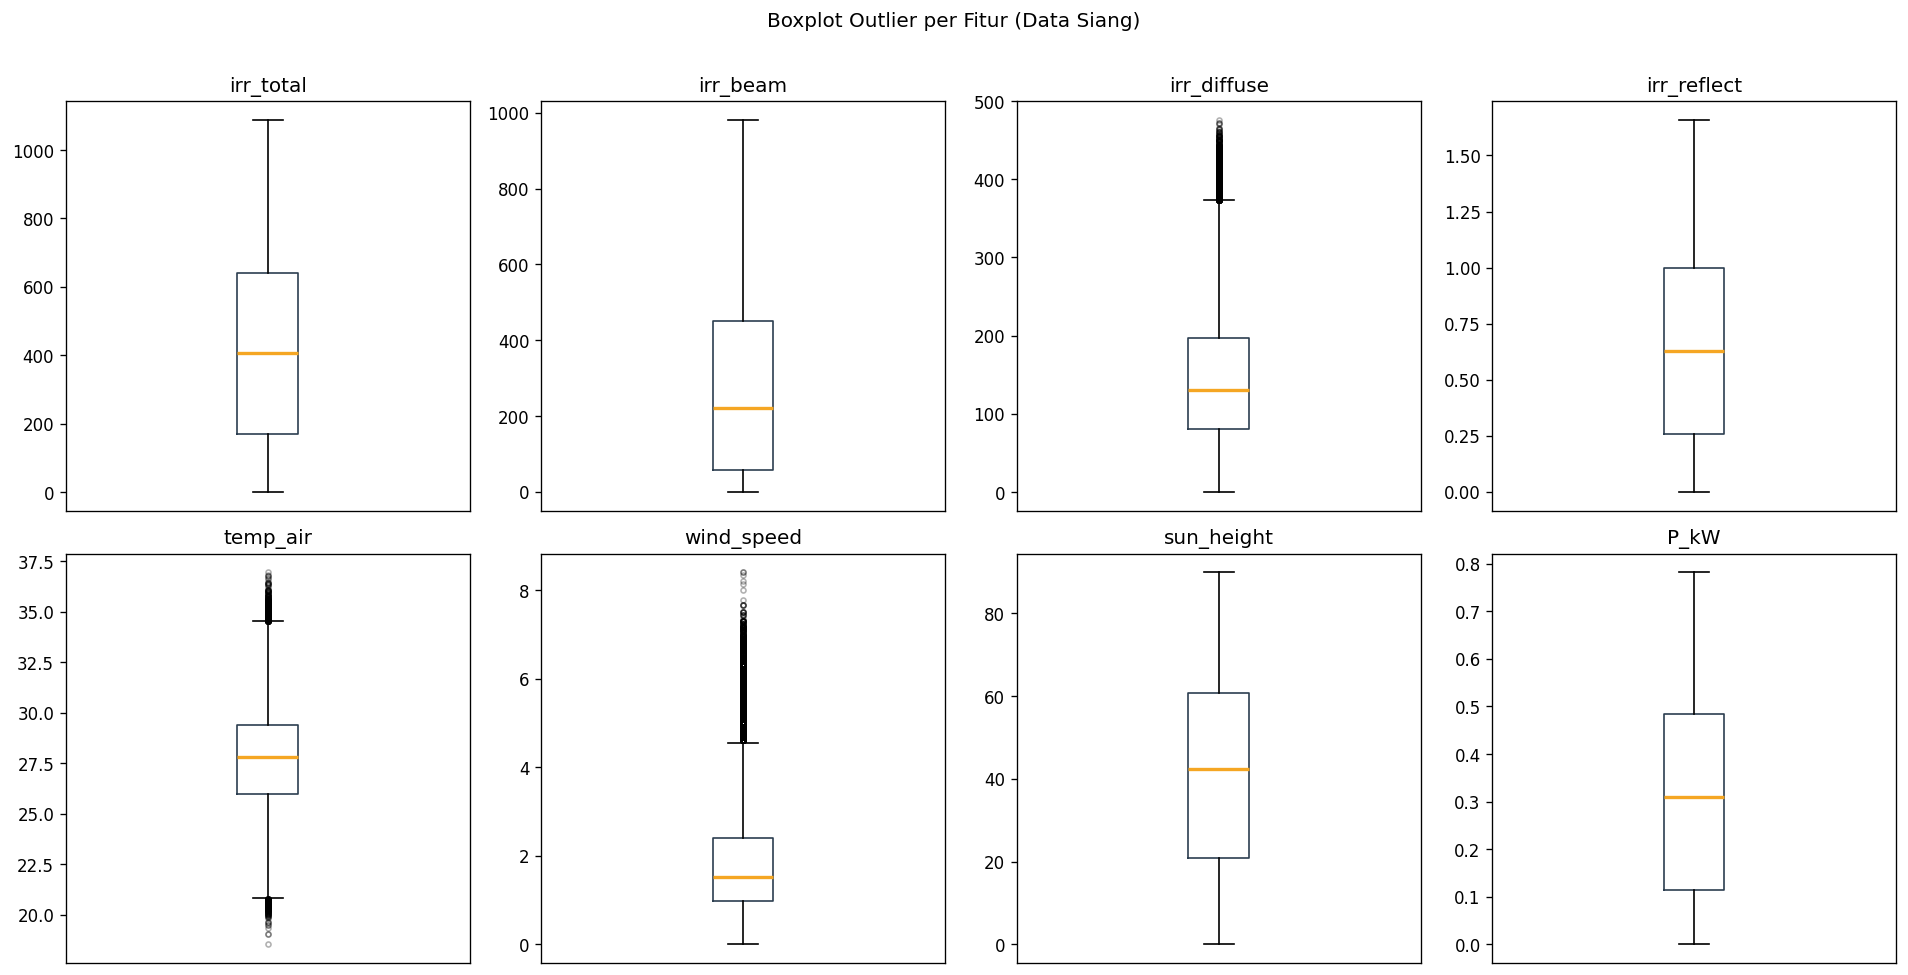


Nilai temp_air > 100°C (corrupt) : 0 baris


In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

plot_cols = ['irr_total', 'irr_beam', 'irr_diffuse', 'irr_reflect',
             'temp_air', 'wind_speed', 'sun_height', 'P_kW']
plot_cols = [c for c in plot_cols if c in df_siang.columns]

for i, col in enumerate(plot_cols):
    axes[i].boxplot(df_siang[col].dropna(), vert=True,
                    boxprops=dict(color='#2C3E50'),
                    medianprops=dict(color='#F5A623', linewidth=2),
                    flierprops=dict(marker='.', color='red', alpha=0.3))
    axes[i].set_title(col)
    axes[i].set_xticks([])

for j in range(len(plot_cols), len(axes)):
    fig.delaxes(axes[j])

plt.suptitle('Boxplot Outlier per Fitur (Data Siang)', fontsize=12, y=1.01)
plt.tight_layout()
plt.show()

# Cek nilai corrupt temp_air
n_corrupt = (df_siang['temp_air'] > 100).sum()
print(f'\nNilai temp_air > 100°C (corrupt) : {n_corrupt} baris')

Rows per city and per year

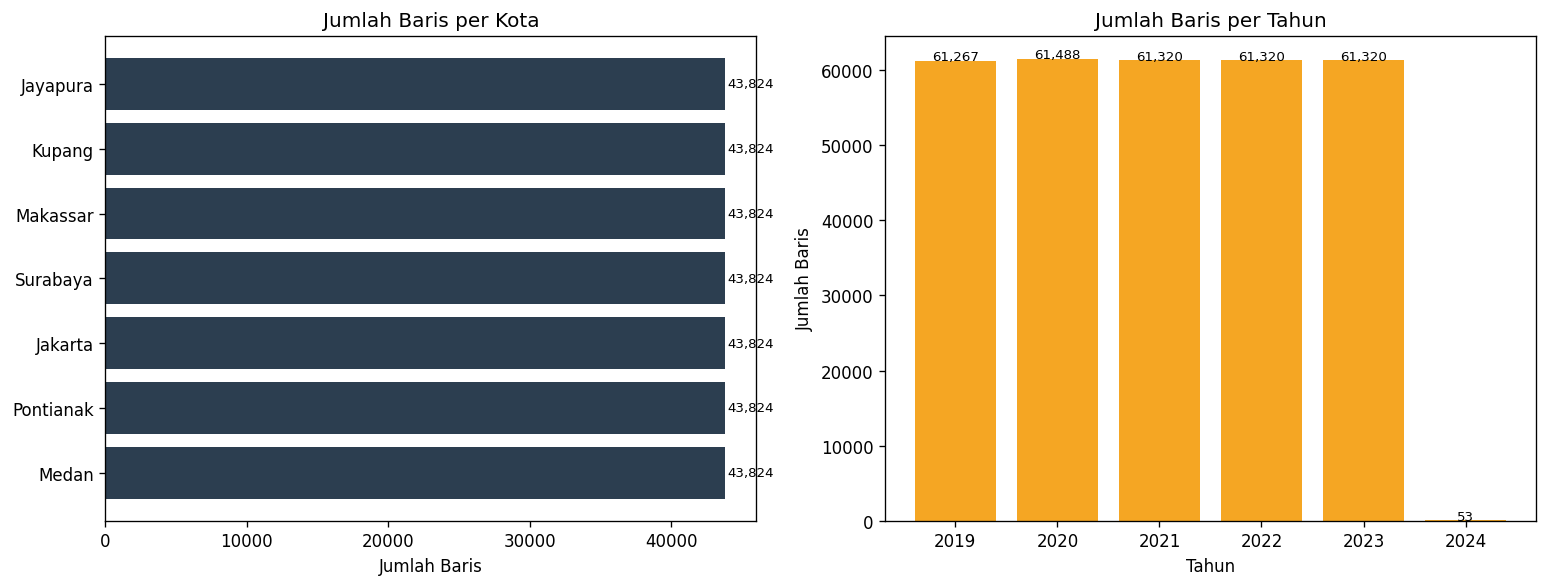

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Per kota
city_counts = df['city'].value_counts().sort_values(ascending=True)
axes[0].barh(city_counts.index, city_counts.values, color='#2C3E50')
axes[0].set_title('Jumlah Baris per Kota')
axes[0].set_xlabel('Jumlah Baris')
for i, v in enumerate(city_counts.values):
    axes[0].text(v + 100, i, f'{v:,}', va='center', fontsize=8)

# Per tahun
year_counts = df['year'].value_counts().sort_index()
axes[1].bar(year_counts.index.astype(str), year_counts.values, color='#F5A623')
axes[1].set_title('Jumlah Baris per Tahun')
axes[1].set_xlabel('Tahun')
axes[1].set_ylabel('Jumlah Baris')
for i, (x, v) in enumerate(zip(year_counts.index, year_counts.values)):
    axes[1].text(i, v + 100, f'{v:,}', ha='center', fontsize=8)

plt.tight_layout()
plt.show()

In [ ]:
n_total   = len(df)
n_malam   = (df['irr_total'] == 0).sum()
n_corrupt = (df['temp_air'] > 100).sum()
n_dup     = df.duplicated().sum()
n_missing = df.isnull().sum().sum()
top_corr  = corr_target.abs().idxmax()
top_corr_val = corr_target.abs().max()

print('=' * 60)
print('RINGKASAN TEMUAN EDA')
print('=' * 60)
print(f'Total data                : {n_total:,} baris')
print(f'Kota                      : {df["city"].nunique()} kota')
print(f'Rentang tahun             : {df["year"].min()} – {df["year"].max()}')
print(f'')
print(f'Missing value             : {n_missing}')
print(f'Duplikat                  : {n_dup}')
print(f'Data malam (irr = 0)      : {n_malam:,} baris ({n_malam/n_total*100:.1f}%) → akan di-drop')
print(f'Corrupt temp_air (>100°C) : {n_corrupt} baris → akan di-drop')
print(f'')
print(f'Fitur paling berkorelasi  : {top_corr} (r = {top_corr_val:.4f})')
print(f'P_kW min                  : {df["P_kW"].min():.4f} kW')
print(f'P_kW max                  : {df["P_kW"].max():.4f} kW')
print(f'P_kW mean                 : {df["P_kW"].mean():.4f} kW')
print('=' * 60)
print('Dataset siap masuk ke tahap Data Preparation (Preprocessing).')

RINGKASAN TEMUAN EDA
Total data                : 306,768 baris
Kota                      : 7 kota
Rentang tahun             : 2019 – 2024

Missing value             : 0
Duplikat                  : 0
Data malam (irr = 0)      : 153,246 baris (50.0%) → akan di-drop
Corrupt temp_air (>100°C) : 0 baris → akan di-drop

Fitur paling berkorelasi  : irr_total (r = 0.9988)
P_kW min                  : 0.0000 kW
P_kW max                  : 0.7822 kW
P_kW mean                 : 0.1538 kW
Dataset siap masuk ke tahap Data Preparation (Preprocessing).


## 2. Data preparation

In [ ]:
!pip install pandas numpy scikit-learn -q

import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
import warnings
warnings.filterwarnings('ignore')

In [ ]:
df = pd.read_csv(f'{DATA_DIR}/pvgis_indonesia_solar_dataset.csv')
print(f'Dataset berhasil dimuat.')
print(f'Shape awal : {df.shape[0]:,} baris x {df.shape[1]} kolom')
print(f'Kolom      : {list(df.columns)}')

Dataset berhasil dimuat.
Shape awal : 306,768 baris x 20 kolom
Kolom      : ['datetime_utc', 'datetime_local', 'city', 'latitude', 'longitude', 'tz_offset', 'year', 'month', 'day', 'hour', 'season', 'irr_total', 'irr_beam', 'irr_diffuse', 'irr_reflect', 'temp_air', 'wind_speed', 'sun_height', 'P_kW', 'flag']


### 2.1 UTC → local time

`year`, `month`, `day` and `hour` are rebuilt from `datetime_local`.

In [ ]:
df['datetime_utc']   = pd.to_datetime(df['datetime_utc'])
df['datetime_local'] = pd.to_datetime(df['datetime_local'])

# Rebuild kolom temporal dari datetime_local untuk konsistensi
df['year']  = df['datetime_local'].dt.year
df['month'] = df['datetime_local'].dt.month
df['day']   = df['datetime_local'].dt.day
df['hour']  = df['datetime_local'].dt.hour

print('Konversi datetime selesai.')
print(f'Rentang waktu lokal : {df["datetime_local"].min()} s/d {df["datetime_local"].max()}')
print(f'Tahun unik          : {sorted(df["year"].unique())}')

Konversi datetime selesai.
Rentang waktu lokal : 2019-01-01 07:30:00 s/d 2024-01-01 08:30:00
Tahun unik          : [np.int32(2019), np.int32(2020), np.int32(2021), np.int32(2022), np.int32(2023), np.int32(2024)]


### 2.2 Cleaning

Night-time rows (`irr_total = 0`) and four rows shifted into 2024 by the time-zone conversion are removed (153,518 rows remain).

In [ ]:
before = len(df)

# Drop data malam (irr_total = 0)
n_malam = (df['irr_total'] == 0).sum()
df = df[df['irr_total'] > 0].reset_index(drop=True)

# Drop baris tahun 2024 (timezone shift)
n_2024 = (df['year'] == 2024).sum()
df = df[df['year'] != 2024].reset_index(drop=True)

print(f'Data malam di-drop    : {n_malam:,} baris')
print(f'Data tahun 2024 drop  : {n_2024} baris')
print(f'Sebelum cleaning      : {before:,} baris')
print(f'Setelah cleaning      : {len(df):,} baris')

Data malam di-drop    : 153,246 baris
Data tahun 2024 drop  : 4 baris
Sebelum cleaning      : 306,768 baris
Setelah cleaning      : 153,518 baris


### 2.3 Column selection

In [ ]:
drop_cols = ['datetime_utc', 'datetime_local', 'flag', 'latitude', 'longitude', 'tz_offset']
drop_cols = [c for c in drop_cols if c in df.columns]
df.drop(columns=drop_cols, inplace=True)

print(f'Kolom dibuang : {drop_cols}')
print(f'Kolom tersisa : {list(df.columns)}')
print(f'Shape         : {df.shape}')

Kolom dibuang : ['datetime_utc', 'datetime_local', 'flag', 'latitude', 'longitude', 'tz_offset']
Kolom tersisa : ['city', 'year', 'month', 'day', 'hour', 'season', 'irr_total', 'irr_beam', 'irr_diffuse', 'irr_reflect', 'temp_air', 'wind_speed', 'sun_height', 'P_kW']
Shape         : (153518, 14)


### 2.4 Cyclical encoding of hour and month (Eq. 1)

In [ ]:
df['hour_sin']  = np.sin(2 * np.pi * df['hour']  / 24).clip(-1, 1)
df['hour_cos']  = np.cos(2 * np.pi * df['hour']  / 24).clip(-1, 1)
df['month_sin'] = np.sin(2 * np.pi * df['month'] / 12).clip(-1, 1)
df['month_cos'] = np.cos(2 * np.pi * df['month'] / 12).clip(-1, 1)

print('Fitur siklik berhasil ditambahkan.')
for col in ['hour_sin', 'hour_cos', 'month_sin', 'month_cos']:
    print(f'  {col:10} : {round(df[col].min(), 4)} sd {round(df[col].max(), 4)}')

Fitur siklik berhasil ditambahkan.
  hour_sin   : -1.0 sd 1.0
  hour_cos   : -1.0 sd 0.2588
  month_sin  : -1.0 sd 1.0
  month_cos  : -1.0 sd 1.0


### 2.5 Encoding: one-hot city, binary season (wet = 1, dry = 0)

In [ ]:
# One-hot encoding kota
df = pd.get_dummies(df, columns=['city'], prefix='city', drop_first=False)
city_cols = [c for c in df.columns if c.startswith('city_')]

# Binary encoding season
df['season'] = df['season'].map({'wet': 1, 'dry': 0})

print(f'One-hot city ({len(city_cols)} kolom) : {city_cols}')
print(f'Season binary : wet=1, dry=0')
print(f'Shape setelah encoding : {df.shape}')

One-hot city (7 kolom) : ['city_Jakarta', 'city_Jayapura', 'city_Kupang', 'city_Makassar', 'city_Medan', 'city_Pontianak', 'city_Surabaya']
Season binary : wet=1, dry=0
Shape setelah encoding : (153518, 24)


### 2.6 Input features (21) and target

In [ ]:
LABEL        = 'P_kW'
exclude_cols = [LABEL, 'year', 'day']
FEATURES     = [c for c in df.columns if c not in exclude_cols]

print(f'Label   : {LABEL}')
print(f'\nFitur ({len(FEATURES)}) :')
for f in FEATURES:
    print(f'  - {f}')

Label   : P_kW

Fitur (21) :
  - month
  - hour
  - season
  - irr_total
  - irr_beam
  - irr_diffuse
  - irr_reflect
  - temp_air
  - wind_speed
  - sun_height
  - hour_sin
  - hour_cos
  - month_sin
  - month_cos
  - city_Jakarta
  - city_Jayapura
  - city_Kupang
  - city_Makassar
  - city_Medan
  - city_Pontianak
  - city_Surabaya


Unscaled prepared data, reused by the five-seed evaluation (Section 5).

In [ ]:
import os
output_dir = DATA_DIR
df.to_csv(os.path.join(output_dir, 'pvgis_prepared_unscaled.csv'), index=False)
print(df.shape, '| harus 153,518 baris')
print(list(df.columns))

(153518, 24) | harus 153,518 baris
['year', 'month', 'day', 'hour', 'season', 'irr_total', 'irr_beam', 'irr_diffuse', 'irr_reflect', 'temp_air', 'wind_speed', 'sun_height', 'P_kW', 'hour_sin', 'hour_cos', 'month_sin', 'month_cos', 'city_Jakarta', 'city_Jayapura', 'city_Kupang', 'city_Makassar', 'city_Medan', 'city_Pontianak', 'city_Surabaya']


### 2.7 Random split 70/15/15 (`random_state = 42`)

In [ ]:
X = df[FEATURES]
y = df[LABEL]

# Split pertama: 70% train, 30% sementara
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42
)

# Split kedua: 30% sementara dibagi 50:50 -> 15% val, 15% test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42
)

print(f'Total data  : {len(df):,} baris')
print(f'X_train     : {X_train.shape[0]:,} baris ({X_train.shape[0]/len(df)*100:.1f}%)')
print(f'X_val       : {X_val.shape[0]:,} baris ({X_val.shape[0]/len(df)*100:.1f}%)')
print(f'X_test      : {X_test.shape[0]:,} baris ({X_test.shape[0]/len(df)*100:.1f}%)')
print(f'\nJumlah fitur: {X_train.shape[1]}')

Total data  : 153,518 baris
X_train     : 107,462 baris (70.0%)
X_val       : 23,028 baris (15.0%)
X_test      : 23,028 baris (15.0%)

Jumlah fitur: 21


### 2.8 Clipping of the seven meteorological features to the 1st–99th percentile

Bounds are computed on the training set only; the target is not clipped.

In [ ]:
feature_clip_cols = ['irr_total', 'irr_beam', 'irr_diffuse', 'irr_reflect',
                     'temp_air', 'wind_speed', 'sun_height']

X_train = X_train.copy()
X_val   = X_val.copy()
X_test  = X_test.copy()

clip_bounds = {}
print('Clipping fitur ke persentil 1%-99% (batas dihitung HANYA dari X_train):')
for col in feature_clip_cols:
    q01 = X_train[col].quantile(0.01)
    q99 = X_train[col].quantile(0.99)
    clip_bounds[col] = (q01, q99)
    X_train[col] = X_train[col].clip(lower=q01, upper=q99)
    X_val[col]   = X_val[col].clip(lower=q01, upper=q99)
    X_test[col]  = X_test[col].clip(lower=q01, upper=q99)
    print(f'  {col:15} : [{q01:.3f}, {q99:.3f}]')

print('\nP_kW TIDAK di-clip (label target harus dijaga nilainya).')
print('Batas clipping dihitung dari X_train saja agar tidak terjadi data leakage ke X_val/X_test.')

Clipping fitur ke persentil 1%-99% (batas dihitung HANYA dari X_train):
  irr_total       : [8.740, 956.941]
  irr_beam        : [0.000, 820.694]
  irr_diffuse     : [8.630, 372.294]
  irr_reflect     : [0.010, 1.470]
  temp_air        : [22.120, 33.420]
  wind_speed      : [0.140, 5.590]
  sun_height      : [0.820, 84.180]

P_kW TIDAK di-clip (label target harus dijaga nilainya).
Batas clipping dihitung dari X_train saja agar tidak terjadi data leakage ke X_val/X_test.


### 2.9 MinMax scaling of features and target (fitted on the training set only)

In [ ]:
scale_cols = ['irr_total', 'irr_beam', 'irr_diffuse', 'irr_reflect',
              'temp_air', 'wind_speed', 'sun_height']
scale_cols = [c for c in scale_cols if c in X_train.columns]

scaler = MinMaxScaler()
X_train[scale_cols] = scaler.fit_transform(X_train[scale_cols])
X_val[scale_cols]   = scaler.transform(X_val[scale_cols])
X_test[scale_cols]  = scaler.transform(X_test[scale_cols])

label_scaler = MinMaxScaler()
y_train = pd.Series(
    label_scaler.fit_transform(y_train.values.reshape(-1, 1)).ravel(),
    index=y_train.index, name=LABEL
)
y_val = pd.Series(
    label_scaler.transform(y_val.values.reshape(-1, 1)).ravel(),
    index=y_val.index, name=LABEL
)
y_test = pd.Series(
    label_scaler.transform(y_test.values.reshape(-1, 1)).ravel(),
    index=y_test.index, name=LABEL
)

print('Verifikasi range X_train setelah normalisasi (harus 0.0 - 1.0):')
for col in scale_cols:
    mn, mx = X_train[col].min(), X_train[col].max()
    print(f'  {col:15} : {mn:.6f} - {mx:.6f}')

print('\nVerifikasi range y_train (P_kW) setelah normalisasi:')
print(f'  P_kW : {y_train.min():.6f} - {y_train.max():.6f}')

print('\nX_val/X_test/y_val/y_test di-TRANSFORM (bukan fit ulang) memakai scaler dari X_train/y_train.')
print('Nilainya bisa sedikit di luar [0,1] -- itu wajar dan justru menandakan tidak ada leakage.')

Verifikasi range X_train setelah normalisasi (harus 0.0 - 1.0):
  irr_total       : 0.000000 - 1.000000
  irr_beam        : 0.000000 - 1.000000
  irr_diffuse     : 0.000000 - 1.000000
  irr_reflect     : 0.000000 - 1.000000
  temp_air        : 0.000000 - 1.000000
  wind_speed      : 0.000000 - 1.000000
  sun_height      : 0.000000 - 1.000000

Verifikasi range y_train (P_kW) setelah normalisasi:
  P_kW : 0.000000 - 1.000000

X_val/X_test/y_val/y_test di-TRANSFORM (bukan fit ulang) memakai scaler dari X_train/y_train.
Nilainya bisa sedikit di luar [0,1] -- itu wajar dan justru menandakan tidak ada leakage.


In [ ]:
import os
import pickle

output_dir = DATA_DIR
os.makedirs(output_dir, exist_ok=True)

X_train.assign(P_kW=y_train.values).to_csv(os.path.join(output_dir, 'data_train.csv'), index=False)
X_val.assign(P_kW=y_val.values).to_csv(os.path.join(output_dir, 'data_val.csv'), index=False)
X_test.assign(P_kW=y_test.values).to_csv(os.path.join(output_dir, 'data_test.csv'), index=False)

df_clean = pd.concat([
    X_train.assign(P_kW=y_train.values),
    X_val.assign(P_kW=y_val.values),
    X_test.assign(P_kW=y_test.values)
], axis=0).sort_index()
df_clean.to_csv(os.path.join(output_dir, 'pvgis_clean.csv'), index=False)

with open(os.path.join(output_dir, 'scalers.pkl'), 'wb') as f:
    pickle.dump({'feature_scaler': scaler,
                 'label_scaler': label_scaler,
                 'clip_bounds': clip_bounds}, f)

print('File tersimpan:')
for fname in ['pvgis_clean.csv', 'data_train.csv', 'data_val.csv', 'data_test.csv', 'scalers.pkl']:
    print(f'  {fname:20} : {os.path.getsize(os.path.join(output_dir, fname))/1024:.1f} KB')

File tersimpan:
  pvgis_clean.csv      : 40271.7 KB
  data_train.csv       : 28191.7 KB
  data_val.csv         : 6040.9 KB
  data_test.csv        : 6039.5 KB
  scalers.pkl          : 1.6 KB


In [ ]:
print('=' * 60)
print('RINGKASAN DATA PREPARATION')
print('=' * 60)
print(f'Data awal              : 306,768 baris')
print(f'Drop data malam        : 153,246 baris (irr_total = 0)')
print(f'Drop tahun 2024        : {n_2024} baris (timezone shift)')
print(f'Data bersih            : {len(df):,} baris')
print(f'')
print(f'Fitur                  : {len(FEATURES)} kolom')
print(f'Label                  : P_kW (dinormalisasi 0-1)')
print(f'')
print(f'Split data:')
print(f'  Train  : {X_train.shape[0]:,} baris (70%)')
print(f'  Val    : {X_val.shape[0]:,} baris (15%)')
print(f'  Test   : {X_test.shape[0]:,} baris (15%)')
print(f'')
print(f'Fitur yang digunakan:')
for f in FEATURES:
    print(f'  - {f}')
print('=' * 60)
print('Dataset siap untuk tahap pemodelan ensemble learning.')

RINGKASAN DATA PREPARATION
Data awal              : 306,768 baris
Drop data malam        : 153,246 baris (irr_total = 0)
Drop tahun 2024        : 4 baris (timezone shift)
Data bersih            : 153,518 baris

Fitur                  : 21 kolom
Label                  : P_kW (dinormalisasi 0-1)

Split data:
  Train  : 107,462 baris (70%)
  Val    : 23,028 baris (15%)
  Test   : 23,028 baris (15%)

Fitur yang digunakan:
  - month
  - hour
  - season
  - irr_total
  - irr_beam
  - irr_diffuse
  - irr_reflect
  - temp_air
  - wind_speed
  - sun_height
  - hour_sin
  - hour_cos
  - month_sin
  - month_cos
  - city_Jakarta
  - city_Jayapura
  - city_Kupang
  - city_Makassar
  - city_Medan
  - city_Pontianak
  - city_Surabaya
Dataset siap untuk tahap pemodelan ensemble learning.


## 3. Modelling (seed-42 split)

**Runtime warning:** Bayesian Optimization and stacking take several hours on a 2-core CPU and overwrite the saved `.pkl` files. Run cell by cell.

In [ ]:
!pip install pandas numpy scikit-learn xgboost lightgbm bayesian-optimization -q

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.ensemble import RandomForestRegressor, AdaBoostRegressor, StackingRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.tree import DecisionTreeRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from bayes_opt import BayesianOptimization
import time

plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.size']  = 10

# Load data hasil preprocessing
train_df = pd.read_csv(f'{DATA_DIR}/data_train.csv')
val_df   = pd.read_csv(f'{DATA_DIR}/data_val.csv')
test_df  = pd.read_csv(f'{DATA_DIR}/data_test.csv')

LABEL    = 'P_kW'
FEATURES = [c for c in train_df.columns if c != LABEL]

X_train, y_train = train_df[FEATURES], train_df[LABEL]
X_val,   y_val   = val_df[FEATURES],   val_df[LABEL]
X_test,  y_test  = test_df[FEATURES],  test_df[LABEL]

print(f'X_train : {X_train.shape}')
print(f'X_val   : {X_val.shape}')
print(f'X_test  : {X_test.shape}')
print(f'Fitur   : {FEATURES}')

X_train : (107462, 21)
X_val   : (23028, 21)
X_test  : (23028, 21)
Fitur   : ['month', 'hour', 'season', 'irr_total', 'irr_beam', 'irr_diffuse', 'irr_reflect', 'temp_air', 'wind_speed', 'sun_height', 'hour_sin', 'hour_cos', 'month_sin', 'month_cos', 'city_Jakarta', 'city_Jayapura', 'city_Kupang', 'city_Makassar', 'city_Medan', 'city_Pontianak', 'city_Surabaya']


In [ ]:
def evaluate_model(model, X, y, label=''):
    """Hitung MAE, RMSE, R² dari prediksi model."""
    y_pred = model.predict(X)
    mae    = mean_absolute_error(y, y_pred)
    rmse   = np.sqrt(mean_squared_error(y, y_pred))
    r2     = r2_score(y, y_pred)
    if label:
        print(f'  [{label}] MAE={mae:.6f} | RMSE={rmse:.6f} | R²={r2:.6f}')
    return {'MAE': mae, 'RMSE': rmse, 'R2': r2, 'y_pred': y_pred}

def print_result(name, train_res, val_res, test_res):
    print(f'\n{"="*55}')
    print(f'  {name}')
    print(f'{"="*55}')
    print(f'  {"Set":<8} {"MAE":>10} {"RMSE":>10} {"R²":>10}')
    print(f'  {"-"*40}')
    for label, res in [('Train', train_res), ('Val', val_res), ('Test', test_res)]:
        print(f'  {label:<8} {res["MAE"]:>10.6f} {res["RMSE"]:>10.6f} {res["R2"]:>10.6f}')

print('Helper function siap.')

Helper function siap.


### 3.1 Baseline ensembles

Library defaults with 100 estimators; AdaBoost uses decision trees with `max_depth = 4`.

In [ ]:
results_baseline = {}

# --- 1. Random Forest ---
print('Training Random Forest...')
t0 = time.time()
rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
print(f'  Selesai dalam {time.time()-t0:.1f} detik')
results_baseline['Random Forest'] = {
    'model' : rf,
    'train' : evaluate_model(rf, X_train, y_train, 'Train'),
    'val'   : evaluate_model(rf, X_val,   y_val,   'Val'),
    'test'  : evaluate_model(rf, X_test,  y_test,  'Test'),
}

# --- 2. XGBoost ---
print('\nTraining XGBoost...')
t0 = time.time()
xgb = XGBRegressor(n_estimators=100, random_state=42,
                   tree_method='hist', device='cpu', verbosity=0)
xgb.fit(X_train, y_train)
print(f'  Selesai dalam {time.time()-t0:.1f} detik')
results_baseline['XGBoost'] = {
    'model' : xgb,
    'train' : evaluate_model(xgb, X_train, y_train, 'Train'),
    'val'   : evaluate_model(xgb, X_val,   y_val,   'Val'),
    'test'  : evaluate_model(xgb, X_test,  y_test,  'Test'),
}

# --- 3. LightGBM ---
print('\nTraining LightGBM...')
t0 = time.time()
lgbm = LGBMRegressor(n_estimators=100, random_state=42,
                     n_jobs=-1, verbose=-1)
lgbm.fit(X_train, y_train)
print(f'  Selesai dalam {time.time()-t0:.1f} detik')
results_baseline['LightGBM'] = {
    'model' : lgbm,
    'train' : evaluate_model(lgbm, X_train, y_train, 'Train'),
    'val'   : evaluate_model(lgbm, X_val,   y_val,   'Val'),
    'test'  : evaluate_model(lgbm, X_test,  y_test,  'Test'),
}

# --- 4. AdaBoost ---
print('\nTraining AdaBoost...')
t0 = time.time()
ada = AdaBoostRegressor(
    estimator=DecisionTreeRegressor(max_depth=4),
    n_estimators=100, random_state=42
)
ada.fit(X_train, y_train)
print(f'  Selesai dalam {time.time()-t0:.1f} detik')
results_baseline['AdaBoost'] = {
    'model' : ada,
    'train' : evaluate_model(ada, X_train, y_train, 'Train'),
    'val'   : evaluate_model(ada, X_val,   y_val,   'Val'),
    'test'  : evaluate_model(ada, X_test,  y_test,  'Test'),
}

# Ringkasan
print('\n' + '='*55)
print('RINGKASAN BASELINE')
print('='*55)
print(f'  {"Model":<15} {"MAE(val)":>10} {"RMSE(val)":>10} {"R²(val)":>10}')
print(f'  {"-"*47}')
for name, res in results_baseline.items():
    v = res['val']
    print(f'  {name:<15} {v["MAE"]:>10.6f} {v["RMSE"]:>10.6f} {v["R2"]:>10.6f}')

Training Random Forest...
  Selesai dalam 141.3 detik
  [Train] MAE=0.000466 | RMSE=0.000802 | R²=0.999991
  [Val] MAE=0.001229 | RMSE=0.002116 | R²=0.999936
  [Test] MAE=0.001242 | RMSE=0.002193 | R²=0.999930

Training XGBoost...
  Selesai dalam 3.7 detik
  [Train] MAE=0.001261 | RMSE=0.001753 | R²=0.999956
  [Val] MAE=0.001418 | RMSE=0.002165 | R²=0.999933
  [Test] MAE=0.001415 | RMSE=0.002205 | R²=0.999930

Training LightGBM...
  Selesai dalam 1.5 detik
  [Train] MAE=0.001307 | RMSE=0.001966 | R²=0.999944
  [Val] MAE=0.001362 | RMSE=0.002167 | R²=0.999933
  [Test] MAE=0.001362 | RMSE=0.002162 | R²=0.999932

Training AdaBoost...
  Selesai dalam 32.5 detik
  [Train] MAE=0.008051 | RMSE=0.010093 | R²=0.998532
  [Val] MAE=0.008106 | RMSE=0.010175 | R²=0.998512
  [Test] MAE=0.008150 | RMSE=0.010246 | R²=0.998482

RINGKASAN BASELINE
  Model             MAE(val)  RMSE(val)    R²(val)
  -----------------------------------------------
  Random Forest     0.001229   0.002116   0.999936
  XGBo

In [ ]:
import pickle

In [ ]:
with open(f'{DATA_DIR}/results_baseline.pkl', 'wb') as f:
    pickle.dump(results_baseline, f)

print("results_baseline berhasil disimpan")

results_baseline berhasil disimpan


### 3.2 Bayesian Optimization (Table 1)

10 random initial points + 50 iterations (60 evaluations), objective = −MAE on the validation set, UCB acquisition (library default). Integer hyperparameters are truncated with `int()`.

In [ ]:
!pip install bayesian-optimization -q

import pandas as pd
import numpy as np
import time
import pickle

from sklearn.ensemble import RandomForestRegressor, AdaBoostRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from bayes_opt import BayesianOptimization

# Load data hasil preprocessing yang sudah tersimpan sebelumnya
train_df = pd.read_csv(f'{DATA_DIR}/data_train.csv')
val_df   = pd.read_csv(f'{DATA_DIR}/data_val.csv')
test_df  = pd.read_csv(f'{DATA_DIR}/data_test.csv')

LABEL    = 'P_kW'
FEATURES = [c for c in train_df.columns if c != LABEL]

X_train, y_train = train_df[FEATURES], train_df[LABEL]
X_val,   y_val   = val_df[FEATURES],   val_df[LABEL]
X_test,  y_test  = test_df[FEATURES],  test_df[LABEL]

def evaluate_model(model, X, y, label=''):
    """Hitung MAE, RMSE, R² dari prediksi model."""
    y_pred = model.predict(X)
    mae    = mean_absolute_error(y, y_pred)
    rmse   = np.sqrt(mean_squared_error(y, y_pred))
    r2     = r2_score(y, y_pred)
    if label:
        print(f'  [{label}] MAE={mae:.6f} | RMSE={rmse:.6f} | R²={r2:.6f}')
    return {'MAE': mae, 'RMSE': rmse, 'R2': r2, 'y_pred': y_pred}

print(f'X_train : {X_train.shape}')
print(f'X_val   : {X_val.shape}')
print(f'X_test  : {X_test.shape}')

X_train : (107462, 21)
X_val   : (23028, 21)
X_test  : (23028, 21)


In [ ]:
from bayes_opt import BayesianOptimization
import time

# Budget BO: 10 titik awal + 50 iterasi = 60 evaluasi per model
# Objektif: minimalkan MAE validasi (dimaksimalkan sebagai -MAE)
N_INIT = 10
N_ITER = 50

results_tuned = {}
bo_cost = {}

# ── 1. Random Forest ──────────────────────────────────────
print('Tuning Random Forest...')
def rf_cv(n_estimators, max_depth, min_samples_split, min_samples_leaf, max_features):
    model = RandomForestRegressor(
        n_estimators=int(n_estimators),
        max_depth=int(max_depth),
        min_samples_split=int(min_samples_split),
        min_samples_leaf=int(min_samples_leaf),
        max_features=max(0.1, min(1.0, max_features)),
        random_state=42, n_jobs=-1
    )
    model.fit(X_train, y_train)
    return -mean_absolute_error(y_val, model.predict(X_val))

optimizer_rf = BayesianOptimization(rf_cv, {
    'n_estimators'     : (50, 300),
    'max_depth'        : (3, 20),
    'min_samples_split': (2, 20),
    'min_samples_leaf' : (1, 10),
    'max_features'     : (0.3, 1.0),
}, random_state=42, verbose=0)

t0 = time.time()
optimizer_rf.maximize(init_points=N_INIT, n_iter=N_ITER)
bo_cost['Random Forest'] = time.time() - t0

bp = optimizer_rf.max['params']
rf_tuned = RandomForestRegressor(
    n_estimators=int(bp['n_estimators']),
    max_depth=int(bp['max_depth']),
    min_samples_split=int(bp['min_samples_split']),
    min_samples_leaf=int(bp['min_samples_leaf']),
    max_features=max(0.1, min(1.0, bp['max_features'])),
    random_state=42, n_jobs=-1
)
rf_tuned.fit(X_train, y_train)
print(f'  Best params: {bp}')
print(f'  BO cost: {bo_cost["Random Forest"]:.2f} detik')
results_tuned['Random Forest'] = {
    'model': rf_tuned, 'params': bp,
    'train': evaluate_model(rf_tuned, X_train, y_train, 'Train'),
    'val'  : evaluate_model(rf_tuned, X_val,   y_val,   'Val'),
    'test' : evaluate_model(rf_tuned, X_test,  y_test,  'Test'),
}

Tuning Random Forest...
  Best params: {'n_estimators': np.float64(87.36342505814554), 'max_depth': np.float64(20.0), 'min_samples_split': np.float64(2.0), 'min_samples_leaf': np.float64(1.3345027928142967), 'max_features': np.float64(0.8487828425189271)}
  BO cost: 5505.68 detik
  [Train] MAE=0.000463 | RMSE=0.000799 | R²=0.999991
  [Val] MAE=0.001194 | RMSE=0.002075 | R²=0.999938
  [Test] MAE=0.001207 | RMSE=0.002138 | R²=0.999934


In [ ]:
print('Tuning XGBoost...')
def xgb_cv(n_estimators, max_depth, learning_rate, subsample, colsample_bytree, gamma):
    model = XGBRegressor(
        n_estimators=int(n_estimators),
        max_depth=int(max_depth),
        learning_rate=learning_rate,
        subsample=subsample,
        colsample_bytree=colsample_bytree,
        gamma=gamma,
        random_state=42, tree_method='hist', device='cpu', verbosity=0
    )
    model.fit(X_train, y_train)
    return -mean_absolute_error(y_val, model.predict(X_val))

optimizer_xgb = BayesianOptimization(xgb_cv, {
    'n_estimators'    : (50, 300),
    'max_depth'       : (3, 10),
    'learning_rate'   : (0.01, 0.3),
    'subsample'       : (0.5, 1.0),
    'colsample_bytree': (0.5, 1.0),
    'gamma'           : (0, 5),
}, random_state=42, verbose=0)

t0 = time.time()
optimizer_xgb.maximize(init_points=N_INIT, n_iter=N_ITER)
bo_cost['XGBoost'] = time.time() - t0

bp = optimizer_xgb.max['params']
xgb_tuned = XGBRegressor(
    n_estimators=int(bp['n_estimators']),
    max_depth=int(bp['max_depth']),
    learning_rate=bp['learning_rate'],
    subsample=bp['subsample'],
    colsample_bytree=bp['colsample_bytree'],
    gamma=bp['gamma'],
    random_state=42, tree_method='hist', device='cpu', verbosity=0
)
xgb_tuned.fit(X_train, y_train)
print(f'  Best params: {bp}')
print(f'  BO cost: {bo_cost["XGBoost"]:.2f} detik')
results_tuned['XGBoost'] = {
    'model': xgb_tuned, 'params': bp,
    'train': evaluate_model(xgb_tuned, X_train, y_train, 'Train'),
    'val'  : evaluate_model(xgb_tuned, X_val,   y_val,   'Val'),
    'test' : evaluate_model(xgb_tuned, X_test,  y_test,  'Test'),
}

Tuning XGBoost...
  Best params: {'n_estimators': np.float64(164.05747305565268), 'max_depth': np.float64(8.635361996064217), 'learning_rate': np.float64(0.08643680073257255), 'subsample': np.float64(1.0), 'colsample_bytree': np.float64(1.0), 'gamma': np.float64(0.0)}
  BO cost: 126.29 detik
  [Train] MAE=0.000933 | RMSE=0.001306 | R²=0.999975
  [Val] MAE=0.001138 | RMSE=0.001849 | R²=0.999951
  [Test] MAE=0.001134 | RMSE=0.001896 | R²=0.999948


In [ ]:
print('Tuning LightGBM...')
def lgbm_cv(n_estimators, max_depth, learning_rate, num_leaves, subsample, colsample_bytree):
    model = LGBMRegressor(
        n_estimators=int(n_estimators),
        max_depth=int(max_depth),
        learning_rate=learning_rate,
        num_leaves=int(num_leaves),
        subsample=subsample,
        colsample_bytree=colsample_bytree,
        random_state=42, n_jobs=-1, verbose=-1
    )
    model.fit(X_train, y_train)
    return -mean_absolute_error(y_val, model.predict(X_val))

optimizer_lgbm = BayesianOptimization(lgbm_cv, {
    'n_estimators'    : (50, 300),
    'max_depth'       : (3, 15),
    'learning_rate'   : (0.01, 0.3),
    'num_leaves'      : (20, 150),
    'subsample'       : (0.5, 1.0),
    'colsample_bytree': (0.5, 1.0),
}, random_state=42, verbose=0)

t0 = time.time()
optimizer_lgbm.maximize(init_points=N_INIT, n_iter=N_ITER)
bo_cost['LightGBM'] = time.time() - t0

bp = optimizer_lgbm.max['params']
lgbm_tuned = LGBMRegressor(
    n_estimators=int(bp['n_estimators']),
    max_depth=int(bp['max_depth']),
    learning_rate=bp['learning_rate'],
    num_leaves=int(bp['num_leaves']),
    subsample=bp['subsample'],
    colsample_bytree=bp['colsample_bytree'],
    random_state=42, n_jobs=-1, verbose=-1
)
lgbm_tuned.fit(X_train, y_train)
print(f'  Best params: {bp}')
print(f'  BO cost: {bo_cost["LightGBM"]:.2f} detik')
results_tuned['LightGBM'] = {
    'model': lgbm_tuned, 'params': bp,
    'train': evaluate_model(lgbm_tuned, X_train, y_train, 'Train'),
    'val'  : evaluate_model(lgbm_tuned, X_val,   y_val,   'Val'),
    'test' : evaluate_model(lgbm_tuned, X_test,  y_test,  'Test'),
}

Tuning LightGBM...
  Best params: {'n_estimators': np.float64(64.52090304204987), 'max_depth': np.float64(13.394113749299223), 'learning_rate': np.float64(0.18432335340553055), 'num_leaves': np.float64(112.04943511348591), 'subsample': np.float64(0.5102922471479012), 'colsample_bytree': np.float64(0.9849549260809971)}
  BO cost: 173.14 detik
  [Train] MAE=0.001115 | RMSE=0.001588 | R²=0.999964
  [Val] MAE=0.001261 | RMSE=0.002012 | R²=0.999942
  [Test] MAE=0.001258 | RMSE=0.002017 | R²=0.999941


In [ ]:
print('Tuning AdaBoost...')
def ada_cv(n_estimators, learning_rate, max_depth):
    model = AdaBoostRegressor(
        estimator=DecisionTreeRegressor(max_depth=int(max_depth)),
        n_estimators=int(n_estimators),
        learning_rate=learning_rate,
        random_state=42
    )
    model.fit(X_train, y_train)
    return -mean_absolute_error(y_val, model.predict(X_val))

optimizer_ada = BayesianOptimization(ada_cv, {
    'n_estimators' : (50, 300),
    'learning_rate': (0.01, 1.0),
    'max_depth'    : (1, 8),
}, random_state=42, verbose=0)

t0 = time.time()
optimizer_ada.maximize(init_points=N_INIT, n_iter=N_ITER)
bo_cost['AdaBoost'] = time.time() - t0

bp = optimizer_ada.max['params']
ada_tuned = AdaBoostRegressor(
    estimator=DecisionTreeRegressor(max_depth=int(bp['max_depth'])),
    n_estimators=int(bp['n_estimators']),
    learning_rate=bp['learning_rate'],
    random_state=42
)
ada_tuned.fit(X_train, y_train)
print(f'  Best params: {bp}')
print(f'  BO cost: {bo_cost["AdaBoost"]:.2f} detik')
results_tuned['AdaBoost'] = {
    'model': ada_tuned, 'params': bp,
    'train': evaluate_model(ada_tuned, X_train, y_train, 'Train'),
    'val'  : evaluate_model(ada_tuned, X_val,   y_val,   'Val'),
    'test' : evaluate_model(ada_tuned, X_test,  y_test,  'Test'),
}

Tuning AdaBoost...
  Best params: {'n_estimators': np.float64(146.8790083093854), 'learning_rate': np.float64(0.3403501517088462), 'max_depth': np.float64(8.0)}
  BO cost: 4294.40 detik
  [Train] MAE=0.002663 | RMSE=0.003415 | R²=0.999832
  [Val] MAE=0.002746 | RMSE=0.003685 | R²=0.999805
  [Test] MAE=0.002761 | RMSE=0.003699 | R²=0.999802


In [ ]:
print('=' * 55)
print(f'RINGKASAN SETELAH TUNING  (BO: {N_INIT} init + {N_ITER} iterasi, objektif: -MAE val)')
print('=' * 55)
print(f'  {"Model":<15} {"MAE(val)":>10} {"RMSE(val)":>10} {"R²(val)":>10}')
print(f'  {"-"*47}')
for name, res in results_tuned.items():
    v = res['val']
    print(f'  {name:<15} {v["MAE"]:>10.6f} {v["RMSE"]:>10.6f} {v["R2"]:>10.6f}')

print('\n' + '=' * 55)
print('RINGKASAN BAYESIAN OPTIMIZATION COST')
print('=' * 55)
print(f'  {"Model":<15} {"BO Cost (detik)":>18}')
print(f'  {"-"*33}')
for name, cost in bo_cost.items():
    print(f'  {name:<15} {cost:>18.2f}')
print(f'  {"-"*33}')
print(f'  {"Total":<15} {sum(bo_cost.values()):>18.2f}')

RINGKASAN SETELAH TUNING  (BO: 10 init + 50 iterasi, objektif: -MAE val)
  Model             MAE(val)  RMSE(val)    R²(val)
  -----------------------------------------------
  Random Forest     0.001194   0.002075   0.999938
  XGBoost           0.001138   0.001849   0.999951
  LightGBM          0.001261   0.002012   0.999942
  AdaBoost          0.002746   0.003685   0.999805

RINGKASAN BAYESIAN OPTIMIZATION COST
  Model              BO Cost (detik)
  ---------------------------------
  Random Forest              5505.68
  XGBoost                     126.29
  LightGBM                    173.14
  AdaBoost                   4294.40
  ---------------------------------
  Total                     10099.51


In [ ]:
with open(f'{DATA_DIR}/tuning/results_tuned.pkl', 'wb') as f:
    pickle.dump(results_tuned, f)

# Save masing-masing model
with open(f'{DATA_DIR}/tuning/rf_tuned.pkl', 'wb') as f:
    pickle.dump(rf_tuned, f)

with open(f'{DATA_DIR}/tuning/xgb_tuned.pkl', 'wb') as f:
    pickle.dump(xgb_tuned, f)

with open(f'{DATA_DIR}/tuning/lgbm_tuned.pkl', 'wb') as f:
    pickle.dump(lgbm_tuned, f)

with open(f'{DATA_DIR}/tuning/ada_tuned.pkl', 'wb') as f:
    pickle.dump(ada_tuned, f)

print("Semua model berhasil disimpan!")

Semua model berhasil disimpan!


### 3.3 Stacking ensemble

Ridge meta-learner (α = 1.0), `cv = 5` out-of-fold predictions, `passthrough = False`.

In [ ]:
print('Membangun Stacking Ensemble...')

# Base learners yang sudah dituning
estimators = [
    ('rf',   results_tuned['Random Forest']['model']),
    ('xgb',  results_tuned['XGBoost']['model']),
    ('lgbm', results_tuned['LightGBM']['model']),
    ('ada',  results_tuned['AdaBoost']['model']),
]

# Stacking dengan meta-learner Ridge Regression
stacking = StackingRegressor(
    estimators=estimators,
    final_estimator=Ridge(alpha=1.0),
    cv=5,
    n_jobs=-1,
    passthrough=False
)

t0 = time.time()
stacking.fit(X_train, y_train)
print(f'Stacking selesai dalam {time.time()-t0:.1f} detik')

stacking_train = evaluate_model(stacking, X_train, y_train, 'Train')
stacking_val   = evaluate_model(stacking, X_val,   y_val,   'Val')
stacking_test  = evaluate_model(stacking, X_test,  y_test,  'Test')

results_tuned['Stacking'] = {
    'model': stacking,
    'train': stacking_train,
    'val'  : stacking_val,
    'test' : stacking_test,
}

print_result('Stacking Ensemble (Ridge Meta-learner)',
             stacking_train, stacking_val, stacking_test)

Membangun Stacking Ensemble...
Stacking selesai dalam 881.5 detik
  [Train] MAE=0.000693 | RMSE=0.001073 | R²=0.999983
  [Val] MAE=0.000944 | RMSE=0.001716 | R²=0.999958
  [Test] MAE=0.000942 | RMSE=0.001755 | R²=0.999955

  Stacking Ensemble (Ridge Meta-learner)
  Set             MAE       RMSE         R²
  ----------------------------------------
  Train      0.000693   0.001073   0.999983
  Val        0.000944   0.001716   0.999958
  Test       0.000942   0.001755   0.999955


In [ ]:
with open(f'{DATA_DIR}/stacking/stacking_latest.pkl', 'wb') as f:
    pickle.dump(stacking, f)

with open(f'{DATA_DIR}/stacking/results_tuned_latest.pkl', 'wb') as f:
    pickle.dump(results_tuned, f)

print("Model terbaru berhasil disimpan!")

Model terbaru berhasil disimpan!


## 4. Evaluation on the seed-42 test set

Reload the saved models (allows restarting from here).

In [ ]:
import pickle
import pandas as pd
with open(f'{DATA_DIR}/results_baseline.pkl', 'rb') as f:
    results_baseline = pickle.load(f)

with open(f'{DATA_DIR}/tuning/results_tuned.pkl', 'rb') as f:
    results_tuned = pickle.load(f)

print(results_tuned.keys())

with open(f'{DATA_DIR}/stacking/results_tuned_latest.pkl', 'rb') as f:
    results_tuned = pickle.load(f)

stacking = results_tuned['Stacking']['model']

df = pd.read_csv(f'{DATA_DIR}/pvgis_clean.csv')

dict_keys(['Random Forest', 'XGBoost', 'LightGBM', 'AdaBoost'])


In [ ]:
train_df = pd.read_csv(f'{DATA_DIR}/data_train.csv')
val_df   = pd.read_csv(f'{DATA_DIR}/data_val.csv')
test_df  = pd.read_csv(f'{DATA_DIR}/data_test.csv')

LABEL    = 'P_kW'
FEATURES = [c for c in train_df.columns if c != LABEL]

X_train, y_train = train_df[FEATURES], train_df[LABEL]
X_val,   y_val   = val_df[FEATURES],   val_df[LABEL]
X_test,  y_test  = test_df[FEATURES],  test_df[LABEL]

print(f'X_test: {X_test.shape}')
print(f'Models baseline : {list(results_baseline.keys())}')
print(f'Models tuned    : {list(results_tuned.keys())}')

X_test: (23028, 21)
Models baseline : ['Random Forest', 'XGBoost', 'LightGBM', 'AdaBoost']
Models tuned    : ['Random Forest', 'XGBoost', 'LightGBM', 'AdaBoost', 'Stacking']


### 4.1 Conversion to physical units

`MAE_kW = MAE × P_RANGE_KW`; nMAE and nRMSE are relative to the 1 kWp installed capacity (Eq. 14).

In [ ]:
import pickle, numpy as np, pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# DATA_DIR is set in the CONFIGURATION cell at the top
with open(f'{DATA_DIR}/scalers.pkl', 'rb') as f:
    _sc = pickle.load(f)
label_scaler = _sc['label_scaler']
clip_bounds  = _sc['clip_bounds']

P_RANGE_KW = float(label_scaler.data_range_[0])   # kW per 1.0 satuan normalized
P_MIN_KW   = float(label_scaler.data_min_[0])
PEAK_KWP   = 1.0   # <-- cek: harus sama dengan peakpower di skrip ekstraksi PVGIS

print(f'P_kW min={P_MIN_KW:.4f} kW | range={P_RANGE_KW:.4f} kW | kapasitas={PEAK_KWP} kWp')

def metrics_full(y_true, y_pred, p_range=None):
    p_range = P_RANGE_KW if p_range is None else p_range
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    return {'MAE': mae, 'RMSE': rmse, 'R2': r2_score(y_true, y_pred),
            'MAE_kW': mae * p_range, 'RMSE_kW': rmse * p_range,
            'nMAE_%': mae * p_range / PEAK_KWP * 100,
            'nRMSE_%': rmse * p_range / PEAK_KWP * 100}

P_kW min=0.0000 kW | range=0.7822 kW | kapasitas=1.0 kWp


### 4.2 Hardware, Ridge weights and computational cost (Table 5)

Training and inference times depend on the run; Table 5 reports the values printed below. The stacking fit time (881.5 s) is the one measured in Section 3.3.

In [ ]:
import os, subprocess

try:
    import psutil
except ImportError:
    subprocess.run('pip install psutil -q', shell=True)
    import psutil

# CPU model
cpu_model = 'tidak terdeteksi'
try:
    out = subprocess.check_output('lscpu', shell=True).decode()
    for line in out.splitlines():
        if line.startswith('Model name'):
            cpu_model = line.split(':', 1)[1].strip()
except Exception:
    pass

# Core
n_logical_host = os.cpu_count()
try:
    n_usable = len(os.sched_getaffinity(0))   # core yang benar-benar boleh dipakai proses
except AttributeError:
    n_usable = n_logical_host
n_physical = psutil.cpu_count(logical=False)

# RAM
ram_gb = psutil.virtual_memory().total / (1024 ** 3)

# GPU: hanya mendeteksi ada/tidaknya di runtime
try:
    gpu = subprocess.check_output(
        'nvidia-smi --query-gpu=name --format=csv,noheader', shell=True,
        stderr=subprocess.DEVNULL).decode().strip() or 'tidak terdeteksi'
except Exception:
    gpu = 'tidak terdeteksi'

print('=' * 55)
print('  SPESIFIKASI HARDWARE (untuk Tabel 5 / pengukuran waktu)')
print('=' * 55)
print(f'  CPU                     : {cpu_model}')
print(f'  Core (dapat dipakai)    : {n_usable}')
print(f'  Core (logical, host)    : {n_logical_host}')
print(f'  Core (physical)         : {n_physical}')
print(f'  RAM                     : {ram_gb:.1f} GB')
print(f'  GPU di runtime          : {gpu}')

# Bukti dari objek model yang benar-benar dilatih (bukan teks tetap)
if 'results_tuned' in globals():
    xgb_p  = results_tuned['XGBoost']['model'].get_params()
    lgbm_p = results_tuned['LightGBM']['model'].get_params()
    print('\n  Pengaturan perangkat model (dibaca dari objek model):')
    print(f'    XGBoost  device      : {xgb_p.get("device")}')
    print(f'    LightGBM device_type : {lgbm_p.get("device_type", "tidak di-set (default CPU)")}')
    print('    RF, AdaBoost, Ridge  : scikit-learn (hanya CPU)')
else:
    print('\n  (results_tuned belum ada di sesi ini, jalankan cell ini setelah BO)')

  SPESIFIKASI HARDWARE (untuk Tabel 5 / pengukuran waktu)
  CPU                     : Intel(R) Xeon(R) CPU @ 2.20GHz
  Core (dapat dipakai)    : 2
  Core (logical, host)    : 2
  Core (physical)         : 1
  RAM                     : 12.7 GB
  GPU di runtime          : tidak terdeteksi

  Pengaturan perangkat model (dibaca dari objek model):
    XGBoost  device      : cpu
    LightGBM device_type : tidak di-set (default CPU)
    RF, AdaBoost, Ridge  : scikit-learn (hanya CPU)


In [ ]:
# ============================================================
# TAMBAHAN 1: Bobot Ridge Meta-Learner (Stacking)
# ============================================================
import pickle
import numpy as np

# Load stacking model yang SUDAH tersimpan — tidak perlu training ulang
with open(f'{DATA_DIR}/stacking/stacking_latest.pkl', 'rb') as f:
    stacking = pickle.load(f)

# Urutan harus sesuai urutan 'estimators' saat StackingRegressor dibuat: rf, xgb, lgbm, ada
base_learner_names = ['Random Forest', 'XGBoost', 'LightGBM', 'AdaBoost']
ridge_coef      = stacking.final_estimator_.coef_
ridge_intercept = stacking.final_estimator_.intercept_

print('=' * 55)
print('  BOBOT META-LEARNER (RIDGE REGRESSION)')
print('=' * 55)
print(f'  {"Base Learner":<15} {"Bobot (w)":>12}')
print('  ' + '-' * 30)
for name, w in zip(base_learner_names, ridge_coef):
    print(f'  {name:<15} {w:>12.4f}')
print(f'\n  Intercept : {ridge_intercept:.4f}')

total_abs_weight = np.abs(ridge_coef).sum()
print(f'\n  Kontribusi relatif tiap base learner (|w| / total |w|):')
for name, w in zip(base_learner_names, ridge_coef):
    pct = np.abs(w) / total_abs_weight * 100
    print(f'    {name:<15} : {pct:5.2f}%')


# TABEL 5: BO cost, training time, inference time + hardware (SATU SESI)
import time, numpy as np, pandas as pd
from sklearn.base import clone

assert 'cpu_model' in globals(), 'Jalankan dulu cell "SPESIFIKASI HARDWARE" di sesi ini.'

REPEAT = 5
MEASURE_STACKING_FIT = False   # True = ukur ulang fit Stacking (±15 menit); False = pakai 881.5 s dari output sebelumnya

names4 = ['Random Forest', 'XGBoost', 'LightGBM', 'AdaBoost']
models_for_cost = {n: results_tuned[n]['model'] for n in names4}
models_for_cost['Stacking'] = stacking

# Inference: median dari REPEAT kali (setelah 1x warm-up), ms per sampel
inf_ms = {}
for name, mdl in models_for_cost.items():
    mdl.predict(X_test.iloc[:100])
    ts = []
    for _ in range(REPEAT):
        t0 = time.perf_counter(); mdl.predict(X_test); ts.append(time.perf_counter() - t0)
    inf_ms[name] = np.median(ts) / len(X_test) * 1000

# Training: refit konfigurasi tuned pada X_train
train_s = {}
for name in names4:
    mdl = clone(results_tuned[name]['model'])
    t0 = time.perf_counter(); mdl.fit(X_train, y_train); train_s[name] = time.perf_counter() - t0
if MEASURE_STACKING_FIT:
    st = clone(stacking)
    t0 = time.perf_counter(); st.fit(X_train, y_train); train_s['Stacking'] = time.perf_counter() - t0
else:
    train_s['Stacking'] = 881.5   # dari output "Stacking selesai dalam 881.5 detik"

# BO cost: pakai variabel bo_cost bila masih ada di sesi ini, kalau tidak pakai nilai dari output BO
if 'bo_cost' not in globals():
    bo_cost = {'Random Forest': 5505.68, 'XGBoost': 126.29, 'LightGBM': 173.14, 'AdaBoost': 4294.40}

tab5 = pd.DataFrame({
    'BO Cost (s)'               : [bo_cost.get(n, np.nan) for n in models_for_cost],
    'Training Time (s)'         : [train_s[n] for n in models_for_cost],
    'Inference (ms/sample)'     : [inf_ms[n] for n in models_for_cost],
}, index=list(models_for_cost)).round(5)
display(tab5)

hw = {'CPU': cpu_model, 'Core dapat dipakai': n_usable, 'Core fisik': n_physical,
      'RAM (GB)': round(ram_gb, 1), 'GPU': gpu}
print('\nHardware:', hw)
tab5.to_csv(f'{DATA_DIR}/table5_timing.csv')
pd.Series(hw).to_csv(f'{DATA_DIR}/table5_hardware.csv')

  BOBOT META-LEARNER (RIDGE REGRESSION)
  Base Learner       Bobot (w)
  ------------------------------
  Random Forest         0.2544
  XGBoost               0.3255
  LightGBM              0.3108
  AdaBoost              0.1093

  Intercept : 0.0000

  Kontribusi relatif tiap base learner (|w| / total |w|):
    Random Forest   : 25.44%
    XGBoost         : 32.55%
    LightGBM        : 31.08%
    AdaBoost        : 10.93%


,BO Cost (s),Training Time (s),Inference (ms/sample)
Random Forest,5505.68,110.24493,0.05102
XGBoost,126.29,6.56650,0.00980
LightGBM,173.14,1.55632,0.00950
AdaBoost,4294.40,86.19984,0.02684
Stacking,NaN,881.50000,0.06795



Hardware: {'CPU': 'Intel(R) Xeon(R) CPU @ 2.20GHz', 'Core dapat dipakai': 2, 'Core fisik': 1, 'RAM (GB)': 12.7, 'GPU': 'tidak terdeteksi'}


### 4.3 Hyperparameters selected by Bayesian Optimization (Table 4)

In [ ]:
# TAMBAHAN 2: Hyperparameter Terbaik Hasil Bayesian Optimization (nilai yang BENAR-BENAR dipakai model)
import pandas as pd

KEYS = {
    'Random Forest': ['n_estimators', 'max_depth', 'min_samples_split', 'min_samples_leaf', 'max_features'],
    'XGBoost'      : ['n_estimators', 'max_depth', 'learning_rate', 'subsample', 'colsample_bytree', 'gamma'],
    'LightGBM'     : ['n_estimators', 'max_depth', 'learning_rate', 'num_leaves', 'subsample',
                      'subsample_freq', 'colsample_bytree'],
    'AdaBoost'     : ['n_estimators', 'learning_rate', 'max_depth'],
}
rows = []
for name, keys in KEYS.items():
    mdl = results_tuned[name]['model']
    p = mdl.get_params()
    if name == 'AdaBoost':
        p['max_depth'] = mdl.estimator.max_depth
    row = {'Model': name}
    for k in keys:
        v = p[k]
        row[k] = round(float(v), 4) if isinstance(v, float) else v
    rows.append(row)

best_params_df = pd.DataFrame(rows)
print(best_params_df.set_index('Model').T.to_string())
best_params_df.to_csv(f'{DATA_DIR}/best_hyperparameters.csv', index=False)

Model              Random Forest   XGBoost  LightGBM  AdaBoost
n_estimators             87.0000  164.0000   64.0000  146.0000
max_depth                20.0000    8.0000   13.0000    8.0000
min_samples_split         2.0000       NaN       NaN       NaN
min_samples_leaf          1.0000       NaN       NaN       NaN
max_features              0.8488       NaN       NaN       NaN
learning_rate                NaN    0.0864    0.1843    0.3404
subsample                    NaN    1.0000    0.5103       NaN
colsample_bytree             NaN    1.0000    0.9850       NaN
gamma                        NaN    0.0000       NaN       NaN
num_leaves                   NaN       NaN  112.0000       NaN
subsample_freq               NaN       NaN    0.0000       NaN


### 4.4 Correlation between the base-learner predictions

KORELASI PREDIKSI ANTAR BASE LEARNER
               Random Forest   XGBoost  LightGBM  AdaBoost
Random Forest       1.000000  0.999974  0.999972  0.999952
XGBoost             0.999974  1.000000  0.999975  0.999911
LightGBM            0.999972  0.999975  1.000000  0.999910
AdaBoost            0.999952  0.999911  0.999910  1.000000


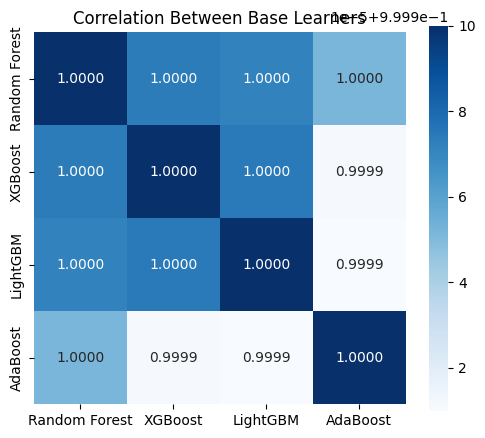

In [ ]:
# ============================================================
# TAMBAHAN 3: Korelasi Prediksi Antar Base Learner
# ============================================================

import pandas as pd

prediction_df = pd.DataFrame({
    "Random Forest": results_tuned["Random Forest"]["model"].predict(X_test),
    "XGBoost": results_tuned["XGBoost"]["model"].predict(X_test),
    "LightGBM": results_tuned["LightGBM"]["model"].predict(X_test),
    "AdaBoost": results_tuned["AdaBoost"]["model"].predict(X_test)
})

corr_matrix = prediction_df.corr()

print("="*60)
print("KORELASI PREDIKSI ANTAR BASE LEARNER")
print("="*60)
print(corr_matrix.round(6))

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6,5))
sns.heatmap(corr_matrix,
            annot=True,
            cmap="Blues",
            fmt=".4f",
            square=True)

plt.title("Correlation Between Base Learners")
plt.show()

### 4.5 Paired tests (Section 4.2 of the paper)

Wilcoxon signed-rank and paired t-test on absolute errors, mean difference with 95 % CI, Cohen’s d_z, rank-biserial r and a 1 W practical threshold.

In [ ]:
from scipy.stats import wilcoxon, ttest_rel, rankdata

THRESH_KW = 0.001   # ambang signifikansi praktis = 1 W (0.1% dari 1 kWp). Sesuaikan dan justifikasi di paper.

def stat_pair(name_a, pred_a, name_b, pred_b):
    e_a = np.abs(y_test.values - pred_a) * P_RANGE_KW     # kW
    e_b = np.abs(y_test.values - pred_b) * P_RANGE_KW
    d   = e_a - e_b                                        # >0 : model b lebih kecil error-nya
    n   = len(d)

    W, p_w = wilcoxon(d)
    t, p_t = ttest_rel(e_a, e_b)
    mean_d, sd_d = d.mean(), d.std(ddof=1)
    ci = (mean_d - 1.96 * sd_d / np.sqrt(n), mean_d + 1.96 * sd_d / np.sqrt(n))
    dz = mean_d / sd_d

    nz = d[d != 0]; rk = rankdata(np.abs(nz))
    rbc = (rk[nz > 0].sum() - rk[nz < 0].sum()) / rk.sum()

    print('=' * 62)
    print(f'{name_a} vs {name_b} (n = {n:,})')
    print('=' * 62)
    print(f'MAE {name_a:<16}: {e_a.mean():.6f} kW')
    print(f'MAE {name_b:<16}: {e_b.mean():.6f} kW')
    print(f'Selisih rata-rata  : {mean_d:.6f} kW  (95% CI {ci[0]:.6f} s/d {ci[1]:.6f})')
    print(f'                   = {mean_d / PEAK_KWP * 100:.4f}% dari kapasitas terpasang')
    p_w_str = f'{p_w:.3g}' if p_w >= 1e-300 else '< 0.001 (underflow numerik)'
    p_t_str = f'{p_t:.3g}' if p_t >= 1e-300 else '< 0.001 (underflow numerik)'
    print(f'Wilcoxon           : W={W:,.0f}, p={p_w_str}')
    print(f'Paired t-test      : t={t:.4f}, p={p_t_str}')
    print(f"Cohen's d (paired) : {dz:.4f}")
    print(f'Rank-biserial r    : {rbc:.4f}')
    print(f'Sampel dg |selisih| > {THRESH_KW} kW : {(np.abs(d) > THRESH_KW).mean() * 100:.2f}%')
    print('Signifikan praktis?:', 'YA' if abs(mean_d) >= THRESH_KW else f'TIDAK (|selisih| < {THRESH_KW} kW)')
    print()

pred_xgb   = results_tuned['XGBoost']['model'].predict(X_test)
pred_lgbm  = results_tuned['LightGBM']['model'].predict(X_test)
pred_stack = stacking.predict(X_test)

# Pasangan utama: dua model berperforma terbaik saat ini
stat_pair('XGBoost Tuned', pred_xgb, 'Stacking', pred_stack)

# Pasangan sekunder: Stacking vs LightGBM (model lebih sederhana & jauh lebih cepat) -> bahan R2-Diskusi 3
stat_pair('LightGBM Tuned', pred_lgbm, 'Stacking', pred_stack)

XGBoost Tuned vs Stacking (n = 23,028)
MAE XGBoost Tuned   : 0.000887 kW
MAE Stacking        : 0.000737 kW
Selisih rata-rata  : 0.000151 kW  (95% CI 0.000141 s/d 0.000160)
                   = 0.0151% dari kapasitas terpasang
Wilcoxon           : W=97,640,886, p=8.31e-263
Paired t-test      : t=32.0531, p=1.38e-220
Cohen's d (paired) : 0.2112
Rank-biserial r    : 0.2635
Sampel dg |selisih| > 0.001 kW : 13.94%
Signifikan praktis?: TIDAK (|selisih| < 0.001 kW)

LightGBM Tuned vs Stacking (n = 23,028)
MAE LightGBM Tuned  : 0.000984 kW
MAE Stacking        : 0.000737 kW
Selisih rata-rata  : 0.000247 kW  (95% CI 0.000238 s/d 0.000257)
                   = 0.0247% dari kapasitas terpasang
Wilcoxon           : W=82,846,729, p=< 0.001 (underflow numerik)
Paired t-test      : t=49.9904, p=< 0.001 (underflow numerik)
Cohen's d (paired) : 0.3294
Rank-biserial r    : 0.3751
Sampel dg |selisih| > 0.001 kW : 17.15%
Signifikan praktis?: TIDAK (|selisih| < 0.001 kW)



## 5. Five-seed evaluation (seeds 42–46)

Clipping and scaling are refitted on the training part of every partition. The tuned hyperparameters from Section 3.2 are reused for all seeds.

In [ ]:
import os, time, pickle, numpy as np, pandas as pd
import sklearn, lightgbm, xgboost
from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor, AdaBoostRegressor, StackingRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

SEEDS  = [42, 43, 44, 45, 46]
MS_DIR = f'{DATA_DIR}/multiseed'; os.makedirs(MS_DIR, exist_ok=True)
print(f'sklearn {sklearn.__version__} | xgboost {xgboost.__version__} | lightgbm {lightgbm.__version__}')

df_u = pd.read_csv(f'{DATA_DIR}/pvgis_prepared_unscaled.csv')
CLIP_COLS = ['irr_total','irr_beam','irr_diffuse','irr_reflect','temp_air','wind_speed','sun_height']
FEATS = [c for c in df_u.columns if c not in ['P_kW', 'year', 'day']]
assert FEATS == FEATURES, 'urutan fitur beda dengan pipeline utama'
_cc = [c for c in FEATS if c.startswith('city_')]
df_u['city'] = df_u[_cc].idxmax(axis=1).str.replace('city_', '', regex=False)

def prepare(tr_idx, te_idx):
    """Clip persentil 1-99 dan MinMax di-fit HANYA dari train; diterapkan ke test."""
    Xtr = df_u.loc[tr_idx, FEATS].copy(); Xte = df_u.loc[te_idx, FEATS].copy()
    ytr = df_u.loc[tr_idx, 'P_kW'].values.reshape(-1, 1); yte = df_u.loc[te_idx, 'P_kW'].values.reshape(-1, 1)
    for c in CLIP_COLS:
        lo, hi = Xtr[c].quantile(0.01), Xtr[c].quantile(0.99)
        Xtr[c] = Xtr[c].clip(lo, hi); Xte[c] = Xte[c].clip(lo, hi)
    sc = MinMaxScaler().fit(Xtr[CLIP_COLS])
    Xtr[CLIP_COLS] = sc.transform(Xtr[CLIP_COLS]); Xte[CLIP_COLS] = sc.transform(Xte[CLIP_COLS])
    ysc = MinMaxScaler().fit(ytr)
    return Xtr, ysc.transform(ytr).ravel(), Xte, ysc.transform(yte).ravel(), float(ysc.data_range_[0])

TUNED = {n: results_tuned[n]['model'] for n in ['Random Forest', 'XGBoost', 'LightGBM', 'AdaBoost']}

def make_models(seed):
    out = [
        ('Linear Regression', 'Conventional', LinearRegression()),
        ('Decision Tree',     'Conventional', DecisionTreeRegressor(random_state=seed)),
        ('Random Forest', 'Baseline', RandomForestRegressor(n_estimators=100, random_state=seed, n_jobs=-1)),
        ('XGBoost',       'Baseline', XGBRegressor(n_estimators=100, random_state=seed, tree_method='hist', device='cpu', verbosity=0)),
        ('LightGBM',      'Baseline', LGBMRegressor(n_estimators=100, random_state=seed, n_jobs=-1, verbose=-1)),
        ('AdaBoost',      'Baseline', AdaBoostRegressor(estimator=DecisionTreeRegressor(max_depth=4), n_estimators=100, random_state=seed)),
    ]
    for n, m in TUNED.items():
        out.append((n, 'Tuned', clone(m).set_params(random_state=seed)))
    out.append(('Stacking', 'Stacking', StackingRegressor(
        estimators=[('rf',   clone(TUNED['Random Forest']).set_params(random_state=seed)),
                    ('xgb',  clone(TUNED['XGBoost']).set_params(random_state=seed)),
                    ('lgbm', clone(TUNED['LightGBM']).set_params(random_state=seed)),
                    ('ada',  clone(TUNED['AdaBoost']).set_params(random_state=seed))],
        final_estimator=Ridge(alpha=1.0), cv=5, n_jobs=-1, passthrough=False)))
    return out

sklearn 1.6.1 | xgboost 3.4.1 | lightgbm 4.6.0


### 5.1 Random split → Tables 2 and 8

In [ ]:
def run_random(seed):
    idx = df_u.index.values
    tr, tmp = train_test_split(idx, test_size=0.30, random_state=seed)
    va, te  = train_test_split(tmp, test_size=0.50, random_state=seed)
    Xtr, ytr, Xte, yte, pr = prepare(tr, te)
    city_te = df_u.loc[te, 'city'].values
    rows = []
    for name, stage, mdl in make_models(seed):
        t0 = time.time(); mdl.fit(Xtr, ytr); yp = mdl.predict(Xte)
        rows.append({'Seed': seed, 'Model': name, 'Stage': stage, 'Scope': 'All', **metrics_full(yte, yp, pr)})
        if stage in ('Tuned', 'Stacking'):
            for c in sorted(set(city_te)):
                mk = city_te == c
                rows.append({'Seed': seed, 'Model': name, 'Stage': stage, 'Scope': c, **metrics_full(yte[mk], yp[mk], pr)})
        print(f'  seed {seed} | {name:<18} {stage:<12} MAE_kW={rows[-1 if stage not in ("Tuned","Stacking") else -8]["MAE_kW"]:.6f} ({time.time()-t0:.0f}s)')
    return rows

RS_PATH = f'{MS_DIR}/ms_random.pkl'
ms_random = pickle.load(open(RS_PATH, 'rb')) if os.path.exists(RS_PATH) else {}
for s in SEEDS:
    if s in ms_random:
        print(f'seed {s}: sudah ada, dilewati'); continue
    print(f'=== RANDOM SPLIT seed {s} ===')
    ms_random[s] = run_random(s)
    pickle.dump(ms_random, open(RS_PATH, 'wb'))

# sanity: seed 42 harus (hampir) sama dengan hasil lama
_c = pd.DataFrame(ms_random[42])
print('Cek seed 42 LightGBM Tuned MAE:',
      _c[(_c.Model=='LightGBM') & (_c.Stage=='Tuned') & (_c.Scope=='All')]['MAE'].iloc[0],
      '| hasil lama:', results_tuned['LightGBM']['test']['MAE'])

seed 42: sudah ada, dilewati
seed 43: sudah ada, dilewati
seed 44: sudah ada, dilewati
seed 45: sudah ada, dilewati
seed 46: sudah ada, dilewati
Cek seed 42 LightGBM Tuned MAE: 0.001254822130808885 | hasil lama: 0.001258077095536582


### 5.2 Time-based split (train 2019–2022, test 2023)

This cell evaluates Stacking and LightGBM Tuned. Table 7 takes Stacking from here and XGBoost Tuned from Section 5.5.

In [ ]:
def run_time(seed):
    tr = df_u.index[df_u['year'] <= 2022].values
    te = df_u.index[df_u['year'] == 2023].values
    Xtr, ytr, Xte, yte, pr = prepare(tr, te)
    rows = []
    for name, stage, mdl in make_models(seed):
        if (name, stage) not in [('LightGBM', 'Tuned'), ('Stacking', 'Stacking')]:
            continue
        t0 = time.time(); mdl.fit(Xtr, ytr)
        rows.append({'Seed': seed, 'Model': name, 'Stage': stage, **metrics_full(yte, mdl.predict(Xte), pr)})
        print(f'  seed {seed} | {name:<10} MAE_kW={rows[-1]["MAE_kW"]:.6f} ({time.time()-t0:.0f}s)')
    return rows

TS_PATH = f'{MS_DIR}/ms_time.pkl'
ms_time = pickle.load(open(TS_PATH, 'rb')) if os.path.exists(TS_PATH) else {}
for s in SEEDS:
    if s in ms_time:
        print(f'seed {s}: sudah ada, dilewati'); continue
    print(f'=== TIME-BASED (train 2019-2022, test 2023) seed {s} ===')
    ms_time[s] = run_time(s)
    pickle.dump(ms_time, open(TS_PATH, 'wb'))

seed 42: sudah ada, dilewati
seed 43: sudah ada, dilewati
seed 44: sudah ada, dilewati
seed 45: sudah ada, dilewati
seed 46: sudah ada, dilewati


### 5.3 Leave-one-city-out with LightGBM Tuned (supplementary)

Kept because the summary cell below reads its file. Table 6 of the paper uses XGBoost Tuned (Section 5.5).

In [ ]:
def run_loco(seed):
    rows = []
    for city in sorted(df_u['city'].unique()):
        tr = df_u.index[df_u['city'] != city].values
        te = df_u.index[df_u['city'] == city].values
        Xtr, ytr, Xte, yte, pr = prepare(tr, te)
        m = clone(TUNED['LightGBM']).set_params(random_state=seed).fit(Xtr, ytr)
        rows.append({'Seed': seed, 'Kota_Holdout': city, **metrics_full(yte, m.predict(Xte), pr)})
    return rows

LO_PATH = f'{MS_DIR}/ms_loco.pkl'
ms_loco = pickle.load(open(LO_PATH, 'rb')) if os.path.exists(LO_PATH) else {}
for s in SEEDS:
    if s in ms_loco:
        print(f'seed {s}: sudah ada, dilewati'); continue
    print(f'=== LOCO seed {s} ===')
    ms_loco[s] = run_loco(s)
    pickle.dump(ms_loco, open(LO_PATH, 'wb'))

=== LOCO seed 42 ===
=== LOCO seed 43 ===
=== LOCO seed 44 ===
=== LOCO seed 45 ===
=== LOCO seed 46 ===


### 5.4 Summary tables (mean ± SD over five seeds)

`t2` → Table 2 and `t8` → Table 8 (columns `MAE_kW`, `RMSE_kW` × 1000 = W). The `t6` and `t7` tables printed here use LightGBM Tuned and are supplementary.

In [ ]:
import os, pickle, pandas as pd

# DATA_DIR is set in the CONFIGURATION cell at the top
MS_DIR   = f'{DATA_DIR}/multiseed'
SEEDS    = [42, 43, 44, 45, 46]

def _load(fname):
    path = f'{MS_DIR}/{fname}'
    if not os.path.exists(path):
        print(f'!! {fname} TIDAK ADA di Drive -> jalankan cell yang membuatnya'); return {}
    d = pickle.load(open(path, 'rb'))
    print(f'{fname:<16}: seed tersedia = {sorted(d.keys())}')
    return d

ms_random = _load('ms_random.pkl')   # dari C1 (random split)
ms_time   = _load('ms_time.pkl')     # dari C2 (time-based)
ms_loco   = _load('ms_loco.pkl')     # dari C3 (LOCO)

missing = {n: [s for s in SEEDS if s not in d]
           for n, d in [('random', ms_random), ('time', ms_time), ('loco', ms_loco)]}
print('\nSeed yang belum ada:', missing)

ms_random.pkl   : seed tersedia = [42, 43, 44, 45, 46]
ms_time.pkl     : seed tersedia = [42, 43, 44, 45, 46]
ms_loco.pkl     : seed tersedia = [42, 43, 44, 45, 46]

Seed yang belum ada: {'random': [], 'time': [], 'loco': []}


In [ ]:
MET = ['MAE', 'RMSE', 'R2', 'MAE_kW', 'RMSE_kW', 'nMAE_%', 'nRMSE_%']
DEC = {'MAE': 6, 'RMSE': 6, 'R2': 6, 'MAE_kW': 6, 'RMSE_kW': 6, 'nMAE_%': 4, 'nRMSE_%': 4}

def mean_std_table(df, by):
    rows = []
    for key, g in df.groupby(by, sort=False):
        key = key if isinstance(key, tuple) else (key,)
        r = dict(zip(by, key)); r['n_seed'] = g['Seed'].nunique()
        for m in MET:
            r[m] = f"{g[m].mean():.{DEC[m]}f} ± {g[m].std(ddof=1):.{DEC[m]}f}"
        rows.append(r)
    return pd.DataFrame(rows)

rs = pd.DataFrame([r for s in ms_random.values() for r in s])
ts = pd.DataFrame([r for s in ms_time.values()   for r in s])
lo = pd.DataFrame([r for s in ms_loco.values()   for r in s])

t2 = mean_std_table(rs[rs.Scope == 'All'], ['Model', 'Stage'])
t8 = mean_std_table(rs[rs.Scope != 'All'].rename(columns={'Scope': 'Kota'}), ['Kota', 'Model', 'Stage'])

_avg = lo.groupby('Seed')[MET].mean().reset_index().assign(Kota_Holdout='Average')
t6 = mean_std_table(pd.concat([lo, _avg], ignore_index=True), ['Kota_Holdout'])

_sel = rs[(rs.Scope == 'All') & (((rs.Model == 'LightGBM') & (rs.Stage == 'Tuned')) | (rs.Stage == 'Stacking'))]
t7 = mean_std_table(pd.concat([_sel.assign(Scheme='Random split'), ts.assign(Scheme='Time-based split')], ignore_index=True),
                    ['Model', 'Scheme'])

for nm, t in [('Tabel 2 (random split, test)', t2), ('Tabel 6 (LOCO, LightGBM Tuned)', t6),
              ('Tabel 7 (random vs time-based)', t7), ('Tabel 8 (per kota, test)', t8)]:
    print('\n' + '=' * 80); print(nm, f'| mean ± std, {len(SEEDS)} seed'); print('=' * 80)
    display(t)

t2.to_csv(f'{MS_DIR}/table2.csv', index=False); t6.to_csv(f'{MS_DIR}/table6.csv', index=False)
t7.to_csv(f'{MS_DIR}/table7.csv', index=False); t8.to_csv(f'{MS_DIR}/table8.csv', index=False)


Tabel 2 (random split, test) | mean ± std, 5 seed


,Model,Stage,n_seed,MAE,RMSE,R2,MAE_kW,RMSE_kW,nMAE_%,nRMSE_%
0,Linear Regression,Conventional,5,0.007654 ± 0.000025,0.010013 ± 0.000042,0.998544 ± 0.000009,0.005987 ± 0.000020,0.007833 ± 0.000032,0.5987 ± 0.0020,0.7833 ± 0.0032
1,Decision Tree,Conventional,5,0.002161 ± 0.000020,0.003394 ± 0.000031,0.999833 ± 0.000003,0.001690 ± 0.000016,0.002655 ± 0.000024,0.1690 ± 0.0016,0.2655 ± 0.0024
2,Random Forest,Baseline,5,0.001235 ± 0.000014,0.002129 ± 0.000059,0.999934 ± 0.000003,0.000966 ± 0.000011,0.001665 ± 0.000046,0.0966 ± 0.0011,0.1665 ± 0.0046
3,XGBoost,Baseline,5,0.001416 ± 0.000008,0.002184 ± 0.000031,0.999931 ± 0.000002,0.001108 ± 0.000006,0.001708 ± 0.000024,0.1108 ± 0.0006,0.1708 ± 0.0024
4,LightGBM,Baseline,5,0.001368 ± 0.000008,0.002156 ± 0.000039,0.999933 ± 0.000002,0.001070 ± 0.000006,0.001686 ± 0.000030,0.1070 ± 0.0006,0.1686 ± 0.0030
5,AdaBoost,Baseline,5,0.008128 ± 0.000108,0.010212 ± 0.000130,0.998486 ± 0.000042,0.006358 ± 0.000085,0.007988 ± 0.000102,0.6358 ± 0.0085,0.7988 ± 0.0102
6,Random Forest,Tuned,5,0.001202 ± 0.000011,0.002088 ± 0.000057,0.999937 ± 0.000003,0.000940 ± 0.000009,0.001634 ± 0.000044,0.0940 ± 0.0009,0.1634 ± 0.0044
7,XGBoost,Tuned,5,0.001141 ± 0.000008,0.001883 ± 0.000020,0.999949 ± 0.000001,0.000892 ± 0.000006,0.001473 ± 0.000016,0.0892 ± 0.0006,0.1473 ± 0.0016
8,LightGBM,Tuned,5,0.001252 ± 0.000009,0.001997 ± 0.000029,0.999942 ± 0.000001,0.000979 ± 0.000007,0.001562 ± 0.000022,0.0979 ± 0.0007,0.1562 ± 0.0022
9,AdaBoost,Tuned,5,0.002765 ± 0.000026,0.003697 ± 0.000039,0.999802 ± 0.000004,0.002163 ± 0.000021,0.002891 ± 0.000031,0.2163 ± 0.0021,0.2891 ± 0.0031



Tabel 6 (LOCO, LightGBM Tuned) | mean ± std, 5 seed


,Kota_Holdout,n_seed,MAE,RMSE,R2,MAE_kW,RMSE_kW,nMAE_%,nRMSE_%
0,Jakarta,5,0.001290 ± 0.000000,0.001949 ± 0.000000,0.999947 ± 0.000000,0.001009 ± 0.000000,0.001525 ± 0.000000,0.1009 ± 0.0000,0.1525 ± 0.0000
1,Jayapura,5,0.001149 ± 0.000000,0.001594 ± 0.000000,0.999961 ± 0.000000,0.000899 ± 0.000000,0.001247 ± 0.000000,0.0899 ± 0.0000,0.1247 ± 0.0000
2,Kupang,5,0.002025 ± 0.000000,0.003865 ± 0.000000,0.999813 ± 0.000000,0.001575 ± 0.000000,0.003007 ± 0.000000,0.1575 ± 0.0000,0.3007 ± 0.0000
3,Makassar,5,0.001331 ± 0.000000,0.002109 ± 0.000000,0.999933 ± 0.000000,0.001042 ± 0.000000,0.001650 ± 0.000000,0.1042 ± 0.0000,0.1650 ± 0.0000
4,Medan,5,0.001202 ± 0.000000,0.001692 ± 0.000000,0.999957 ± 0.000000,0.000940 ± 0.000000,0.001323 ± 0.000000,0.0940 ± 0.0000,0.1323 ± 0.0000
5,Pontianak,5,0.001132 ± 0.000000,0.001613 ± 0.000000,0.999959 ± 0.000000,0.000885 ± 0.000000,0.001262 ± 0.000000,0.0885 ± 0.0000,0.1262 ± 0.0000
6,Surabaya,5,0.001534 ± 0.000000,0.002684 ± 0.000000,0.999896 ± 0.000000,0.001200 ± 0.000000,0.002100 ± 0.000000,0.1200 ± 0.0000,0.2100 ± 0.0000
7,Average,5,0.001380 ± 0.000000,0.002215 ± 0.000000,0.999924 ± 0.000000,0.001078 ± 0.000000,0.001730 ± 0.000000,0.1078 ± 0.0000,0.1730 ± 0.0000



Tabel 7 (random vs time-based) | mean ± std, 5 seed


,Model,Scheme,n_seed,MAE,RMSE,R2,MAE_kW,RMSE_kW,nMAE_%,nRMSE_%
0,LightGBM,Random split,5,0.001252 ± 0.000009,0.001997 ± 0.000029,0.999942 ± 0.000001,0.000979 ± 0.000007,0.001562 ± 0.000022,0.0979 ± 0.0007,0.1562 ± 0.0022
1,Stacking,Random split,5,0.000945 ± 0.000007,0.001730 ± 0.000038,0.999957 ± 0.000002,0.000739 ± 0.000005,0.001353 ± 0.000030,0.0739 ± 0.0005,0.1353 ± 0.0030
2,LightGBM,Time-based split,5,0.001331 ± 0.000000,0.002342 ± 0.000000,0.999922 ± 0.000000,0.001041 ± 0.000000,0.001831 ± 0.000000,0.1041 ± 0.0000,0.1831 ± 0.0000
3,Stacking,Time-based split,5,0.001007 ± 0.000002,0.002131 ± 0.000004,0.999936 ± 0.000000,0.000787 ± 0.000001,0.001667 ± 0.000003,0.0787 ± 0.0001,0.1667 ± 0.0003



Tabel 8 (per kota, test) | mean ± std, 5 seed


,Kota,Model,Stage,n_seed,MAE,RMSE,R2,MAE_kW,RMSE_kW,nMAE_%,nRMSE_%
0,Jakarta,Random Forest,Tuned,5,0.001091 ± 0.000029,0.001894 ± 0.000236,0.999949 ± 0.000014,0.000854 ± 0.000023,0.001481 ± 0.000184,0.0854 ± 0.0023,0.1481 ± 0.0184
1,Jayapura,Random Forest,Tuned,5,0.000974 ± 0.000020,0.001469 ± 0.000065,0.999967 ± 0.000003,0.000762 ± 0.000016,0.001149 ± 0.000051,0.0762 ± 0.0016,0.1149 ± 0.0051
2,Kupang,Random Forest,Tuned,5,0.001612 ± 0.000073,0.003018 ± 0.000277,0.999883 ± 0.000019,0.001261 ± 0.000057,0.002361 ± 0.000217,0.1261 ± 0.0057,0.2361 ± 0.0217
3,Makassar,Random Forest,Tuned,5,0.001238 ± 0.000024,0.001987 ± 0.000091,0.999940 ± 0.000005,0.000968 ± 0.000019,0.001554 ± 0.000071,0.0968 ± 0.0019,0.1554 ± 0.0071
4,Medan,Random Forest,Tuned,5,0.001069 ± 0.000012,0.001626 ± 0.000070,0.999960 ± 0.000004,0.000836 ± 0.000009,0.001272 ± 0.000054,0.0836 ± 0.0009,0.1272 ± 0.0054
5,Pontianak,Random Forest,Tuned,5,0.001109 ± 0.000018,0.001790 ± 0.000093,0.999949 ± 0.000006,0.000867 ± 0.000014,0.001400 ± 0.000073,0.0867 ± 0.0014,0.1400 ± 0.0073
6,Surabaya,Random Forest,Tuned,5,0.001315 ± 0.000031,0.002392 ± 0.000141,0.999916 ± 0.000010,0.001029 ± 0.000024,0.001871 ± 0.000110,0.1029 ± 0.0024,0.1871 ± 0.0110
7,Jakarta,XGBoost,Tuned,5,0.001140 ± 0.000030,0.001851 ± 0.000186,0.999951 ± 0.000011,0.000892 ± 0.000024,0.001448 ± 0.000146,0.0892 ± 0.0024,0.1448 ± 0.0146
8,Jayapura,XGBoost,Tuned,5,0.001014 ± 0.000013,0.001398 ± 0.000058,0.999970 ± 0.000003,0.000793 ± 0.000010,0.001094 ± 0.000045,0.0793 ± 0.0010,0.1094 ± 0.0045
9,Kupang,XGBoost,Tuned,5,0.001416 ± 0.000041,0.002653 ± 0.000132,0.999910 ± 0.000008,0.001108 ± 0.000032,0.002075 ± 0.000103,0.1108 ± 0.0032,0.2075 ± 0.0103


### 5.5 XGBoost Tuned: time-based split, leave-one-city-out and feature-group ablation → Tables 7, 6 and 3

In [ ]:
# ============================================================
# REVISI: ablation, LOCO, dan time-based memakai XGBoost Tuned
# (model tunggal terbaik). Hasil lama TIDAK ditimpa -> file baru *_xgb
# ============================================================
import os, time, pickle, numpy as np, pandas as pd
from sklearn.base import clone

XGB_T = TUNED['XGBoost']

# ---------- 1) Time-based split: XGBoost Tuned ----------
def run_time_xgb(seed):
    tr = df_u.index[df_u['year'] <= 2022].values
    te = df_u.index[df_u['year'] == 2023].values
    Xtr, ytr, Xte, yte, pr = prepare(tr, te)
    m = clone(XGB_T).set_params(random_state=seed).fit(Xtr, ytr)
    return [{'Seed': seed, 'Model': 'XGBoost', 'Stage': 'Tuned', **metrics_full(yte, m.predict(Xte), pr)}]

TSX_PATH = f'{MS_DIR}/ms_time_xgb.pkl'
ms_time_xgb = pickle.load(open(TSX_PATH, 'rb')) if os.path.exists(TSX_PATH) else {}
for s in SEEDS:
    if s in ms_time_xgb:
        print(f'time-based seed {s}: sudah ada, dilewati'); continue
    t0 = time.time(); ms_time_xgb[s] = run_time_xgb(s)
    pickle.dump(ms_time_xgb, open(TSX_PATH, 'wb'))
    print(f'time-based seed {s} selesai ({time.time()-t0:.0f}s) | MAE_kW={ms_time_xgb[s][0]["MAE_kW"]:.6f}')

# ---------- 2) LOCO: XGBoost Tuned ----------
def run_loco_xgb(seed):
    rows = []
    for city in sorted(df_u['city'].unique()):
        tr = df_u.index[df_u['city'] != city].values
        te = df_u.index[df_u['city'] == city].values
        Xtr, ytr, Xte, yte, pr = prepare(tr, te)
        m = clone(XGB_T).set_params(random_state=seed).fit(Xtr, ytr)
        rows.append({'Seed': seed, 'Kota_Holdout': city, **metrics_full(yte, m.predict(Xte), pr)})
    return rows

LOX_PATH = f'{MS_DIR}/ms_loco_xgb.pkl'
ms_loco_xgb = pickle.load(open(LOX_PATH, 'rb')) if os.path.exists(LOX_PATH) else {}
for s in SEEDS:
    if s in ms_loco_xgb:
        print(f'LOCO seed {s}: sudah ada, dilewati'); continue
    t0 = time.time(); ms_loco_xgb[s] = run_loco_xgb(s)
    pickle.dump(ms_loco_xgb, open(LOX_PATH, 'wb'))
    print(f'LOCO seed {s} selesai ({time.time()-t0:.0f}s)')

# ---------- 3) Ringkasan Tabel 6 dan Tabel 7 (mean ± SD, 5 seed) ----------
MET = ['MAE', 'RMSE', 'R2', 'MAE_kW', 'RMSE_kW', 'nMAE_%', 'nRMSE_%']
DEC = {'MAE': 6, 'RMSE': 6, 'R2': 6, 'MAE_kW': 6, 'RMSE_kW': 6, 'nMAE_%': 4, 'nRMSE_%': 4}
def mean_std_table(df, by):
    rows = []
    for key, g in df.groupby(by, sort=False):
        key = key if isinstance(key, tuple) else (key,)
        r = dict(zip(by, key)); r['n_seed'] = g['Seed'].nunique()
        for m in MET:
            r[m] = f"{g[m].mean():.{DEC[m]}f} ± {g[m].std(ddof=1):.{DEC[m]}f}"
        rows.append(r)
    return pd.DataFrame(rows)

ms_random = pickle.load(open(f'{MS_DIR}/ms_random.pkl', 'rb'))
ms_time   = pickle.load(open(f'{MS_DIR}/ms_time.pkl', 'rb'))      # Stacking time-based (sudah ada)
rs  = pd.DataFrame([r for s in ms_random.values()   for r in s])
tsS = pd.DataFrame([r for s in ms_time.values()     for r in s]); tsS = tsS[tsS.Model == 'Stacking']
tsX = pd.DataFrame([r for s in ms_time_xgb.values() for r in s])
loX = pd.DataFrame([r for s in ms_loco_xgb.values() for r in s])

_avg = loX.groupby('Seed')[MET].mean().reset_index().assign(Kota_Holdout='Average')
t6x = mean_std_table(pd.concat([loX, _avg], ignore_index=True), ['Kota_Holdout'])

_sel = rs[(rs.Scope == 'All') & (((rs.Model == 'XGBoost') & (rs.Stage == 'Tuned')) | (rs.Stage == 'Stacking'))]
t7x = mean_std_table(pd.concat([_sel.assign(Scheme='Random split'),
                                tsX.assign(Scheme='Time-based split'),
                                tsS.assign(Scheme='Time-based split')], ignore_index=True),
                     ['Model', 'Scheme'])

print('\n' + '=' * 80); print('Tabel 6 BARU (LOCO, XGBoost Tuned) | mean ± std, 5 seed'); print('=' * 80); display(t6x)
print('\n' + '=' * 80); print('Tabel 7 BARU (XGBoost Tuned & Stacking: random vs time-based)'); print('=' * 80); display(t7x)
print('\nSD MAE antar seed, LOCO per kota:'); print(loX.groupby('Kota_Holdout')['MAE'].std().map('{:.2e}'.format).to_string())
print('\nSD MAE antar seed, time-based XGBoost:', f"{tsX['MAE'].std():.2e}")
t6x.to_csv(f'{MS_DIR}/table6_xgb.csv', index=False); t7x.to_csv(f'{MS_DIR}/table7_xgb.csv', index=False)

# ---------- 4) Ablation (Tabel 3): XGBoost Tuned, split seed 42 ----------
irr_cols      = ['irr_total', 'irr_beam', 'irr_diffuse', 'irr_reflect']
met_cols      = irr_cols + ['temp_air', 'wind_speed', 'sun_height']
temporal_cols = ['hour', 'month', 'hour_sin', 'hour_cos', 'month_sin', 'month_cos']
season_cols   = ['season']
city_f_cols   = [c for c in FEATURES if c.startswith('city_')]
assert set(met_cols + temporal_cols + season_cols + city_f_cols) == set(FEATURES)

drop = lambda g: [c for c in FEATURES if c not in g]
schemes = {
    f'Irradiance only ({len(irr_cols)})'             : irr_cols,
    f'Full feature set ({len(FEATURES)})'            : FEATURES,
    f'Full - temporal ({len(drop(temporal_cols))})'  : drop(temporal_cols),
    f'Full - season ({len(drop(season_cols))})'      : drop(season_cols),
    f'Full - city one-hot ({len(drop(city_f_cols))})': drop(city_f_cols),
}
rows = []
for name, cols in schemes.items():
    m = clone(results_tuned['XGBoost']['model'])
    m.fit(X_train[cols], y_train)
    rows.append({'Skema': name, **metrics_full(y_test.values, m.predict(X_test[cols]))})
abl_x = pd.DataFrame(rows)
base = abl_x.loc[abl_x['Skema'].str.startswith('Full feature'), 'MAE'].iloc[0]
abl_x['MAE vs Full (%)'] = (abl_x['MAE'] / base - 1) * 100
print('\n' + '=' * 80); print('Tabel 3 BARU (ablation, XGBoost Tuned, seed 42)'); print('=' * 80)
display(abl_x.round(6))
abl_x.to_csv(f'{DATA_DIR}/table3_xgb.csv', index=False)

time-based seed 42 selesai (12s) | MAE_kW=0.000948
time-based seed 43 selesai (12s) | MAE_kW=0.000948
time-based seed 44 selesai (4s) | MAE_kW=0.000948
time-based seed 45 selesai (6s) | MAE_kW=0.000948
time-based seed 46 selesai (4s) | MAE_kW=0.000948
LOCO seed 42 selesai (49s)
LOCO seed 43 selesai (34s)
LOCO seed 44 selesai (32s)
LOCO seed 45 selesai (33s)
LOCO seed 46 selesai (35s)

Tabel 6 BARU (LOCO, XGBoost Tuned) | mean ± std, 5 seed


,Kota_Holdout,n_seed,MAE,RMSE,R2,MAE_kW,RMSE_kW,nMAE_%,nRMSE_%
0,Jakarta,5,0.001165 ± 0.000000,0.001815 ± 0.000000,0.999954 ± 0.000000,0.000912 ± 0.000000,0.001420 ± 0.000000,0.0912 ± 0.0000,0.1420 ± 0.0000
1,Jayapura,5,0.001038 ± 0.000000,0.001461 ± 0.000000,0.999968 ± 0.000000,0.000812 ± 0.000000,0.001143 ± 0.000000,0.0812 ± 0.0000,0.1143 ± 0.0000
2,Kupang,5,0.001937 ± 0.000000,0.003944 ± 0.000000,0.999805 ± 0.000000,0.001507 ± 0.000000,0.003068 ± 0.000000,0.1507 ± 0.0000,0.3068 ± 0.0000
3,Makassar,5,0.001220 ± 0.000000,0.001982 ± 0.000000,0.999941 ± 0.000000,0.000954 ± 0.000000,0.001551 ± 0.000000,0.0954 ± 0.0000,0.1551 ± 0.0000
4,Medan,5,0.001079 ± 0.000000,0.001523 ± 0.000000,0.999965 ± 0.000000,0.000844 ± 0.000000,0.001192 ± 0.000000,0.0844 ± 0.0000,0.1192 ± 0.0000
5,Pontianak,5,0.001033 ± 0.000000,0.001489 ± 0.000000,0.999965 ± 0.000000,0.000808 ± 0.000000,0.001165 ± 0.000000,0.0808 ± 0.0000,0.1165 ± 0.0000
6,Surabaya,5,0.001453 ± 0.000000,0.002630 ± 0.000000,0.999900 ± 0.000000,0.001137 ± 0.000000,0.002057 ± 0.000000,0.1137 ± 0.0000,0.2057 ± 0.0000
7,Average,5,0.001275 ± 0.000000,0.002121 ± 0.000000,0.999928 ± 0.000000,0.000996 ± 0.000000,0.001656 ± 0.000000,0.0996 ± 0.0000,0.1656 ± 0.0000



Tabel 7 BARU (XGBoost Tuned & Stacking: random vs time-based)


,Model,Scheme,n_seed,MAE,RMSE,R2,MAE_kW,RMSE_kW,nMAE_%,nRMSE_%
0,XGBoost,Random split,5,0.001141 ± 0.000008,0.001883 ± 0.000020,0.999949 ± 0.000001,0.000892 ± 0.000006,0.001473 ± 0.000016,0.0892 ± 0.0006,0.1473 ± 0.0016
1,Stacking,Random split,5,0.000945 ± 0.000007,0.001730 ± 0.000038,0.999957 ± 0.000002,0.000739 ± 0.000005,0.001353 ± 0.000030,0.0739 ± 0.0005,0.1353 ± 0.0030
2,XGBoost,Time-based split,5,0.001211 ± 0.000000,0.002262 ± 0.000000,0.999927 ± 0.000000,0.000948 ± 0.000000,0.001769 ± 0.000000,0.0948 ± 0.0000,0.1769 ± 0.0000
3,Stacking,Time-based split,5,0.001007 ± 0.000002,0.002131 ± 0.000004,0.999936 ± 0.000000,0.000787 ± 0.000001,0.001667 ± 0.000003,0.0787 ± 0.0001,0.1667 ± 0.0003



SD MAE antar seed, LOCO per kota:
Kota_Holdout
Jakarta      0.00e+00
Jayapura     0.00e+00
Kupang       0.00e+00
Makassar     0.00e+00
Medan        0.00e+00
Pontianak    0.00e+00
Surabaya     0.00e+00

SD MAE antar seed, time-based XGBoost: 0.00e+00

Tabel 3 BARU (ablation, XGBoost Tuned, seed 42)


,Skema,MAE,RMSE,R2,MAE_kW,RMSE_kW,nMAE_%,nRMSE_%,MAE vs Full (%)
0,Irradiance only (4),0.004592,0.007318,0.999226,0.003592,0.005724,0.359170,0.572406,304.757169
1,Full feature set (21),0.001134,0.001896,0.999948,0.000887,0.001483,0.088737,0.148310,0.000000
2,Full - temporal (15),0.001188,0.002042,0.999940,0.000930,0.001598,0.092964,0.159762,4.763339
3,Full - season (20),0.001136,0.001891,0.999948,0.000889,0.001479,0.088850,0.147939,0.127287
4,Full - city one-hot (14),0.001144,0.001920,0.999947,0.000895,0.001502,0.089474,0.150210,0.830209


## 6. Results and error analysis

### 6.1 Residuals versus predicted power (Fig. 3)

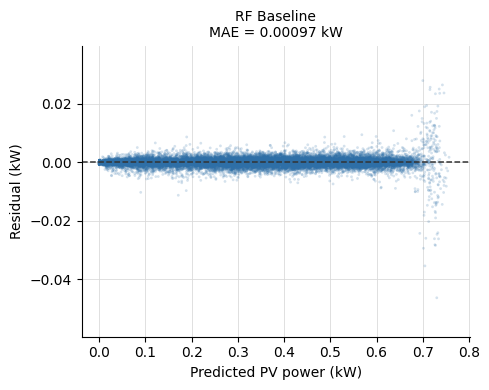

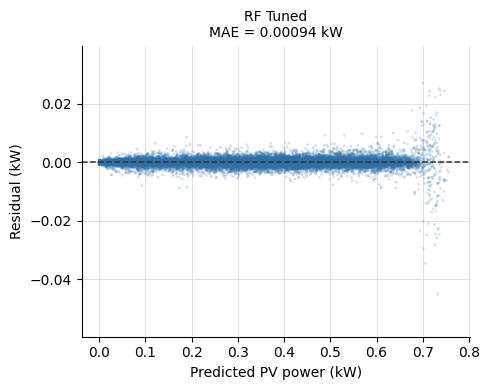

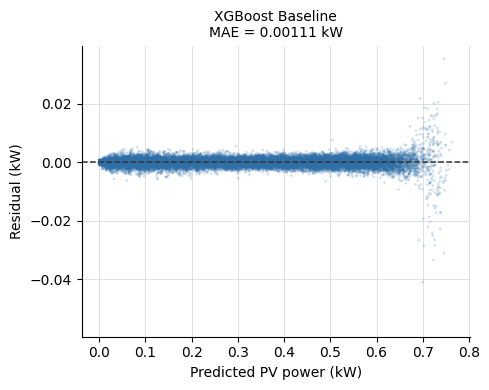

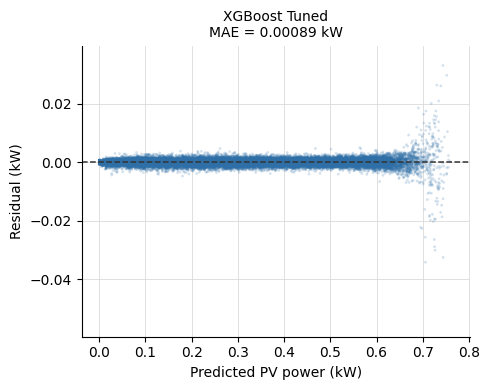

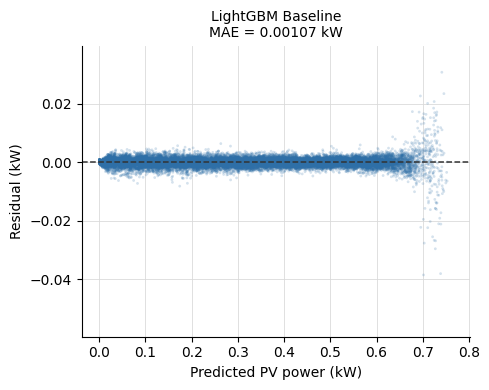

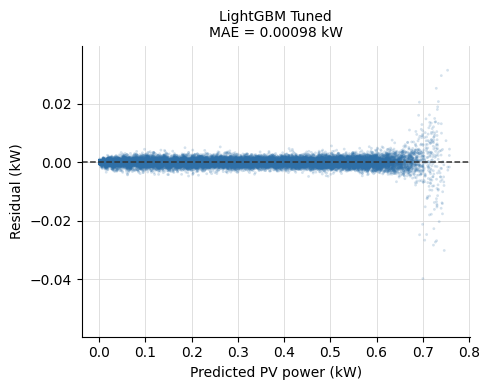

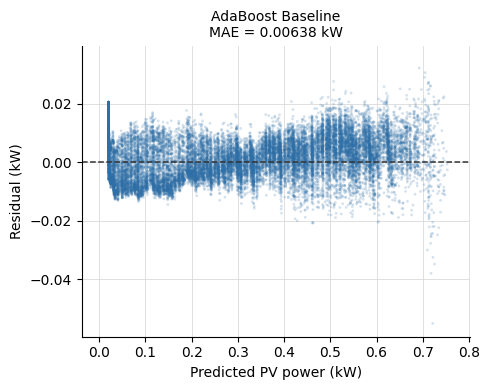

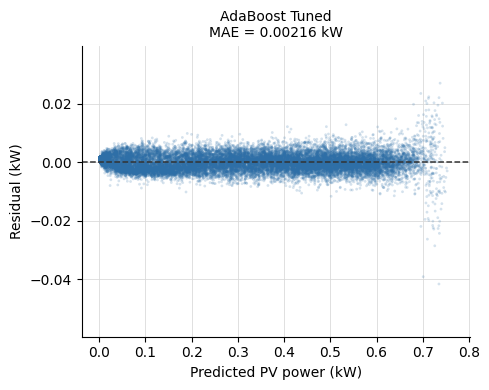

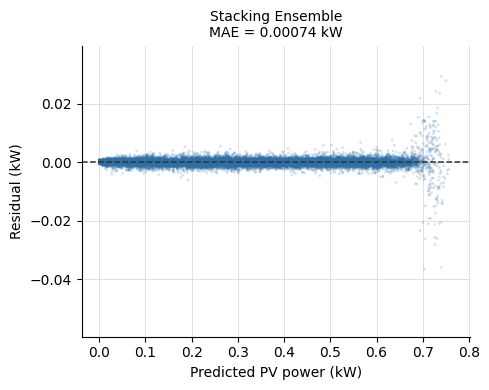

Tersimpan di Drive: /content/drive/MyDrive/TUGAS_AKHIR/Dataset/fig3_residual


In [ ]:
import numpy as np, matplotlib.pyplot as plt
import os, shutil
try:
    from google.colab import files      # download helper, only available on Colab
except ImportError:
    files = None
plt.rcParams['font.family'] = 'sans-serif'

all_models = {
    'RF Baseline': results_baseline['Random Forest'],  'RF Tuned': results_tuned['Random Forest'],
    'XGBoost Baseline': results_baseline['XGBoost'],   'XGBoost Tuned': results_tuned['XGBoost'],
    'LightGBM Baseline': results_baseline['LightGBM'], 'LightGBM Tuned': results_tuned['LightGBM'],
    'AdaBoost Baseline': results_baseline['AdaBoost'], 'AdaBoost Tuned': results_tuned['AdaBoost'],
    'Stacking Ensemble': results_tuned['Stacking'],
}
letters = 'abcdefghi'

OUT_DIR = 'fig3_residual'                     # folder sementara di Colab
os.makedirs(OUT_DIR, exist_ok=True)

# skala sumbu disamakan untuk semua panel, seperti gambar asli (sharex/sharey)
data = {}
for name, res in all_models.items():
    yp = res['test']['y_pred']
    data[name] = (yp * P_RANGE_KW + P_MIN_KW, (yp - y_test.values) * P_RANGE_KW)
xmin = min(p.min() for p, r in data.values()); xmax = max(p.max() for p, r in data.values())
ymin = min(r.min() for p, r in data.values()); ymax = max(r.max() for p, r in data.values())
padx = 0.05 * (xmax - xmin); pady = 0.05 * (ymax - ymin)

saved = []
for k, (name, (pred, resid)) in enumerate(data.items()):
    fig, ax = plt.subplots(figsize=(5, 4))
    ax.scatter(pred, resid, s=4, alpha=0.2, color='#2E6FA7', edgecolors='none', rasterized=True)
    ax.axhline(0, color='#333333', linestyle='--', linewidth=1.1)
    ax.set_title(f'{name}\nMAE = {np.abs(resid).mean():.5f} kW', fontsize=10)
    ax.set_xlim(xmin - padx, xmax + padx); ax.set_ylim(ymin - pady, ymax + pady)
    ax.set_xlabel('Predicted PV power (kW)'); ax.set_ylabel('Residual (kW)')
    ax.grid(True, color='#DADADA', linewidth=0.6); ax.set_axisbelow(True)
    for sp in ['top', 'right']: ax.spines[sp].set_visible(False)
    plt.tight_layout()
    fn = os.path.join(OUT_DIR, f'Fig3{letters[k]}_{name.replace(" ", "_")}.png')
    plt.savefig(fn, dpi=600, bbox_inches='tight', facecolor='white')
    saved.append(fn)
    plt.show()
    plt.close(fig)

# ── Download ───────────────────────────────────────────────
# Opsi A: satu file ZIP berisi 9 gambar (paling praktis, 1x klik)
shutil.make_archive('Fig3_residual_9_panels', 'zip', OUT_DIR)
if files: files.download('Fig3_residual_9_panels.zip')

# Opsi B: download satu per satu (hapus tanda # di dua baris bawah kalau mau ini)
# for fn in saved:
#     files.download(fn)

# Cadangan: salin juga ke Google Drive
DRIVE_DIR = f'{DATA_DIR}/fig3_residual'
os.makedirs(DRIVE_DIR, exist_ok=True)
for fn in saved:
    shutil.copy(fn, DRIVE_DIR)
print('Tersimpan di Drive:', DRIVE_DIR)

### 6.2 Best model per city and irradiance variability (Stacking, seed 42)

=== Model Terbaik per Kota ===
Kota           Model                   MAE       RMSE         R2
--------------------------------------------------------------
Jayapura       Stacking           0.000775   0.001114   0.999981
Medan          Stacking           0.000799   0.001203   0.999978
Pontianak      Stacking           0.000861   0.001552   0.999961
Jakarta        Stacking           0.000867   0.001535   0.999967
Makassar       Stacking           0.000984   0.001708   0.999956
Surabaya       Stacking           0.001031   0.002034   0.999940
Kupang         Stacking           0.001274   0.002651   0.999911

Frekuensi model terbaik:
  Stacking        : 7x → ['Jayapura', 'Medan', 'Pontianak', 'Jakarta', 'Makassar', 'Surabaya', 'Kupang']

=== Variabilitas Iklim (data mentah) vs MAE Stacking per Kota ===
Kota             CV irr_total   CV irr_diffuse          MAE
----------------------------------------------------------
Kupang                 0.6366           0.6551     0.001274
Surabaya 

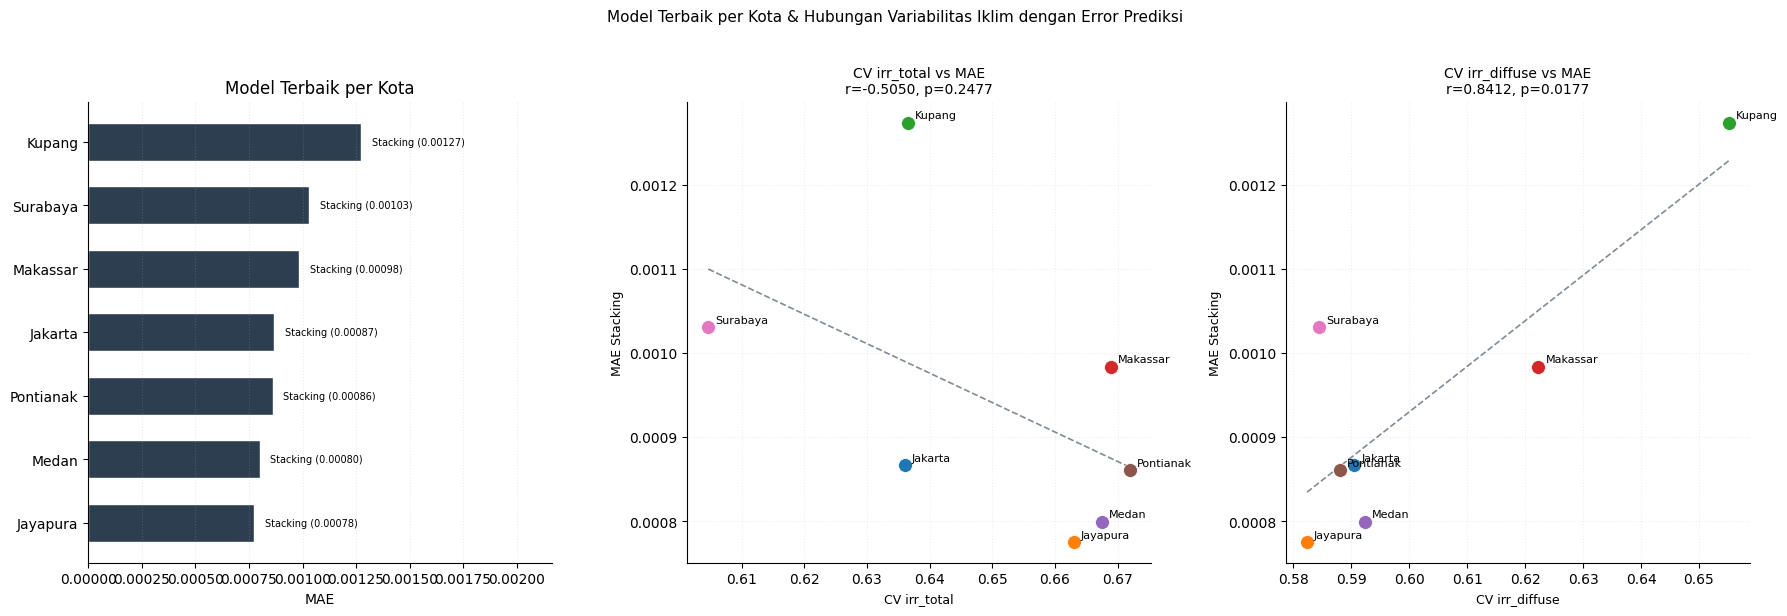


=== Ringkasan ===
  Jayapura       → Stacking
  Medan          → Stacking
  Pontianak      → Stacking
  Jakarta        → Stacking
  Makassar       → Stacking
  Surabaya       → Stacking
  Kupang         → Stacking

CV irr_total   vs MAE : r=-0.5050 (p=0.2477)
CV irr_diffuse vs MAE : r=0.8412 (p=0.0177)


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from scipy import stats

# ── Setup data test + label kota ──────────────────────────────
df_test = X_test.copy()
df_test['P_kW_actual'] = y_test.values
city_cols = [c for c in X_test.columns if c.startswith('city_')]
df_test['kota'] = df_test[city_cols].idxmax(axis=1).str.replace('city_', '', regex=False)
kota_list = sorted(df_test['kota'].unique())

models_all = {
    'RF Baseline'  : results_baseline['Random Forest']['model'],
    'RF Tuned'     : results_tuned['Random Forest']['model'],
    'XGB Baseline' : results_baseline['XGBoost']['model'],
    'XGB Tuned'    : results_tuned['XGBoost']['model'],
    'LGBM Baseline': results_baseline['LightGBM']['model'],
    'LGBM Tuned'   : results_tuned['LightGBM']['model'],
    'Ada Baseline' : results_baseline['AdaBoost']['model'],
    'Ada Tuned'    : results_tuned['AdaBoost']['model'],
    'Stacking'     : stacking,
}

# ── Hitung MAE per model per kota ─────────────────────────────
rows = []
for model_name, model in models_all.items():
    df_temp = df_test.copy()
    df_temp['y_pred'] = model.predict(X_test)
    for kota in kota_list:
        mask = df_temp['kota'] == kota
        rows.append({
            'Model': model_name, 'Kota': kota,
            'MAE' : mean_absolute_error(df_temp.loc[mask, 'P_kW_actual'], df_temp.loc[mask, 'y_pred']),
            'RMSE': np.sqrt(mean_squared_error(df_temp.loc[mask, 'P_kW_actual'], df_temp.loc[mask, 'y_pred'])),
            'R2'  : r2_score(df_temp.loc[mask, 'P_kW_actual'], df_temp.loc[mask, 'y_pred']),
        })

df_performa = pd.DataFrame(rows)

# ── Model terbaik per kota ────────────────────────────────────
best_per_kota = (
    df_performa.loc[df_performa.groupby('Kota')['MAE'].idxmin()]
    [['Kota','Model','MAE','RMSE','R2']]
    .sort_values('MAE').reset_index(drop=True)
)

print('=== Model Terbaik per Kota ===')
print(f'{"Kota":<14} {"Model":<16} {"MAE":>10} {"RMSE":>10} {"R2":>10}')
print('-' * 62)
for _, r in best_per_kota.iterrows():
    print(f'{r.Kota:<14} {r.Model:<16} {r.MAE:>10.6f} {r.RMSE:>10.6f} {r.R2:>10.6f}')

counts = best_per_kota['Model'].value_counts()
print(f'\nFrekuensi model terbaik:')
for m, c in counts.items():
    kota_nya = best_per_kota[best_per_kota['Model']==m]['Kota'].tolist()
    print(f'  {m:<16}: {c}x → {kota_nya}')

# ── CV irradiance per kota (dari data MENTAH, bukan hasil normalisasi) ──
iklim = df_u.groupby('city').agg(
    irr_total_mean  =('irr_total',   'mean'), irr_total_std  =('irr_total',   'std'),
    irr_diffuse_mean=('irr_diffuse', 'mean'), irr_diffuse_std=('irr_diffuse', 'std'),
).reset_index().rename(columns={'city':'Kota'})

iklim['cv_irr_total']   = iklim['irr_total_std']   / iklim['irr_total_mean']
iklim['cv_irr_diffuse'] = iklim['irr_diffuse_std']  / iklim['irr_diffuse_mean']

# MAE Stacking per kota (model akhir terbaik, konsisten dengan estimasi produksi tahunan)
mae_rows = []
for kota in kota_list:
    mask = df_test['kota'] == kota
    mae_rows.append({
        'Kota': kota,
        'MAE_Stacking': mean_absolute_error(df_test.loc[mask,'P_kW_actual'],
                                             stacking.predict(X_test[mask]))
    })

df_kor = iklim.merge(pd.DataFrame(mae_rows), on='Kota')

print('\n=== Variabilitas Iklim (data mentah) vs MAE Stacking per Kota ===')
print(f'{"Kota":<14} {"CV irr_total":>14} {"CV irr_diffuse":>16} {"MAE":>12}')
print('-' * 58)
for _, r in df_kor.sort_values('MAE_Stacking', ascending=False).iterrows():
    print(f'{r.Kota:<14} {r.cv_irr_total:>14.4f} {r.cv_irr_diffuse:>16.4f} {r.MAE_Stacking:>12.6f}')

r1, p1 = stats.pearsonr(df_kor['cv_irr_total'],   df_kor['MAE_Stacking'])
r2, p2 = stats.pearsonr(df_kor['cv_irr_diffuse'],  df_kor['MAE_Stacking'])
print(f'\nKorelasi CV irr_total   vs MAE : r={r1:.4f}, p={p1:.4f} {"(signifikan)" if p1<0.05 else "(tidak signifikan)"}')
print(f'Korelasi CV irr_diffuse vs MAE : r={r2:.4f}, p={p2:.4f} {"(signifikan)" if p2<0.05 else "(tidak signifikan)"}')

# ── Visualisasi ───────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Plot 1 — Bar chart model terbaik per kota
cmap = {
    'LGBM Tuned':'#E07B20','LGBM Baseline':'#F5C07A',
    'RF Tuned':'#185FA5','RF Baseline':'#7BAED4',
    'XGB Tuned':'#1D9E75','XGB Baseline':'#7DD4B8',
    'Ada Tuned':'#9B59B6','Ada Baseline':'#C39BD3',
    'Stacking':'#2C3E50',
}
bars = axes[0].barh(best_per_kota['Kota'],
                    best_per_kota['MAE'],
                    color=[cmap.get(m,'#888') for m in best_per_kota['Model']],
                    edgecolor='white', height=0.6)
for bar, (_, r) in zip(bars, best_per_kota.iterrows()):
    axes[0].text(bar.get_width()+0.00005, bar.get_y()+bar.get_height()/2,
                 f'{r.Model} ({r.MAE:.5f})', va='center', fontsize=7)
axes[0].set_xlabel('MAE'); axes[0].set_title('Model Terbaik per Kota')
axes[0].set_xlim(0, best_per_kota['MAE'].max()*1.7)
axes[0].grid(axis='x', alpha=0.25, linestyle=':')
axes[0].spines[['top','right']].set_visible(False)

# Plot 2 & 3 — Scatter CV vs MAE
sc_colors = plt.cm.tab10.colors
for ax, cv_col, xlabel, r_val, p_val in [
    (axes[1], 'cv_irr_total',   'CV irr_total',   r1, p1),
    (axes[2], 'cv_irr_diffuse', 'CV irr_diffuse',  r2, p2),
]:
    for i, (_, row) in enumerate(df_kor.iterrows()):
        ax.scatter(row[cv_col], row['MAE_Stacking'], color=sc_colors[i],
                   s=100, zorder=3, edgecolors='white', linewidths=0.5)
        ax.annotate(row['Kota'], (row[cv_col], row['MAE_Stacking']),
                    xytext=(5,3), textcoords='offset points', fontsize=8)
    z = np.polyfit(df_kor[cv_col], df_kor['MAE_Stacking'], 1)
    x_line = np.linspace(df_kor[cv_col].min(), df_kor[cv_col].max(), 100)
    ax.plot(x_line, np.poly1d(z)(x_line), '--', color='#2C3E50', alpha=0.6, lw=1.2)
    ax.set_xlabel(xlabel, fontsize=9)
    ax.set_ylabel('MAE Stacking', fontsize=9)
    ax.set_title(f'{xlabel} vs MAE\nr={r_val:.4f}, p={p_val:.4f}', fontsize=10)
    ax.grid(alpha=0.2, linestyle=':')
    ax.spines[['top','right']].set_visible(False)

plt.suptitle('Model Terbaik per Kota & Hubungan Variabilitas Iklim dengan Error Prediksi',
             fontsize=11, y=1.02)
plt.tight_layout()
plt.savefig('analisis_tambahan_kota_iklim.png', dpi=150, bbox_inches='tight')
plt.show()

# ── Ringkasan ─────────────────────────────────────────────────
print('\n=== Ringkasan ===')
for _, r in best_per_kota.iterrows():
    print(f'  {r.Kota:<14} → {r.Model}')
print(f'\nCV irr_total   vs MAE : r={r1:.4f} (p={p1:.4f})')
print(f'CV irr_diffuse vs MAE : r={r2:.4f} (p={p2:.4f})')

### 6.3 Output statistics and annual production per city (Table 9)

ESTIMASI PRODUKSI PLTS PER KOTA (sistem 1 kWp, Stacking) - dalam kW / kWh


,city,produksi_rata2_kW,produksi_std_kW,cv_produksi,produksi_max_kW,produksi_tahunan_kWh,tahunan_PVGIS_kWh
2,Kupang,0.3347,0.2197,0.6564,0.7760,1479.0734,1479.3091
6,Surabaya,0.3296,0.2057,0.6239,0.7504,1410.4823,1409.9508
0,Jakarta,0.3187,0.2086,0.6545,0.7546,1403.9201,1403.5820
1,Jayapura,0.2952,0.2006,0.6797,0.7495,1296.6520,1296.8483
4,Medan,0.2947,0.2011,0.6826,0.7343,1309.3005,1309.4721
3,Makassar,0.2915,0.2021,0.6933,0.7700,1277.2116,1277.4776
5,Pontianak,0.2876,0.1981,0.6886,0.7303,1260.5374,1260.3971


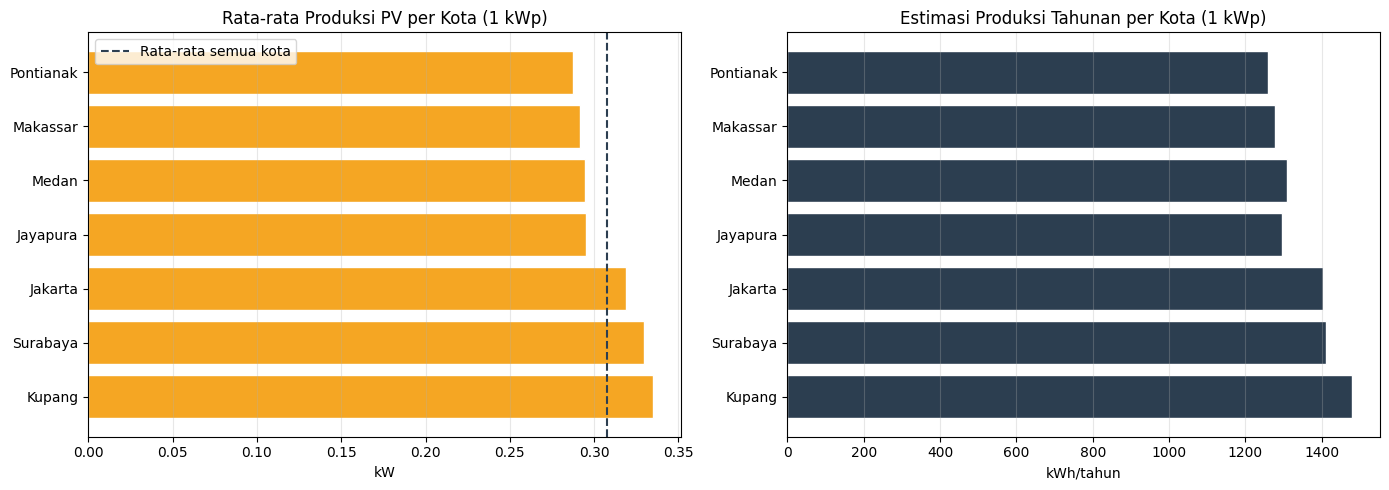

In [ ]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt

df_clean = pd.read_csv(f'{DATA_DIR}/pvgis_clean.csv')
_cc = [c for c in df_clean.columns if c.startswith('city_')]
df_clean['city'] = df_clean[_cc].idxmax(axis=1).str.replace('city_', '', regex=False)

# model dilatih pada P_kW ter-normalisasi -> kembalikan ke kW
df_clean['P_kW_pred'] = stacking.predict(df_clean[FEATURES]) * P_RANGE_KW + P_MIN_KW
df_clean['P_kW_true'] = df_clean['P_kW'] * P_RANGE_KW + P_MIN_KW

N_YEARS = 5
city_stats = df_clean.groupby('city').agg(
    produksi_rata2_kW  = ('P_kW_pred', 'mean'),
    produksi_std_kW    = ('P_kW_pred', 'std'),
    produksi_max_kW    = ('P_kW_pred', 'max'),
    total_pred_kWh     = ('P_kW_pred', 'sum'),
    total_PVGIS_kWh    = ('P_kW_true', 'sum'),
).reset_index()
city_stats['cv_produksi']         = city_stats['produksi_std_kW'] / city_stats['produksi_rata2_kW']
city_stats['produksi_tahunan_kWh'] = city_stats['total_pred_kWh'] / N_YEARS
city_stats['tahunan_PVGIS_kWh']    = city_stats['total_PVGIS_kWh'] / N_YEARS   # pembanding (cek unit)
city_stats = city_stats.sort_values('produksi_rata2_kW', ascending=False)

print('=' * 90)
print('ESTIMASI PRODUKSI PLTS PER KOTA (sistem 1 kWp, Stacking) - dalam kW / kWh')
print('=' * 90)
display(city_stats[['city', 'produksi_rata2_kW', 'produksi_std_kW', 'cv_produksi',
                    'produksi_max_kW', 'produksi_tahunan_kWh', 'tahunan_PVGIS_kWh']].round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].barh(city_stats['city'], city_stats['produksi_rata2_kW'], color='#F5A623', edgecolor='white')
axes[0].axvline(city_stats['produksi_rata2_kW'].mean(), color='#2C3E50', linestyle='--', label='Rata-rata semua kota')
axes[0].set_title('Rata-rata Produksi PV per Kota (1 kWp)'); axes[0].set_xlabel('kW'); axes[0].legend()
axes[1].barh(city_stats['city'], city_stats['produksi_tahunan_kWh'], color='#2C3E50', edgecolor='white')
axes[1].set_title('Estimasi Produksi Tahunan per Kota (1 kWp)'); axes[1].set_xlabel('kWh/tahun')
for a in axes: a.grid(axis='x', alpha=0.3)
plt.tight_layout(); plt.show()

### 6.4 Gain-based feature importance of XGBoost Tuned (Fig. 4)

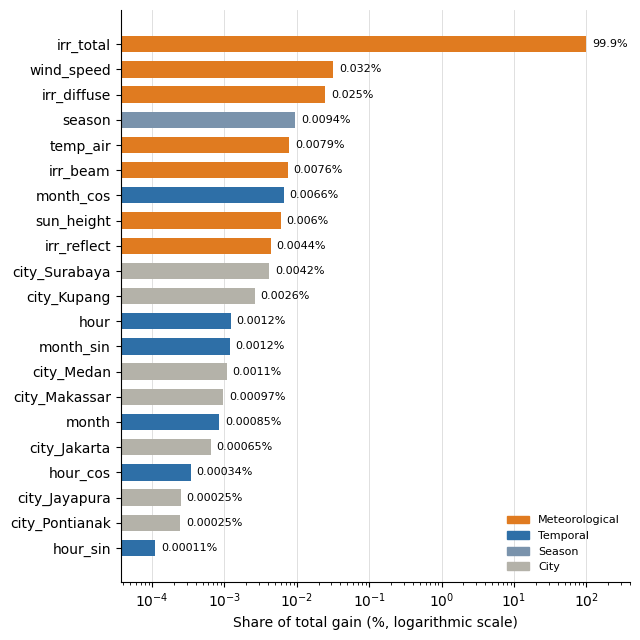

group
City               0.01
Meteorological    99.97
Season             0.01
Temporal           0.01
Name: pct, dtype: float64


In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.patches import Patch
try:
    from google.colab import files      # download helper, only available on Colab
except ImportError:
    files = None
plt.rcParams['font.family'] = 'sans-serif'

xgb_model = results_tuned['XGBoost']['model']
score = xgb_model.get_booster().get_score(importance_type='gain')
feat  = list(X_train.columns)
imp   = np.array([score.get(f, 0.0) for f in feat])
fi = pd.DataFrame({'feature': feat, 'pct': imp / imp.sum() * 100})

groups = {'Meteorological': ['irr_total', 'irr_beam', 'irr_diffuse', 'irr_reflect',
                             'temp_air', 'wind_speed', 'sun_height'],
          'Temporal': ['hour', 'month', 'hour_sin', 'hour_cos', 'month_sin', 'month_cos'],
          'Season':   ['season'],
          'City':     [f for f in feat if f.startswith('city_')]}
gcol = {'Meteorological': '#E07B20', 'Temporal': '#2E6FA7', 'Season': '#7A93AC', 'City': '#B4B2A9'}
f2g = {f: g for g, fs in groups.items() for f in fs}
fi['group'] = fi['feature'].map(f2g)

unused = fi.loc[fi['pct'] == 0, 'feature'].tolist()
if unused:
    print('Fitur tidak pernah dipakai untuk split (gain = 0), tidak ditampilkan:', unused)
fp = fi[fi['pct'] > 0].sort_values('pct').reset_index(drop=True)

fig, ax = plt.subplots(figsize=(6.5, 6.5))
ax.barh(fp['feature'], fp['pct'], color=fp['group'].map(gcol), height=0.65)
ax.set_xscale('log')
for y, v in enumerate(fp['pct']):
    ax.text(v * 1.2, y, f'{v:.1f}%' if v >= 1 else f'{v:.2g}%', va='center', fontsize=8)
ax.set_xlim(fp['pct'].min() / 3, 400)
ax.set_xticks([1e-4, 1e-3, 1e-2, 1e-1, 1, 10, 100])
ax.set_xlabel('Share of total gain (%, logarithmic scale)')
ax.grid(axis='x', color='#DADADA', linewidth=0.6); ax.set_axisbelow(True)
for sp in ['top', 'right']: ax.spines[sp].set_visible(False)
ax.legend(handles=[Patch(color=c, label=g) for g, c in gcol.items()],
          loc='lower right', frameon=False, fontsize=8)
plt.tight_layout()
plt.savefig('feature_importance.png', dpi=600, bbox_inches='tight', facecolor='white')
plt.show()

print(fi.groupby('group')['pct'].sum().round(2))   # cek: harus sama dengan angka di P12
if files: files.download('feature_importance.png')

Gain and split-count ranking (text output used in the paper; the bar chart of this cell is not used).


  Perbandingan: irr_total — gain=99.9% vs split-count=2.6%
  FEATURE IMPORTANCE — XGB Tuned (gain)
  (Kontribusi variabel terhadap prediksi daya keluaran)
  Rank  Fitur                Importance   Persen
  ------------------------------------------------
  1     irr_total                  10.0   99.89%  █████████████████████████████████████████████████ ◄ TOP
  2     wind_speed                  0.0    0.03%   ◄ TOP
  3     irr_diffuse                 0.0    0.02%   ◄ TOP
  4     season                      0.0    0.01%  
  5     temp_air                    0.0    0.01%  
  6     irr_beam                    0.0    0.01%  
  7     month_cos                   0.0    0.01%  
  8     sun_height                  0.0    0.01%  
  9     irr_reflect                 0.0    0.00%  
  10    city_Surabaya               0.0    0.00%  
  11    city_Kupang                 0.0    0.00%  
  12    hour                        0.0    0.00%  
  13    month_sin                   0.0    0.00%  
  14    city_M

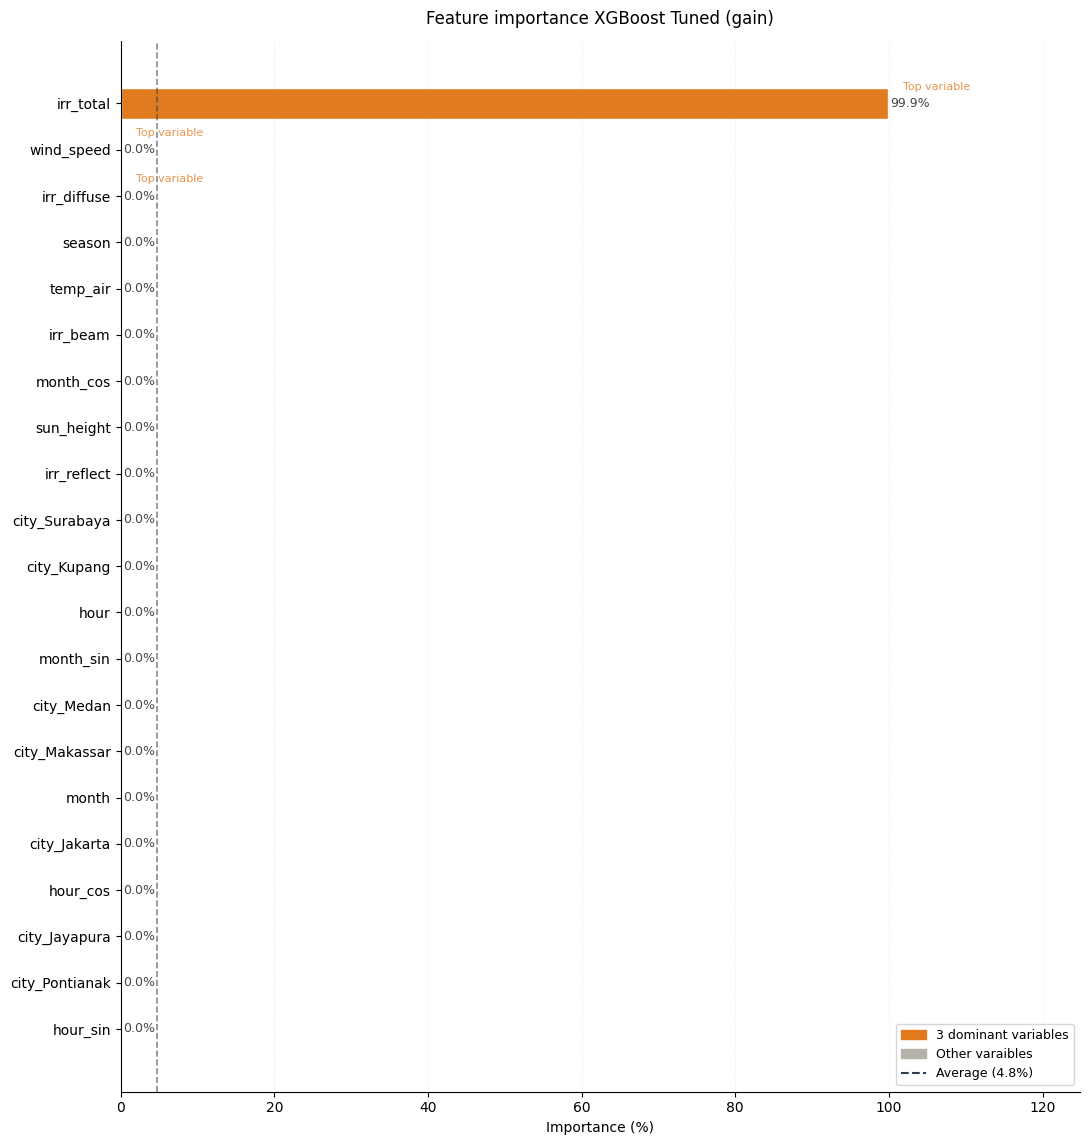

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
import pandas as pd

# ── 1. Ambil feature importance dari XGB Tuned ─────────
xgb_model = results_tuned['XGBoost']['model']
importances = xgb_model.get_booster().get_score(importance_type='gain')
importances = np.array([importances.get(f, 0.0) for f in X_train.columns])
feature_names = X_train.columns.tolist()

fi_df = pd.DataFrame({
    'fitur': feature_names,
    'importance': importances
}).sort_values('importance', ascending=False).reset_index(drop=True)

fi_df['importance_pct'] = fi_df['importance'] / fi_df['importance'].sum() * 100
top3 = fi_df.head(3)['fitur'].tolist()
avg_imp = fi_df['importance_pct'].mean()
top3_pct = fi_df.head(3)['importance_pct'].sum()

weight_imp = xgb_model.get_booster().get_score(importance_type='weight')
weight_arr = np.array([weight_imp.get(f, 0.0) for f in X_train.columns])
fi_df['weight_pct'] = weight_arr / weight_arr.sum() * 100
print(f"\n  Perbandingan: irr_total — gain={fi_df.loc[fi_df['fitur']=='irr_total','importance_pct'].values[0]:.1f}% "
      f"vs split-count={fi_df.loc[fi_df['fitur']=='irr_total','weight_pct'].values[0]:.1f}%")

# ── 2. Print tabel ───────────────────────────────────────────
print('=' * 58)
print('  FEATURE IMPORTANCE — XGB Tuned (gain)')
print('  (Kontribusi variabel terhadap prediksi daya keluaran)')
print('=' * 58)
print(f'  {"Rank":<5} {"Fitur":<20} {"Importance":>10} {"Persen":>8}')
print('  ' + '-' * 48)
for i, row in fi_df.iterrows():
    rank = i + 1
    bar = '█' * int(row['importance_pct'] / 2)
    flag = ' ◄ TOP' if rank <= 3 else ''
    print(f'  {rank:<5} {row["fitur"]:<20} {row["importance"]:>10.1f}'
          f' {row["importance_pct"]:>7.2f}%  {bar}{flag}')

print(f'\n  Rata-rata importance : {avg_imp:.2f}%')
print(f'  Top-3 gabungan       : {top3_pct:.2f}%')

# ── 3. Visualisasi ───────────────────────────────────────────
fig, ax = plt.subplots(figsize=(11, max(6, len(fi_df) * 0.55)))

colors = ['#E07B20' if i < 3 else '#B4B2A9' for i in range(len(fi_df))]
bars = ax.barh(
    fi_df['fitur'][::-1],
    fi_df['importance_pct'][::-1],
    color=colors[::-1],
    edgecolor='white',
    height=0.65
)

for bar, pct in zip(bars, fi_df['importance_pct'][::-1]):
    ax.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height()/2,
            f'{pct:.1f}%', va='center', fontsize=9, color='#444441')

ax.axvline(avg_imp, color='#2C3E50', linestyle='--',
           alpha=0.6, linewidth=1.2, label=f'Rata-rata ({avg_imp:.1f}%)')

for i, row in fi_df.head(3).iterrows():
    ax.annotate('Top variable',
                xy=(row['importance_pct'], len(fi_df) - i - 1),
                xytext=(row['importance_pct'] + 2, len(fi_df) - i - 1 + 0.3),
                fontsize=8, color='#E07B20', alpha=0.8)

patch_top   = mpatches.Patch(color='#E07B20', label='3 dominant variables')
patch_other = mpatches.Patch(color='#B4B2A9', label='Other varaibles')
ax.legend(handles=[patch_top, patch_other,
                   plt.Line2D([0],[0], color='#2C3E50', linestyle='--',
                               label=f'Average ({avg_imp:.1f}%)')],
          fontsize=9, loc='lower right')

ax.set_title(
    'Feature importance XGBoost Tuned (gain)',
    fontsize=12, pad=12
)
ax.set_xlabel('Importance (%)', fontsize=10)
ax.set_xlim(0, fi_df['importance_pct'].max() * 1.25)
ax.grid(axis='x', alpha=0.25, linestyle=':')
ax.spines[['top','right']].set_visible(False)
plt.tight_layout()
plt.savefig('feature_importance_overview.png', dpi=300, bbox_inches='tight')
plt.show()

### 6.5 SHAP summary of XGBoost Tuned (Fig. 5) and group shares

Computing SHAP values for 2000 randomly sampled test instances...
SHAP values computed. Shape: (2000, 21)

  SHAP GLOBAL FEATURE IMPORTANCE — XGBoost Tuned
  Rank  Feature                Mean|SHAP|    Share
  --------------------------------------------------
  1     irr_total                 0.22637   94.64%
  2     wind_speed                0.00367    1.53%
  3     temp_air                  0.00249    1.04%
  4     irr_diffuse               0.00200    0.83%
  5     sun_height                0.00185    0.77%
  6     irr_beam                  0.00133    0.56%
  7     month_cos                 0.00069    0.29%
  8     irr_reflect               0.00037    0.15%
  9     season                    0.00017    0.07%
  10    month                     0.00005    0.02%
  11    hour                      0.00005    0.02%
  12    city_Medan                0.00005    0.02%
  13    city_Kupang               0.00003    0.01%
  14    city_Surabaya             0.00002    0.01%
  15    month_sin         

/tmp/ipykernel_998/1042783842.py:45: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values, X_sample, show=False, plot_size=None)


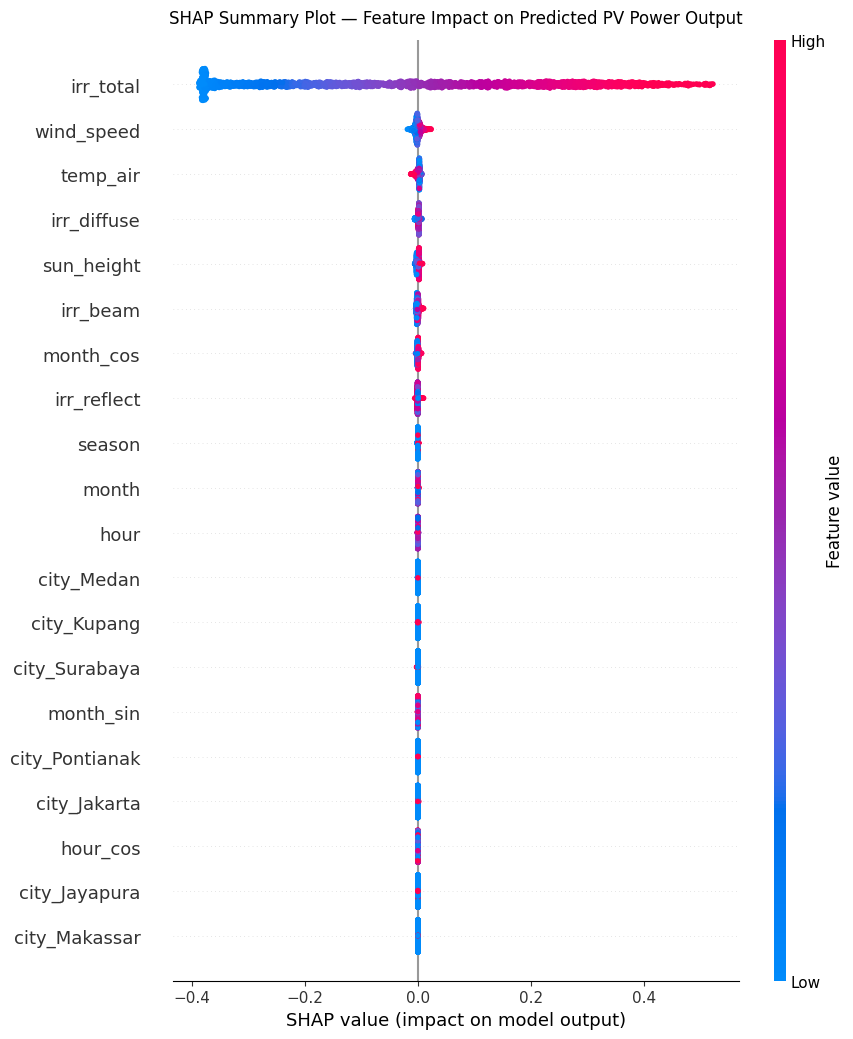


  RANK AGREEMENT: SHAP vs XGB BUILT-IN IMPORTANCE
       feature  shap_rank  gain_rank
     irr_total          1          1
    wind_speed          2          2
      temp_air          3          5
   irr_diffuse          4          3
    sun_height          5          8
      irr_beam          6          6
     month_cos          7          7
   irr_reflect          8          9
        season          9          4
         month         10         16
          hour         11         12
    city_Medan         12         14
   city_Kupang         13         11
 city_Surabaya         14         10
     month_sin         15         13
city_Pontianak         16         20
  city_Jakarta         17         17
      hour_cos         18         18
 city_Jayapura         19         19
 city_Makassar         20         15
      hour_sin         21         21

Spearman rank correlation : rho = 0.9052, p = 0.000000


In [ ]:
!pip install shap -q

import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from scipy.stats import spearmanr

mpl.rcParams['font.family'] = 'sans-serif'
mpl.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Helvetica']
mpl.rcParams['font.size'] = 10

# ── 1. Setup: XGBoost Tuned (hasil BO terbaru) ───────────────
xgb_model = results_tuned['XGBoost']['model']

np.random.seed(42)
sample_idx = np.random.choice(X_test.index, size=2000, replace=False)
X_sample = X_test.loc[sample_idx].reset_index(drop=True)

print(f'Computing SHAP values for {len(X_sample)} randomly sampled test instances...')
explainer   = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_sample)
if isinstance(shap_values, list):
    shap_values = shap_values[0]
print(f'SHAP values computed. Shape: {shap_values.shape}')

# ── 2. Ranking global (mean |SHAP|) — hanya tabel teks, untuk dikutip di naskah ──
shap_df = pd.DataFrame({
    'feature': X_sample.columns,
    'mean_abs_shap': np.abs(shap_values).mean(axis=0)
}).sort_values('mean_abs_shap', ascending=False).reset_index(drop=True)
shap_df['pct'] = shap_df['mean_abs_shap'] / shap_df['mean_abs_shap'].sum() * 100

print('\n' + '=' * 58)
print('  SHAP GLOBAL FEATURE IMPORTANCE — XGBoost Tuned')
print('=' * 58)
print(f'  {"Rank":<5} {"Feature":<20} {"Mean|SHAP|":>12} {"Share":>8}')
print('  ' + '-' * 50)
for i, row in shap_df.iterrows():
    print(f'  {i+1:<5} {row["feature"]:<20} {row["mean_abs_shap"]:>12.5f} {row["pct"]:>7.2f}%')

# ── 3. Fig. 5 — SHAP summary (beeswarm), satu-satunya gambar ──
plt.figure(figsize=(9, max(6, len(shap_df) * 0.5)))
shap.summary_plot(shap_values, X_sample, show=False, plot_size=None)
plt.title('SHAP Summary Plot — Feature Impact on Predicted PV Power Output',
          fontsize=12, pad=12)
plt.tight_layout()
plt.savefig('shap_summary_beeswarm.png', dpi=300, bbox_inches='tight')
plt.show()

# ── 4. Cross-check SHAP vs XGBoost built-in importance (teks saja) ──
gain_ranking = pd.DataFrame({
    'feature': X_train.columns,
    'gain_importance': [xgb_model.get_booster().get_score(importance_type='gain').get(f, 0.0) for f in X_train.columns]
}).sort_values('gain_importance', ascending=False).reset_index(drop=True)
gain_ranking['gain_rank'] = gain_ranking.index + 1

shap_ranking = shap_df[['feature']].copy()
shap_ranking['shap_rank'] = shap_ranking.index + 1
rank_compare = shap_ranking.merge(gain_ranking[['feature', 'gain_rank']], on='feature')

rho, p_val = spearmanr(rank_compare['shap_rank'], rank_compare['gain_rank'])
print('\n' + '=' * 58)
print('  RANK AGREEMENT: SHAP vs XGB BUILT-IN IMPORTANCE')
print('=' * 58)
print(rank_compare.to_string(index=False))
print(f'\nSpearman rank correlation : rho = {rho:.4f}, p = {p_val:.6f}')

In [ ]:
# Persentase kontribusi per KELOMPOK fitur (untuk klaim meteorologis vs identitas kota)
import pandas as pd

groups = {
    'Meteorological': ['irr_total', 'irr_beam', 'irr_diffuse', 'irr_reflect', 'temp_air', 'wind_speed', 'sun_height'],
    'Temporal'      : ['hour', 'month', 'hour_sin', 'hour_cos', 'month_sin', 'month_cos'],
    'Season'        : ['season'],
    'City'          : [c for c in X_train.columns if c.startswith('city_')],
}
assert sorted(sum(groups.values(), [])) == sorted(X_train.columns), 'ada fitur yang belum masuk kelompok'

g_shap = {g: shap_df.loc[shap_df['feature'].isin(cols), 'pct'].sum() for g, cols in groups.items()}
g_gain = {g: fi_df.loc[fi_df['fitur'].isin(cols), 'importance_pct'].sum() for g, cols in groups.items()}
print(pd.DataFrame({'SHAP (%)': g_shap, 'Gain (%)': g_gain}).round(2))

                 SHAP (%)  Gain (%)
Meteorological  99.529999     99.97
Temporal         0.350000      0.01
Season           0.070000      0.01
City             0.060000      0.01


### 6.6 Error by hour of day (Stacking, test set)

  HOURLY PATTERN — Error Prediksi per Jam
  Jam           MAE   Daya Aktual     Status
  ---------------------------------------------
  5         0.00025       0.00885
  6         0.00050       0.04664
  7         0.00074       0.17443
  8         0.00067       0.32028
  9         0.00067       0.43533
  10        0.00088       0.50237 ◄ KRITIS
  11        0.00119       0.52205 ◄ KRITIS
  12        0.00100       0.50714 ◄ KRITIS
  13        0.00074       0.45147
  14        0.00071       0.35803
  15        0.00073       0.23702
  16        0.00072       0.10972
  17        0.00032       0.01829
  18        0.00018       0.00148

  Rata-rata MAE per jam : 0.00066
  Jam paling kritis     : [11, 12, 10]


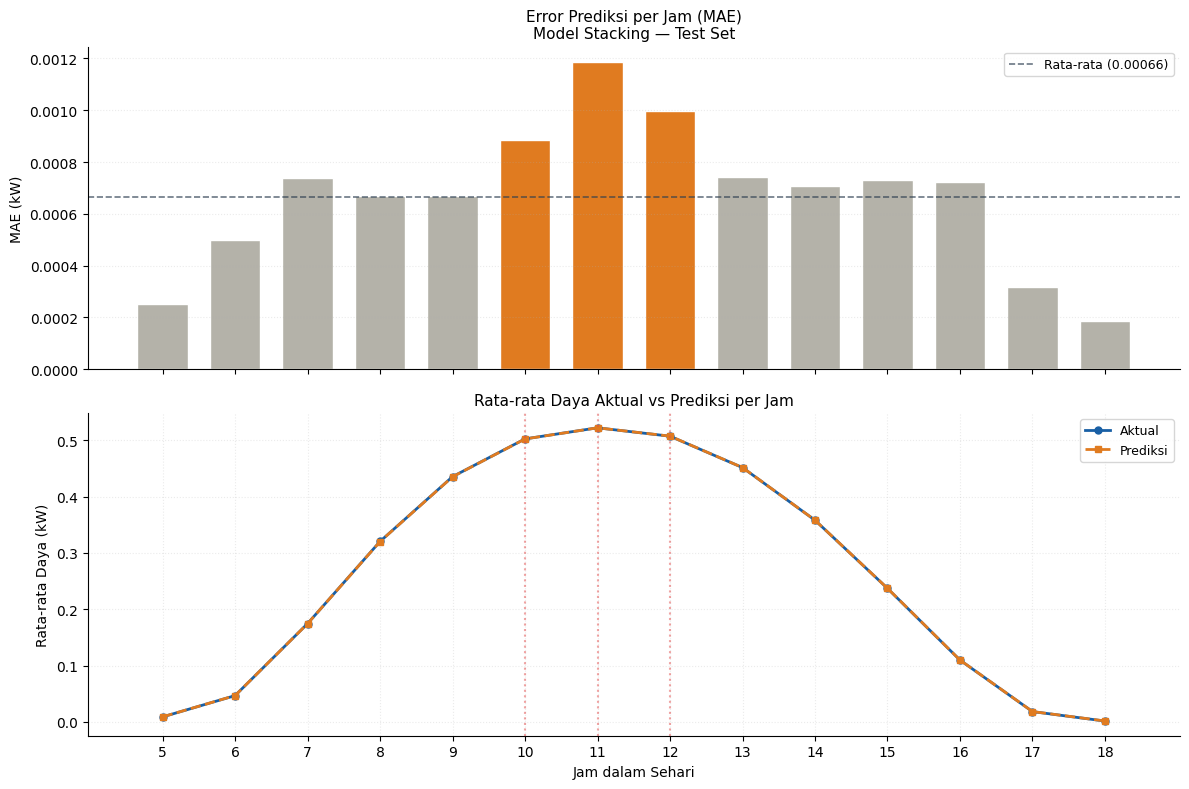

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Gabungkan data test dengan prediksi
df_test = X_test.copy()
df_test['P_kW_actual'] = y_test.values * P_RANGE_KW + P_MIN_KW                  # kW
df_test['P_kW_pred']   = stacking.predict(X_test) * P_RANGE_KW + P_MIN_KW       # kW
df_test['error']       = (df_test['P_kW_pred'] - df_test['P_kW_actual']).abs()  # kW

# Agregasi per jam
hourly = df_test.groupby('hour').agg(
    mae_per_jam  = ('error', 'mean'),
    daya_aktual  = ('P_kW_actual', 'mean'),
    daya_pred    = ('P_kW_pred', 'mean'),
    n            = ('error', 'count')
).reset_index()

avg_error = hourly['mae_per_jam'].mean()
jam_kritis = hourly.nlargest(3, 'mae_per_jam')['hour'].tolist()

# Print tabel
print('=' * 55)
print('  HOURLY PATTERN — Error Prediksi per Jam')
print('=' * 55)
print(f'  {"Jam":<6} {"MAE":>10} {"Daya Aktual":>13} {"Status":>10}')
print('  ' + '-' * 45)
for _, row in hourly.iterrows():
    status = ' ◄ KRITIS' if row['hour'] in jam_kritis else ''
    print(f'  {int(row["hour"]):<6} {row["mae_per_jam"]:>10.5f}'
          f' {row["daya_aktual"]:>13.5f}{status}')

print(f'\n  Rata-rata MAE per jam : {avg_error:.5f}')
print(f'  Jam paling kritis     : {jam_kritis}')

# Visualisasi
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

# Plot 1 — MAE per jam
bar_colors = ['#E07B20' if h in jam_kritis else '#B4B2A9'
              for h in hourly['hour']]
ax1.bar(hourly['hour'], hourly['mae_per_jam'],
        color=bar_colors, edgecolor='white', width=0.7)
ax1.axhline(avg_error, color='#2C3E50', linestyle='--',
            linewidth=1.2, alpha=0.7, label=f'Rata-rata ({avg_error:.5f})')
ax1.set_ylabel('MAE (kW)', fontsize=10)
ax1.set_title('Error Prediksi per Jam (MAE)\nModel Stacking — Test Set',
              fontsize=11)
ax1.legend(fontsize=9)
ax1.grid(axis='y', alpha=0.25, linestyle=':')
ax1.spines[['top','right']].set_visible(False)

# Plot 2 — Daya aktual vs prediksi per jam
ax2.plot(hourly['hour'], hourly['daya_aktual'],
         color='#185FA5', linewidth=2, marker='o',
         markersize=5, label='Aktual')
ax2.plot(hourly['hour'], hourly['daya_pred'],
         color='#E07B20', linewidth=2, linestyle='--',
         marker='s', markersize=4, label='Prediksi')
for h in jam_kritis:
    ax2.axvline(h, color='#E24B4A', linestyle=':', alpha=0.5)
ax2.set_ylabel('Rata-rata Daya (kW)', fontsize=10)
ax2.set_xlabel('Jam dalam Sehari', fontsize=10)
ax2.set_title('Rata-rata Daya Aktual vs Prediksi per Jam', fontsize=11)
ax2.legend(fontsize=9)
ax2.grid(alpha=0.25, linestyle=':')
ax2.spines[['top','right']].set_visible(False)
ax2.set_xticks(hourly['hour'])

plt.tight_layout()
plt.savefig('hourly_pattern.png', dpi=300, bbox_inches='tight')
plt.show()

### 6.7 Peak-hour errors and percentile clipping

In [ ]:
IRR = ['irr_total', 'irr_beam', 'irr_diffuse', 'irr_reflect']

_idx = df_u.index.values
_tr, _tmp = train_test_split(_idx, test_size=0.30, random_state=42)
_va, _te  = train_test_split(_tmp, test_size=0.50, random_state=42)
raw_te = df_u.loc[_te].reset_index(drop=True)
assert (raw_te['hour'].values == X_test['hour'].values).all() and \
       (raw_te['month'].values == X_test['month'].values).all(), 'urutan baris test tidak cocok'

flag = pd.DataFrame({c: (raw_te[c] > clip_bounds[c][1]) | (raw_te[c] < clip_bounds[c][0]) for c in CLIP_COLS})
raw_te['clip_irr'] = flag[IRR].any(axis=1)
pred = stacking.predict(X_test)
raw_te['err_kW']  = np.abs(pred - y_test.values) * P_RANGE_KW
raw_te['bias_kW'] = (pred - y_test.values) * P_RANGE_KW
raw_te['jam_puncak'] = raw_te['hour'].between(10, 12)

print('Persentase baris test yang ter-clip per fitur (%):')
print((flag.mean() * 100).round(2).to_string())

print('\nPersentase baris dengan irradiance ter-clip, per jam (%):')
print((raw_te.groupby('hour')['clip_irr'].mean() * 100).round(2).to_string())

res = raw_te.groupby(['jam_puncak', 'clip_irr']).agg(
    n=('err_kW', 'size'), MAE_kW=('err_kW', 'mean'), bias_kW=('bias_kW', 'mean')).reset_index()
print('\nError Stacking: jam puncak (10-12) vs lainnya, ter-clip vs tidak:')
display(res.round(6))

Persentase baris test yang ter-clip per fitur (%):
irr_total      2.08
irr_beam       1.02
irr_diffuse    2.14
irr_reflect    0.90
temp_air       2.09
wind_speed     1.58
sun_height     1.89

Persentase baris dengan irradiance ter-clip, per jam (%):
hour
5     11.07
6      2.45
7      0.00
8      0.00
9      0.37
10     5.56
11    12.05
12     8.31
13     1.72
14     0.00
15     0.00
16     0.00
17     8.07
18    36.09

Error Stacking: jam puncak (10-12) vs lainnya, ter-clip vs tidak:


,jam_puncak,clip_irr,n,MAE_kW,bias_kW
0,False,False,16950,0.000643,-0.000004
1,False,True,293,0.000521,0.000380
2,True,False,5284,0.000728,-0.000048
3,True,True,501,0.004127,0.000528


### 6.8 Error by month

  SEASONAL ANALYSIS — Error Prediksi per Bulan
  Bulan           MAE   Daya Aktual     Status
  ---------------------------------------------
  Jan         0.00070       0.30117
  Feb         0.00071       0.30711
  Mar         0.00070       0.30942
  Apr         0.00066       0.30208
  Mei         0.00064       0.28654 ◄ STABIL
  Jun         0.00061       0.26083 ◄ STABIL
  Jul         0.00064       0.27752 ◄ STABIL
  Agt         0.00069       0.32126
  Sep         0.00081       0.35023 ◄ TINGGI
  Okt         0.00106       0.34311 ◄ TINGGI
  Nov         0.00087       0.32680 ◄ TINGGI
  Des         0.00075       0.29676

  Rata-rata MAE bulanan : 0.00074
  Bulan error tertinggi : ['Okt', 'Nov', 'Sep']
  Bulan paling stabil   : ['Jun', 'Mei', 'Jul']


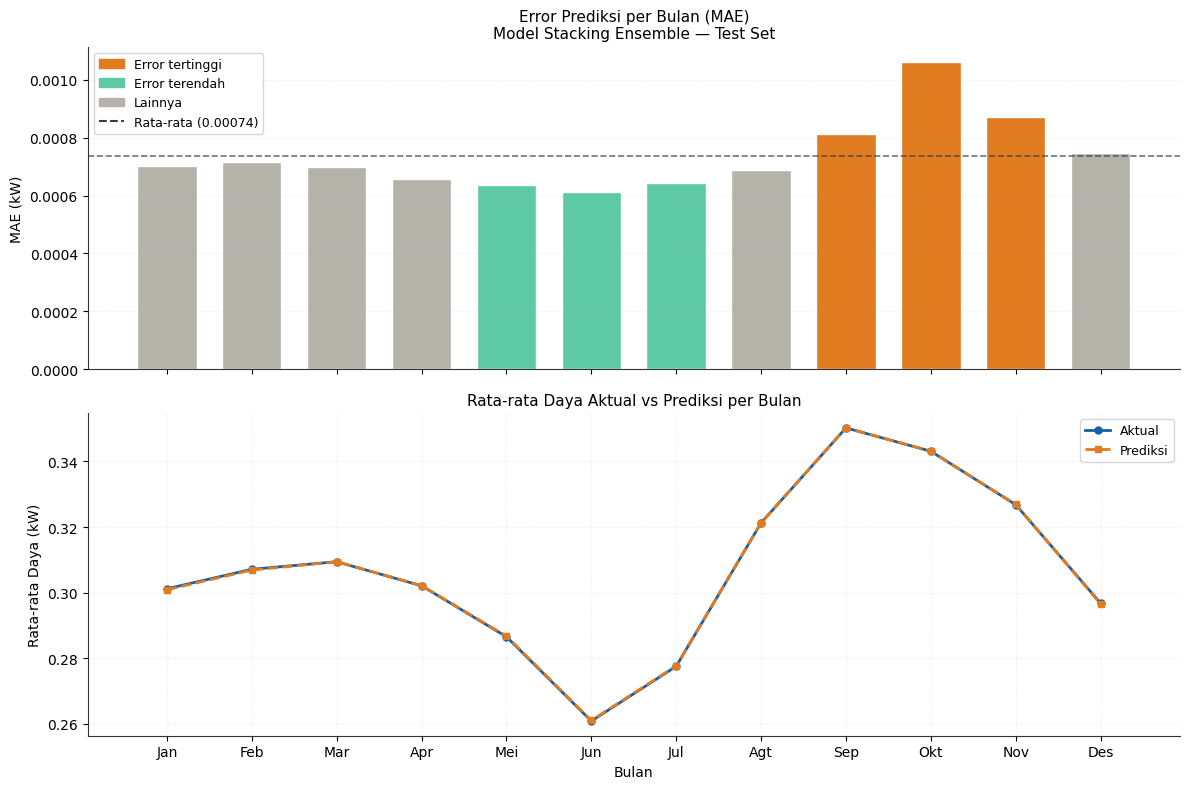

In [ ]:
NAMA_BULAN = {1:'Jan', 2:'Feb', 3:'Mar', 4:'Apr', 5:'Mei',
              6:'Jun', 7:'Jul', 8:'Agt', 9:'Sep', 10:'Okt',
              11:'Nov', 12:'Des'}

# Agregasi per bulan
monthly = df_test.groupby('month').agg(
    mae_per_bulan = ('error', 'mean'),
    daya_aktual   = ('P_kW_actual', 'mean'),
    daya_pred     = ('P_kW_pred', 'mean'),
    n             = ('error', 'count')
).reset_index()

monthly['nama_bulan'] = monthly['month'].map(NAMA_BULAN)
avg_error_m  = monthly['mae_per_bulan'].mean()
bulan_kritis = monthly.nlargest(3, 'mae_per_bulan')['nama_bulan'].tolist()
bulan_stabil = monthly.nsmallest(3, 'mae_per_bulan')['nama_bulan'].tolist()

# Print tabel
print('=' * 55)
print('  SEASONAL ANALYSIS — Error Prediksi per Bulan')
print('=' * 55)
print(f'  {"Bulan":<8} {"MAE":>10} {"Daya Aktual":>13} {"Status":>10}')
print('  ' + '-' * 45)
for _, row in monthly.iterrows():
    if row['nama_bulan'] in bulan_kritis:
        status = ' ◄ TINGGI'
    elif row['nama_bulan'] in bulan_stabil:
        status = ' ◄ STABIL'
    else:
        status = ''
    print(f'  {row["nama_bulan"]:<8} {row["mae_per_bulan"]:>10.5f}'
          f' {row["daya_aktual"]:>13.5f}{status}')

print(f'\n  Rata-rata MAE bulanan : {avg_error_m:.5f}')
print(f'  Bulan error tertinggi : {bulan_kritis}')
print(f'  Bulan paling stabil   : {bulan_stabil}')

# Visualisasi
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

bar_colors_m = ['#E07B20' if n in bulan_kritis
                else '#5DCAA5' if n in bulan_stabil
                else '#B4B2A9'
                for n in monthly['nama_bulan']]

ax1.bar(monthly['nama_bulan'], monthly['mae_per_bulan'],
        color=bar_colors_m, edgecolor='white', width=0.7)
ax1.axhline(avg_error_m, color='#2C3E50', linestyle='--',
            linewidth=1.2, alpha=0.7,
            label=f'Rata-rata ({avg_error_m:.5f})')
ax1.set_ylabel('MAE (kW)', fontsize=10)
ax1.set_title('Error Prediksi per Bulan (MAE)\nModel Stacking Ensemble — Test Set',
              fontsize=11)
ax1.legend(fontsize=9)
ax1.grid(axis='y', alpha=0.25, linestyle=':')
ax1.spines[['top','right']].set_visible(False)

patch_kritis = mpatches.Patch(color='#E07B20', label='Error tertinggi')
patch_stabil = mpatches.Patch(color='#5DCAA5', label='Error terendah')
patch_mid    = mpatches.Patch(color='#B4B2A9', label='Lainnya')
ax1.legend(handles=[patch_kritis, patch_stabil, patch_mid,
                    plt.Line2D([0],[0], color='#2C3E50', linestyle='--',
                                label=f'Rata-rata ({avg_error_m:.5f})')],
           fontsize=9)

ax2.plot(monthly['nama_bulan'], monthly['daya_aktual'],
         color='#185FA5', linewidth=2, marker='o',
         markersize=5, label='Aktual')
ax2.plot(monthly['nama_bulan'], monthly['daya_pred'],
         color='#E07B20', linewidth=2, linestyle='--',
         marker='s', markersize=4, label='Prediksi')
ax2.set_ylabel('Rata-rata Daya (kW)', fontsize=10)
ax2.set_xlabel('Bulan', fontsize=10)
ax2.set_title('Rata-rata Daya Aktual vs Prediksi per Bulan', fontsize=11)
ax2.legend(fontsize=9)
ax2.grid(alpha=0.25, linestyle=':')
ax2.spines[['top','right']].set_visible(False)

plt.tight_layout()
plt.savefig('seasonal_analysis.png', dpi=300, bbox_inches='tight')
plt.show()

### 6.9 Fig. 6: hourly error (a) and inter-hour ramp rate (b)

Rata-rata MAE per jam: 0.00066 kW (harus 0.00066)
Jam error tertinggi : [11, 12, 10] | Jam transisi: [8, 7, 16]


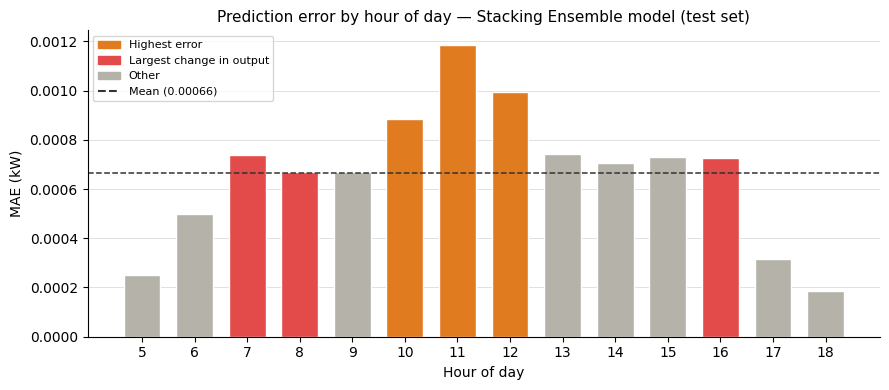

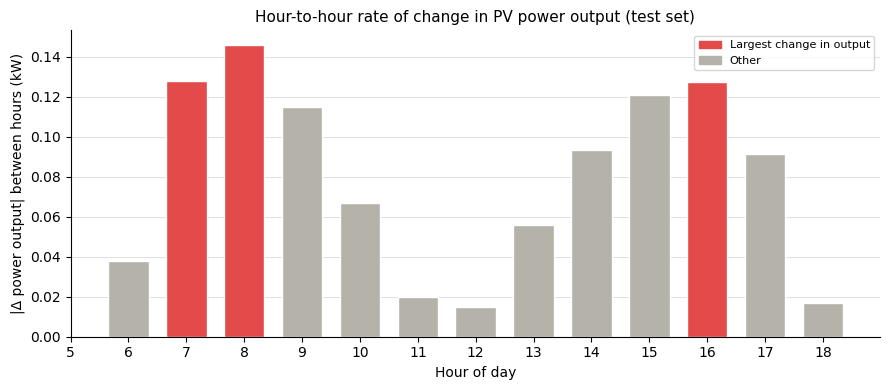

In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import matplotlib.patches as mpatches
try:
    from google.colab import files      # download helper, only available on Colab
except ImportError:
    files = None

# ── Hitung error per jam dalam kW (sama dengan sel "6. Prediksi Jam Kritis") ──
df_test = X_test.copy()
df_test['P_kW_actual'] = y_test.values * P_RANGE_KW + P_MIN_KW                  # kW
df_test['P_kW_pred']   = stacking.predict(X_test) * P_RANGE_KW + P_MIN_KW       # kW
df_test['error']       = (df_test['P_kW_pred'] - df_test['P_kW_actual']).abs()  # kW

hourly = df_test.groupby('hour').agg(
    mae_per_jam  = ('error', 'mean'),
    daya_aktual  = ('P_kW_actual', 'mean'),
    daya_pred    = ('P_kW_pred', 'mean'),
    n            = ('error', 'count')
).reset_index()

avg_error    = hourly['mae_per_jam'].mean()
jam_kritis   = hourly.nlargest(3, 'mae_per_jam')['hour'].tolist()
hourly['delta_daya'] = hourly['daya_aktual'].diff().abs()
jam_transisi = hourly.nlargest(3, 'delta_daya')['hour'].tolist()
print(f'Rata-rata MAE per jam: {avg_error:.5f} kW (harus 0.00066)')
print('Jam error tertinggi :', jam_kritis, '| Jam transisi:', jam_transisi)

# ── Visualisasi (sama dengan sel "8. Profil Operasional") ──
bar_colors_h = []
for h in hourly['hour']:
    if h in jam_kritis:     bar_colors_h.append('#E07B20')
    elif h in jam_transisi: bar_colors_h.append('#E24B4A')
    else:                   bar_colors_h.append('#B4B2A9')

p_kritis    = mpatches.Patch(color='#E07B20', label='Highest error')
p_transisi  = mpatches.Patch(color='#E24B4A', label='Largest change in output')
p_biasa     = mpatches.Patch(color='#B4B2A9', label='Other')
mean_line   = plt.Line2D([0], [0], color='#333333', linestyle='--',
                          label=f'Mean ({avg_error:.5f})')

# ── Fig. 6a — Prediction error by hour of day ──
fig1, ax1 = plt.subplots(figsize=(9, 4))
ax1.bar(hourly['hour'], hourly['mae_per_jam'],
        color=bar_colors_h, edgecolor='white', width=0.7)
ax1.axhline(avg_error, color='#333333', linestyle='--', linewidth=1.1)
ax1.set_ylabel('MAE (kW)', fontsize=10)
ax1.set_xlabel('Hour of day', fontsize=10)
ax1.set_xticks(hourly['hour'])
ax1.set_title('Prediction error by hour of day — Stacking Ensemble model (test set)',
              fontsize=11)
ax1.legend(handles=[p_kritis, p_transisi, p_biasa, mean_line], fontsize=8, loc='upper left')
ax1.grid(axis='y', color='#DADADA', linewidth=0.6)
ax1.set_axisbelow(True)
ax1.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig('fig_error_by_hour.png', dpi=300, bbox_inches='tight')
plt.show()

# ── Fig. 6b — Hour-to-hour rate of change in PV power output ──
p_transisi2 = mpatches.Patch(color='#E24B4A', label='Largest change in output')
p_biasa2    = mpatches.Patch(color='#B4B2A9', label='Other')

fig2, ax2 = plt.subplots(figsize=(9, 4))
ax2.bar(hourly['hour'], hourly['delta_daya'],
        color=['#E24B4A' if h in jam_transisi else '#B4B2A9' for h in hourly['hour']],
        edgecolor='white', width=0.7)
ax2.set_ylabel('|Δ power output| between hours (kW)', fontsize=10)
ax2.set_xlabel('Hour of day', fontsize=10)
ax2.set_xticks(hourly['hour'])
ax2.set_title('Hour-to-hour rate of change in PV power output (test set)', fontsize=11)
ax2.legend(handles=[p_transisi2, p_biasa2], fontsize=8, loc='upper right')
ax2.grid(axis='y', color='#DADADA', linewidth=0.6)
ax2.set_axisbelow(True)
ax2.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig('fig_ramp_rate_by_hour.png', dpi=300, bbox_inches='tight')
plt.show()

if files: files.download('fig_error_by_hour.png')
if files: files.download('fig_ramp_rate_by_hour.png')

### 6.10 Monthly variability of diffuse irradiance versus monthly error

  POLA SEASONAL & VARIABILITAS ATMOSFER
  (Berbasis data primer dan hasil prediksi model)

  [Variabilitas irr_diffuse per bulan]
  Bulan CV tertinggi  (atmosfer tdk menentu) : ['Nov', 'Des', 'Apr']
  Bulan CV terendah   (atmosfer stabil)      : ['Sep', 'Agt', 'Jan']

  [Error model per bulan — dari cell sebelumnya]
  Bulan error tertinggi                      : ['Okt', 'Nov', 'Sep']
  Bulan error terendah                       : ['Jun', 'Mei', 'Jul']

  [Temuan objektif — ada tidaknya korelasi]
  Overlap bulan error tinggi & CV tinggi     : ['Nov'] (1 dari 3 bulan)
  → Kesimpulan ditentukan oleh uji korelasi Pearson di bawah, bukan oleh overlap ini

  [Heatmap CV irr_diffuse — kota x bulan]
  Kota            Jan    Feb    Mar    Apr    Mei    Jun    Jul    Agt    Sep    Okt    Nov    Des
  ------------------------------------------------------------------------------------------------
  Jakarta       0.536  0.538  0.546  0.556  0.582  0.559  0.579  0.539  0.514  0.548  0.609  0.528
  

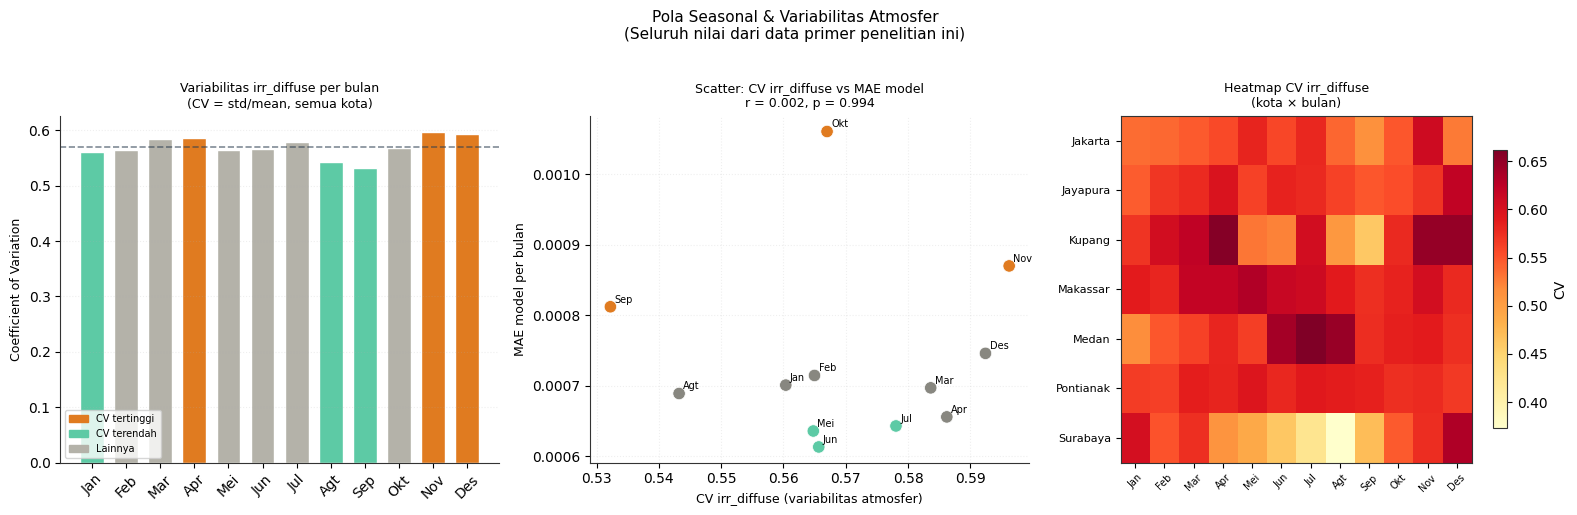

In [ ]:
print('=' * 65)
print('  POLA SEASONAL & VARIABILITAS ATMOSFER')
print('  (Berbasis data primer dan hasil prediksi model)')
print('=' * 65)

# ── Bagian 1: Variabilitas irr_diffuse per bulan per kota ────
diffuse_monthly = df_u.groupby(['city', 'month'])['irr_diffuse'].agg(
    mean='mean', std='std'
).reset_index()
diffuse_monthly['cv'] = (diffuse_monthly['std'] /
                         diffuse_monthly['mean'].replace(0, np.nan))
diffuse_monthly['nama_bulan'] = diffuse_monthly['month'].map(NAMA_BULAN)

# CV rata-rata per bulan (semua kota)
cv_per_bulan = diffuse_monthly.groupby(
    ['month', 'nama_bulan'])['cv'].mean().reset_index()
cv_per_bulan = cv_per_bulan.sort_values('month')

bulan_cv_tinggi = cv_per_bulan.nlargest(3, 'cv')['nama_bulan'].tolist()
bulan_cv_rendah = cv_per_bulan.nsmallest(3, 'cv')['nama_bulan'].tolist()

# ── Bagian 2: Apakah bulan error tinggi = bulan CV tinggi? ───
overlap_kritis = [b for b in bulan_kritis if b in bulan_cv_tinggi]
overlap_stabil = [b for b in bulan_stabil if b in bulan_cv_rendah]

print(f'\n  [Variabilitas irr_diffuse per bulan]')
print(f'  Bulan CV tertinggi  (atmosfer tdk menentu) : {bulan_cv_tinggi}')
print(f'  Bulan CV terendah   (atmosfer stabil)      : {bulan_cv_rendah}')
print(f'\n  [Error model per bulan — dari cell sebelumnya]')
print(f'  Bulan error tertinggi                      : {bulan_kritis}')
print(f'  Bulan error terendah                       : {bulan_stabil}')
print(f'\n  [Temuan objektif — ada tidaknya korelasi]')
print(f'  Overlap bulan error tinggi & CV tinggi     : {overlap_kritis if overlap_kritis else "tidak ada"} ({len(overlap_kritis)} dari 3 bulan)')
print('  → Kesimpulan ditentukan oleh uji korelasi Pearson di bawah, bukan oleh overlap ini')
if overlap_stabil:
    print(f'  Overlap bulan error rendah & CV rendah     : {overlap_stabil}')

# ── Bagian 3: Variabilitas per kota per bulan ────────────────
pivot_cv = diffuse_monthly.pivot(
    index='city', columns='nama_bulan', values='cv'
)
urutan_bulan = ['Jan','Feb','Mar','Apr','Mei','Jun',
                'Jul','Agt','Sep','Okt','Nov','Des']
pivot_cv = pivot_cv.reindex(
    columns=[b for b in urutan_bulan if b in pivot_cv.columns]
)

print(f'\n  [Heatmap CV irr_diffuse — kota x bulan]')
print(f'  {"Kota":<12}', end='')
for b in pivot_cv.columns: print(f' {b:>6}', end='')
print()
print('  ' + '-' * (12 + 7 * len(pivot_cv.columns)))
for kota in pivot_cv.index:
    print(f'  {kota:<12}', end='')
    for b in pivot_cv.columns:
        val = pivot_cv.loc[kota, b]
        print(f' {val:>6.3f}' if pd.notna(val) else f' {"N/A":>6}', end='')
    print()

# ── Visualisasi ──────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

bar_colors_cv = ['#E07B20' if n in bulan_cv_tinggi else
                  '#5DCAA5' if n in bulan_cv_rendah else '#B4B2A9'
                  for n in cv_per_bulan['nama_bulan']]
axes[0].bar(cv_per_bulan['nama_bulan'], cv_per_bulan['cv'],
            color=bar_colors_cv, edgecolor='white', width=0.7)
axes[0].axhline(cv_per_bulan['cv'].mean(),
                color='#2C3E50', linestyle='--', alpha=0.6,
                linewidth=1.2, label='Rata-rata')
axes[0].set_title('Variabilitas irr_diffuse per bulan\n'
                  '(CV = std/mean, semua kota)',
                  fontsize=9)
axes[0].set_ylabel('Coefficient of Variation', fontsize=9)
p1 = mpatches.Patch(color='#E07B20', label='CV tertinggi')
p2 = mpatches.Patch(color='#5DCAA5', label='CV terendah')
p3 = mpatches.Patch(color='#B4B2A9', label='Lainnya')
axes[0].legend(handles=[p1, p2, p3], fontsize=7)
axes[0].tick_params(axis='x', rotation=45)
axes[0].grid(axis='y', alpha=0.2, linestyle=':')
axes[0].spines[['top', 'right']].set_visible(False)

merged = monthly.merge(
    cv_per_bulan[['nama_bulan', 'cv']],
    on='nama_bulan', how='left'
)
sc_colors = ['#E07B20' if n in bulan_kritis else
              '#5DCAA5' if n in bulan_stabil else '#888780'
              for n in merged['nama_bulan']]
sc = axes[1].scatter(merged['cv'], merged['mae_per_bulan'],
                     c=sc_colors, s=80, edgecolors='white', linewidths=0.5,
                     zorder=3)
for _, row in merged.iterrows():
    axes[1].annotate(row['nama_bulan'],
                     (row['cv'], row['mae_per_bulan']),
                     fontsize=7, ha='left',
                     xytext=(3, 3), textcoords='offset points')

from scipy import stats
mask = merged['cv'].notna() & merged['mae_per_bulan'].notna()
if mask.sum() > 2:
    r, p_val = stats.pearsonr(merged.loc[mask, 'cv'],
                               merged.loc[mask, 'mae_per_bulan'])
    axes[1].set_title(f'Scatter: CV irr_diffuse vs MAE model\n'
                      f'r = {r:.3f}, p = {p_val:.3f}', fontsize=9)
    print(f'\n  [Korelasi Pearson CV irr_diffuse vs MAE model]')
    print(f'  r = {r:.3f},  p-value = {p_val:.3f}')
    if p_val < 0.05:
        print(f'  → Korelasi signifikan: variabilitas atmosfer '
              f'berpengaruh nyata terhadap error model')
    else:
        print(f'  → Korelasi tidak signifikan secara statistik (p > 0.05)')
        print(f'  → Error model tidak semata-mata dijelaskan oleh variabilitas atmosfer')
else:
    axes[1].set_title('Scatter: CV irr_diffuse vs MAE model', fontsize=9)

axes[1].set_xlabel('CV irr_diffuse (variabilitas atmosfer)', fontsize=9)
axes[1].set_ylabel('MAE model per bulan', fontsize=9)
axes[1].grid(alpha=0.2, linestyle=':')
axes[1].spines[['top', 'right']].set_visible(False)

import matplotlib.colors as mcolors
cmap = plt.get_cmap('YlOrRd')
im   = axes[2].imshow(pivot_cv.values, cmap=cmap,
                       aspect='auto', interpolation='nearest')
axes[2].set_xticks(range(len(pivot_cv.columns)))
axes[2].set_xticklabels(pivot_cv.columns, fontsize=7, rotation=45)
axes[2].set_yticks(range(len(pivot_cv.index)))
axes[2].set_yticklabels(pivot_cv.index, fontsize=8)
axes[2].set_title('Heatmap CV irr_diffuse\n(kota × bulan)', fontsize=9)
plt.colorbar(im, ax=axes[2], shrink=0.8, label='CV')

fig.suptitle(
    'Pola Seasonal & Variabilitas Atmosfer\n'
    '(Seluruh nilai dari data primer penelitian ini)',
    fontsize=11, y=1.02
)
plt.tight_layout()
plt.savefig('cell_c_seasonal_variabilitas.png', dpi=150, bbox_inches='tight')
plt.show()

## 7. Software versions

In [ ]:
import sys, platform
from importlib.metadata import version

print('Python', sys.version.split()[0], '|', platform.platform())
for pkg in ['numpy', 'pandas', 'scipy', 'scikit-learn', 'xgboost', 'lightgbm',
            'bayesian-optimization', 'shap', 'matplotlib', 'seaborn', 'psutil']:
    try:
        print(f'{pkg:<24}{version(pkg)}')
    except Exception:
        print(f'{pkg:<24}(tidak terpasang)')
print('Seed split/model utama:', 42, '| seed multi-seed:', SEEDS)

Python 3.13.16 | Linux-6.6.122+-x86_64-with-glibc2.39
numpy                   2.1.3
pandas                  2.2.3
scipy                   1.16.3
scikit-learn            1.6.1
xgboost                 3.4.1
lightgbm                4.6.0
bayesian-optimization   (tidak terpasang)
shap                    0.52.0
matplotlib              3.10.0
seaborn                 0.13.2
psutil                  5.9.5
Seed split/model utama: 42 | seed multi-seed: [42, 43, 44, 45, 46]
